# Plausible but Wrong: Silent Analytical Errors in LLM-Generated Charts

Juliet Uyo Ukwella · October 2026

A pilot study of how often ChatGPT turns an underspecified data question into a chart that runs and looks correct but answers the question misleadingly. Each question was asked in a new ChatGPT chat (free plan, default model, Think off, Memory off), and the code it returned is run below exactly as written.

## 1. Data

Our World in Data COVID-19 dataset (final version, data to August 2024).

In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/owid/covid-19-data/master/public/data/owid-covid-data.csv"
df = pd.read_csv(url)
df.to_csv("owid-covid-data.csv", index=False)
print(df.shape, df["date"].max())

(429435, 67) 2024-08-14


## 2. Baseline results

### T01. Which countries were hit hardest by COVID-19 deaths? Show me the top 10.

Hidden choice: total deaths or deaths per person; whether regional and income-group rows count as countries.

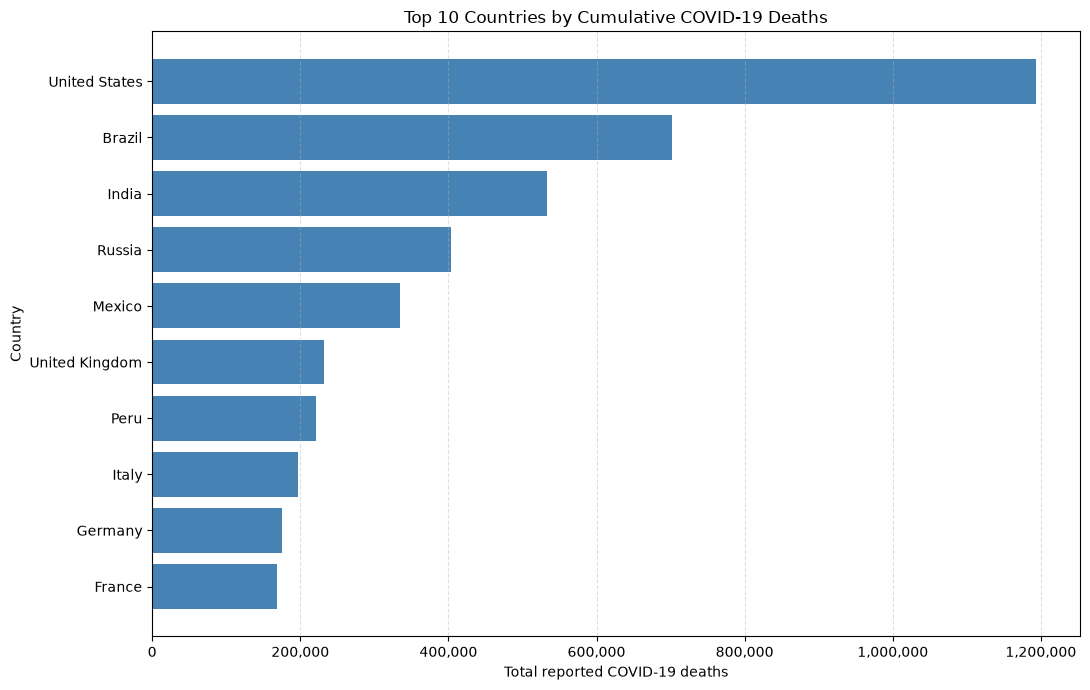

      location       date  total_deaths
 United States 2024-08-04     1193165.0
        Brazil 2024-08-04      702116.0
         India 2024-08-04      533623.0
        Russia 2024-08-04      403188.0
        Mexico 2024-08-04      334551.0
United Kingdom 2024-08-04      232112.0
          Peru 2024-08-04      220975.0
         Italy 2024-08-04      197307.0
       Germany 2024-08-04      174979.0
        France 2024-08-04      168091.0


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the Our World in Data COVID-19 dataset
df = pd.read_csv("owid-covid-data.csv")

# Convert date to datetime
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Keep rows with valid country codes and death counts
df = df[
    df["iso_code"].str.startswith(("OWID_"), na=False) == False
].copy()

df = df.dropna(subset=["date", "total_deaths"])

# Get the latest available record for each country
latest = (
    df.sort_values("date")
      .groupby("location", as_index=False)
      .tail(1)
)

# Select the 10 countries with the highest cumulative deaths
top10 = (
    latest.nlargest(10, "total_deaths")
          .sort_values("total_deaths", ascending=True)
)

# Plot the results
plt.figure(figsize=(11, 7))

plt.barh(
    top10["location"],
    top10["total_deaths"],
    color="steelblue"
)

plt.xlabel("Total reported COVID-19 deaths")
plt.ylabel("Country")
plt.title("Top 10 Countries by Cumulative COVID-19 Deaths")
plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:,.0f}")
)

plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# Print the rankings and death counts
print(
    top10[["location", "date", "total_deaths"]]
    .sort_values("total_deaths", ascending=False)
    .to_string(index=False)
)

**Assessment: Flagged analytical error.** ChatGPT ranked countries by total deaths, so the chart mainly reflects population size: India ranks 3rd despite the lowest death rate of the ten (374 per million), while Peru, the hardest-hit country per person (6,601 per million), ranks 7th. Its answer presented total deaths as the way to identify the hardest-hit countries and mentioned deaths per million only in a closing note. Regional and income-group rows were correctly excluded.

### T02. Make a chart comparing how badly COVID affected the countries of South America.

Hidden choice: total deaths or deaths per person.

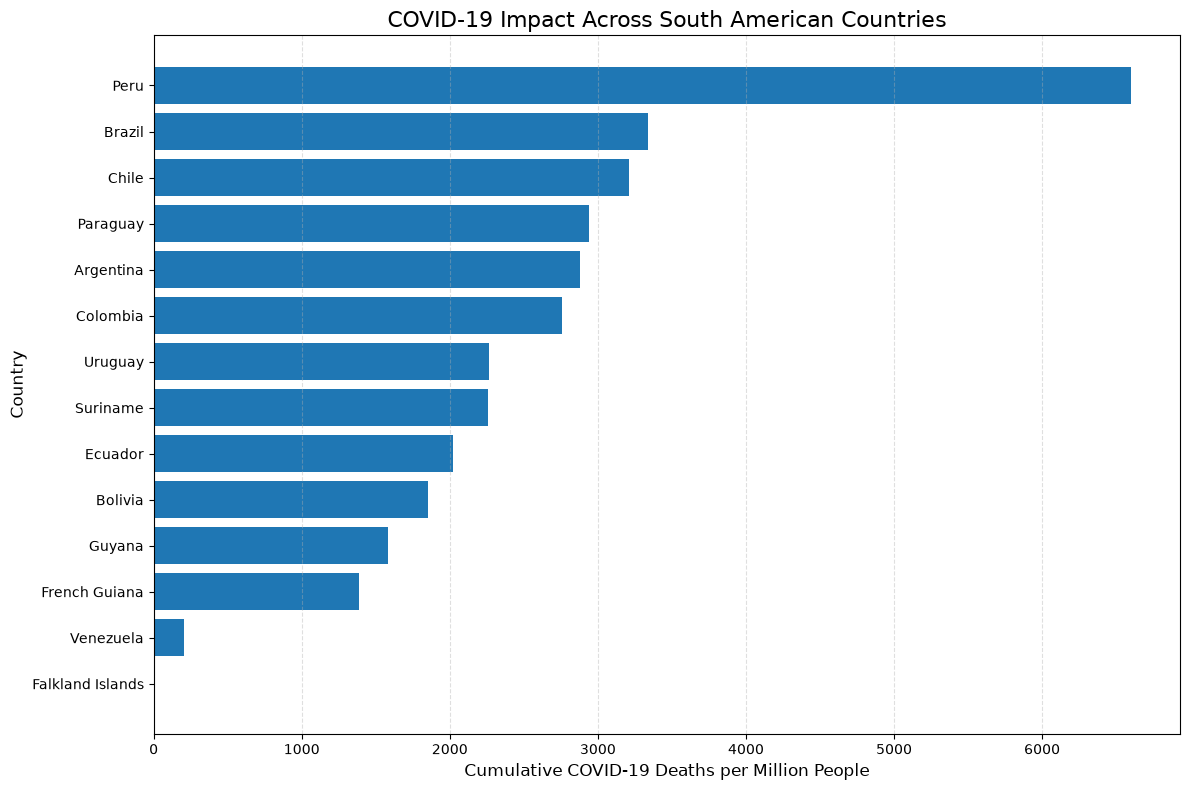

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the COVID-19 dataset
df = pd.read_csv("owid-covid-data.csv")

# 2. Convert the date column to datetime format
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# 3. Select countries in South America
south_america = df[df["continent"] == "South America"].copy()

# 4. Sort by date and remove rows with missing death-rate data
south_america = south_america.sort_values("date")
south_america = south_america.dropna(
    subset=["total_deaths_per_million"]
)

# 5. Get the latest available cumulative deaths per million
latest = south_america.groupby("location").tail(1)

# 6. Sort countries from lowest to highest death rate
latest = latest.sort_values("total_deaths_per_million")

# 7. Create the horizontal bar chart
plt.figure(figsize=(12, 8))

plt.barh(
    latest["location"],
    latest["total_deaths_per_million"]
)

plt.title(
    "COVID-19 Impact Across South American Countries",
    fontsize=16
)
plt.xlabel("Cumulative COVID-19 Deaths per Million People", fontsize=12)
plt.ylabel("Country", fontsize=12)

plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()

# 8. Display the chart
plt.show()


**Assessment: Valid – choice stated.** ChatGPT plotted deaths per million and explained that this adjusts for population size; it also cautioned that testing and reporting differ between countries. The chart includes two territories (French Guiana and the Falkland Islands) although the question asked about countries.

### T03. Which African countries were most affected by COVID?

Hidden choice: total or per-person measures; cases or deaths; how to treat very small populations.

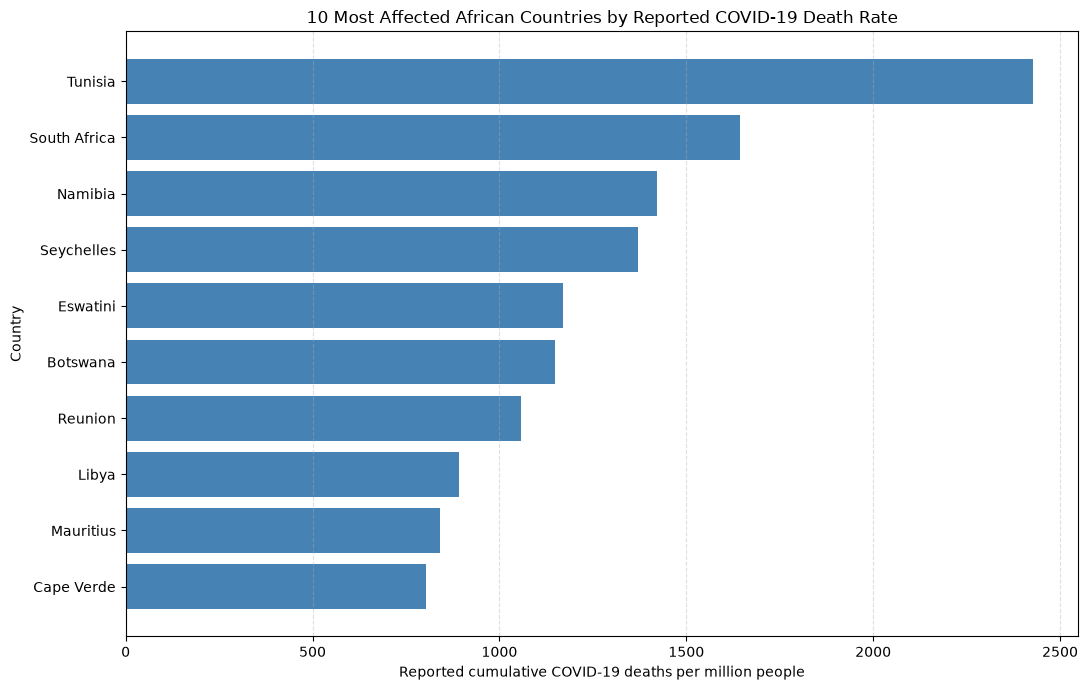

Top 10 African countries by reported COVID-19 deaths per million:
    location       date  total_deaths_per_million
     Tunisia 2024-08-04                   2427.77
South Africa 2024-08-04                   1644.72
     Namibia 2024-08-04                   1421.62
  Seychelles 2024-08-04                   1370.17
    Eswatini 2024-08-04                   1170.71
    Botswana 2024-08-04                   1148.00
     Reunion 2024-08-04                   1056.75
       Libya 2024-08-04                    891.08
   Mauritius 2024-08-04                    840.82
  Cape Verde 2024-08-04                    802.31


In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the COVID-19 dataset
df = pd.read_csv("owid-covid-data.csv")
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# 2. Keep African countries and exclude OWID regional aggregates
africa = df[
    (df["continent"] == "Africa") &
    (~df["iso_code"].str.startswith("OWID_", na=False))
].copy()

# 3. Get the latest available reported death rate for each country
deaths = africa.dropna(subset=["total_deaths_per_million"])
latest_deaths = (
    deaths.sort_values("date")
    .drop_duplicates(subset="location", keep="last")
)

# 4. Select the 10 countries with the highest deaths per million
top10 = latest_deaths.nlargest(10, "total_deaths_per_million")
top10 = top10.sort_values("total_deaths_per_million")

# 5. Plot a horizontal bar chart
plt.figure(figsize=(11, 7))

plt.barh(
    top10["location"],
    top10["total_deaths_per_million"],
    color="steelblue"
)

plt.xlabel("Reported cumulative COVID-19 deaths per million people")
plt.ylabel("Country")
plt.title("10 Most Affected African Countries by Reported COVID-19 Death Rate")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.show()

# 6. Print the ranking and latest available data dates
print("Top 10 African countries by reported COVID-19 deaths per million:")
print(
    top10[
        ["location", "date", "total_deaths_per_million"]
    ].sort_values("total_deaths_per_million", ascending=False)
    .to_string(index=False)
)


**Assessment: Valid – choice stated.** ChatGPT ranked African countries by deaths per million, explaining that a per-person measure adjusts for population size, and warned that reported deaths may undercount the true toll; regional and income-group rows were excluded. Tunisia ranks highest (2,428 per million), followed by South Africa and Namibia. Two points were not mentioned: Seychelles ranks fourth largely because its population is very small (172 deaths among about 107,000 people), and Réunion, a French overseas territory rather than a country, is included.

### T04. Show the 10 countries with the most COVID cases.

Hidden choice: whether World, continent and income-group rows count as countries.

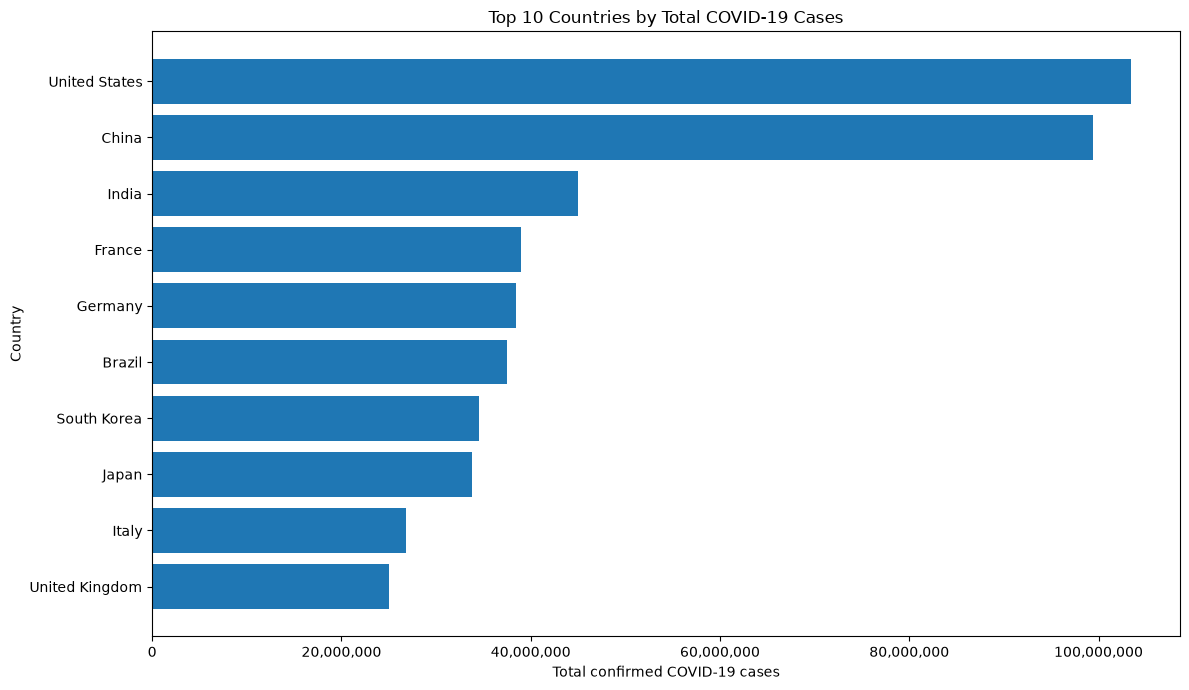

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the COVID-19 dataset
df = pd.read_csv("owid-covid-data.csv")

# Keep country rows, excluding continents and other aggregate locations
df = df[~df["iso_code"].str.startswith("OWID_", na=False)]

# Find the latest recorded total_cases value for each country
df["date"] = pd.to_datetime(df["date"])
latest_cases = (
    df.sort_values("date")
      .groupby("location", as_index=False)
      .last()[["location", "total_cases"]]
)

# Remove rows with missing case counts
latest_cases = latest_cases.dropna(subset=["total_cases"])

# Select the 10 countries with the most total cases
top_10 = latest_cases.nlargest(10, "total_cases")
top_10 = top_10.sort_values("total_cases", ascending=True)

# Create a horizontal bar chart
plt.figure(figsize=(12, 7))
plt.barh(top_10["location"], top_10["total_cases"])

plt.xlabel("Total confirmed COVID-19 cases")
plt.ylabel("Country")
plt.title("Top 10 Countries by Total COVID-19 Cases")
plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:,.0f}")
)

plt.tight_layout()
plt.show()


**Assessment: Valid – choice stated.** Totals are appropriate for a question about the most cases. ChatGPT removed the World, continent and income-group rows using the OWID_ code prefix and said so in its answer.

### T05. How many people died of COVID in each continent? Show it as a bar chart.

Hidden choice: how to total a running (cumulative) count; whether to add up countries or use the continent rows.

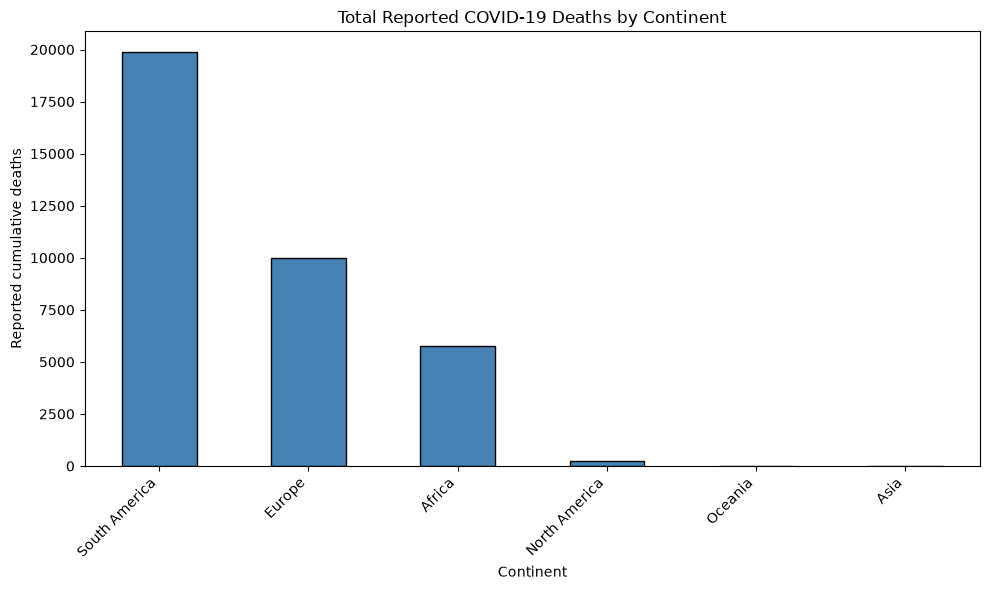

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the COVID-19 dataset
df = pd.read_csv("owid-covid-data.csv")

# Convert date column to datetime
df["date"] = pd.to_datetime(df["date"])

# Keep rows with a known continent and recorded total deaths
df = df.dropna(subset=["continent", "total_deaths"])

# Get the latest recorded cumulative deaths for each continent
latest_deaths = (
    df.sort_values("date")
      .groupby("continent")
      .tail(1)
      .set_index("continent")["total_deaths"]
      .sort_values(ascending=False)
)

# Create a bar chart
plt.figure(figsize=(10, 6))
latest_deaths.plot(kind="bar", color="steelblue", edgecolor="black")

plt.title("Total Reported COVID-19 Deaths by Continent")
plt.xlabel("Continent")
plt.ylabel("Reported cumulative deaths")
plt.xticks(rotation=45, ha="right")
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()

# Display the chart
plt.show()

**Assessment: Silent analytical error.** Instead of adding up the countries in each continent, the code takes the single last row in each continent, which is one country's figure: the "South America" bar is Paraguay alone (19,880), "Europe" is North Macedonia (9,978), and "Asia" is North Korea (0). The chart therefore shows Asia with no COVID deaths, when the true continental totals range from about 33,000 (Oceania) to 2.1 million (Europe). ChatGPT's answer explained that it avoided double-counting the cumulative column, and gave no warning about this error.

### T06. What share of people in Africa were fully vaccinated against COVID?

Hidden choice: share of all people (weighted by population) or the average of country percentages; how to handle countries that report on different dates.

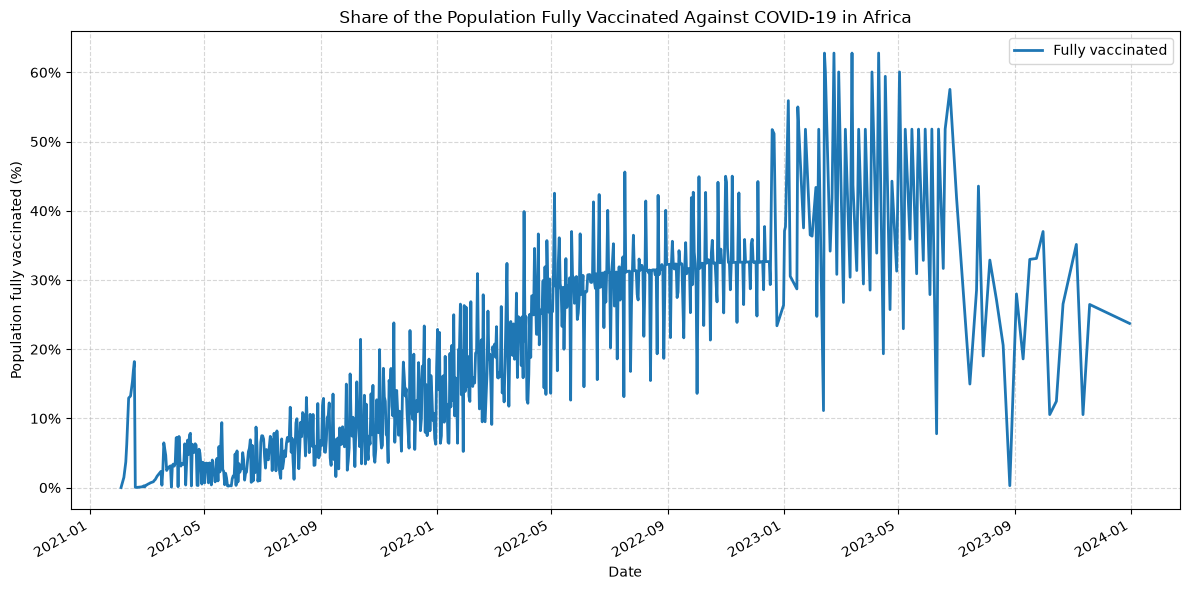

Latest date: 2023-12-31
Share fully vaccinated: 23.72%


In [7]:

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Load the COVID-19 dataset
df = pd.read_csv("owid-covid-data.csv", parse_dates=["date"])

# Filter for countries in Africa
africa = df[df["continent"] == "Africa"].copy()

# Keep records with available vaccination and population data
africa = africa.dropna(
    subset=["people_fully_vaccinated", "population"]
)

# Aggregate fully vaccinated people and population by date
daily = (
    africa.groupby("date")
    .agg(
        fully_vaccinated=("people_fully_vaccinated", "sum"),
        population=("population", "sum")
    )
    .sort_index()
)

# Calculate the percentage fully vaccinated
daily["fully_vaccinated_share"] = (
    daily["fully_vaccinated"] / daily["population"] * 100
)

# Plot the results
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    daily.index,
    daily["fully_vaccinated_share"],
    linewidth=2,
    label="Fully vaccinated"
)

ax.set_title(
    "Share of the Population Fully Vaccinated Against COVID-19 in Africa"
)
ax.set_xlabel("Date")
ax.set_ylabel("Population fully vaccinated (%)")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

# Print the latest available estimate
latest = daily.dropna(subset=["fully_vaccinated_share"]).iloc[-1]

print(f"Latest date: {latest.name.strftime('%Y-%m-%d')}")
print(
    f"Share fully vaccinated: "
    f"{latest['fully_vaccinated_share']:.2f}%"
)

**Assessment: Flagged analytical error.** ChatGPT correctly added people and populations rather than averaging country percentages, but on each date it included only the countries that reported that day, typically about five of Africa's 54 and a different set each time. The line therefore swings between almost 0% and 62.8%, and the final figure it reports (23.7%, from four countries) differs from Africa's actual share of 32.4%. Its answer warned that the set of reporting countries "may vary over time" and called the result an estimate, but did not convey how few countries each point represents.

### T07. Were there more COVID deaths in the United States in 2021 or in 2022? Make a chart.

Hidden choice: deaths during each year, or the running total at the end of each year.

Reported COVID-19 deaths in the United States:
2021: 469,667
2022: 267,389

There were more reported COVID-19 deaths in 2021.


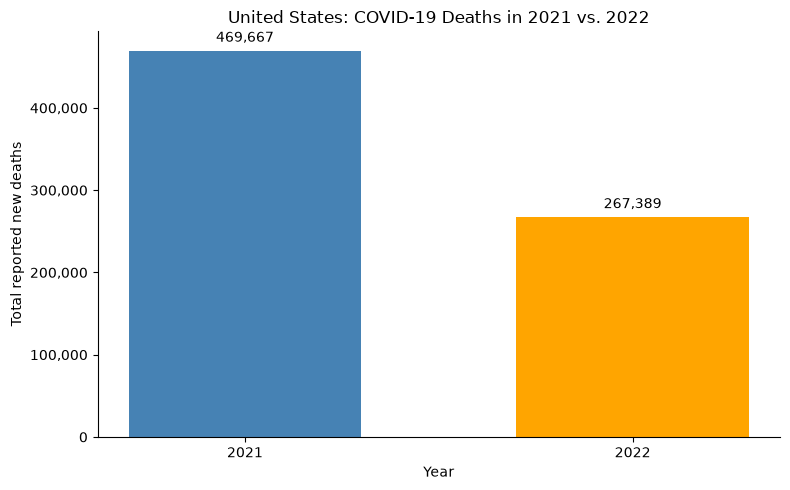

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("owid-covid-data.csv", parse_dates=["date"])

# Filter for the United States
us = df[df["location"] == "United States"].copy()

# Ensure deaths are numeric
us["new_deaths"] = pd.to_numeric(us["new_deaths"], errors="coerce")

# Keep only 2021 and 2022
us = us[us["date"].dt.year.isin([2021, 2022])].copy()
us["year"] = us["date"].dt.year

# Calculate total reported deaths for each year
annual_deaths = (
    us.groupby("year")["new_deaths"]
    .sum(min_count=1)
    .reindex([2021, 2022])
)

# Print the totals and identify the year with more deaths
print("Reported COVID-19 deaths in the United States:")
for year, deaths in annual_deaths.items():
    print(f"{year}: {deaths:,.0f}")

if annual_deaths.notna().all():
    higher_year = annual_deaths.idxmax()
    print(f"\nThere were more reported COVID-19 deaths in {higher_year}.")

# Create the bar chart
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    annual_deaths.index.astype(str),
    annual_deaths.values,
    color=["steelblue", "orange"],
    width=0.6
)

# Add labels above the bars
ax.bar_label(bars, labels=[
    f"{value:,.0f}" if pd.notna(value) else "No data"
    for value in annual_deaths.values
], padding=4)

ax.set_title("United States: COVID-19 Deaths in 2021 vs. 2022")
ax.set_xlabel("Year")
ax.set_ylabel("Total reported new deaths")
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:,.0f}")
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

**Assessment: Valid – choice stated.** ChatGPT summed new deaths within each calendar year (2021: 469,667; 2022: 267,389) and correctly concluded that 2021 had more deaths. It explained that the cumulative total_deaths column should not be used for this comparison; using year-end running totals would have reversed the answer.

### T08. Plot how COVID deaths changed over time in Italy.

Hidden choice: running total or deaths per period; how to handle deaths that are reported weekly.

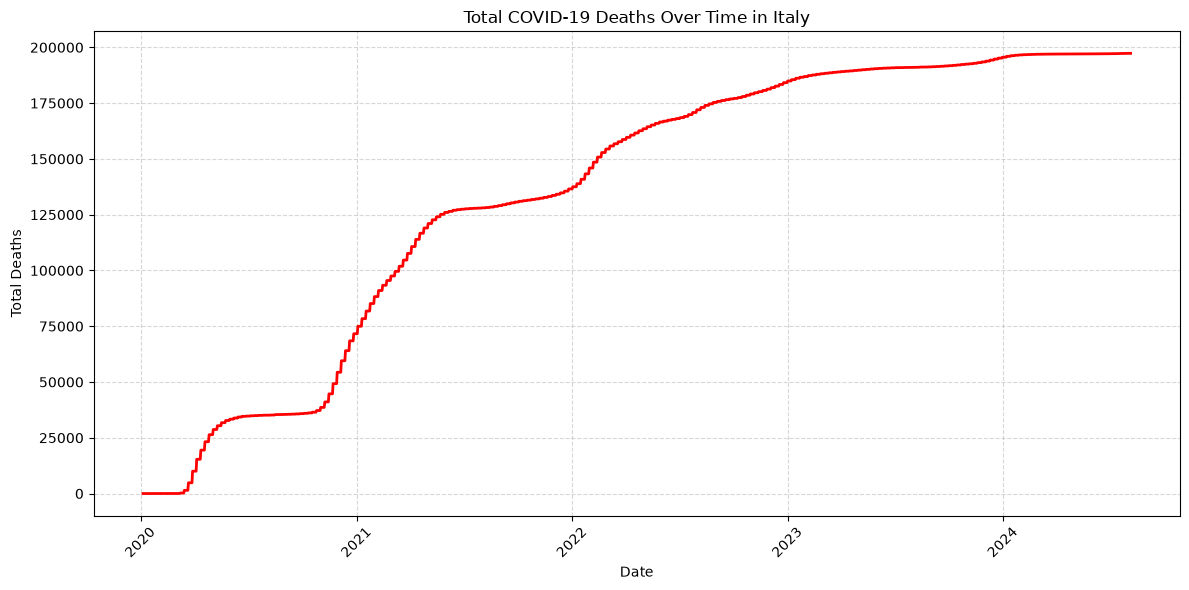

In [9]:

import pandas as pd
import matplotlib.pyplot as plt

# Load the COVID-19 dataset
df = pd.read_csv("owid-covid-data.csv")

# Filter the data for Italy
italy = df[df["location"] == "Italy"].copy()

# Convert dates to datetime format and sort chronologically
italy["date"] = pd.to_datetime(italy["date"])
italy = italy.sort_values("date")

# Plot total COVID-19 deaths over time
plt.figure(figsize=(12, 6))
plt.plot(italy["date"], italy["total_deaths"], color="red", linewidth=2)

# Add chart labels and title
plt.title("Total COVID-19 Deaths Over Time in Italy")
plt.xlabel("Date")
plt.ylabel("Total Deaths")
plt.grid(True, linestyle="--", alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()

# Display the chart
plt.show()


**Assessment: Flagged analytical error.** ChatGPT plotted cumulative deaths, which can only rise, so the successive waves of the pandemic in Italy appear only as changes in slope rather than as peaks and falls. Its answer noted that the series is cumulative and suggested new_deaths for "new deaths per day"; however, in this dataset new_deaths are weekly totals recorded on Sundays, so following that suggestion would itself produce a misleading chart of weekly spikes separated by zeros.

### T09. Did COVID deaths in the United Kingdom fall after vaccines were rolled out?

Hidden choice: running total or deaths per period; when vaccination started.

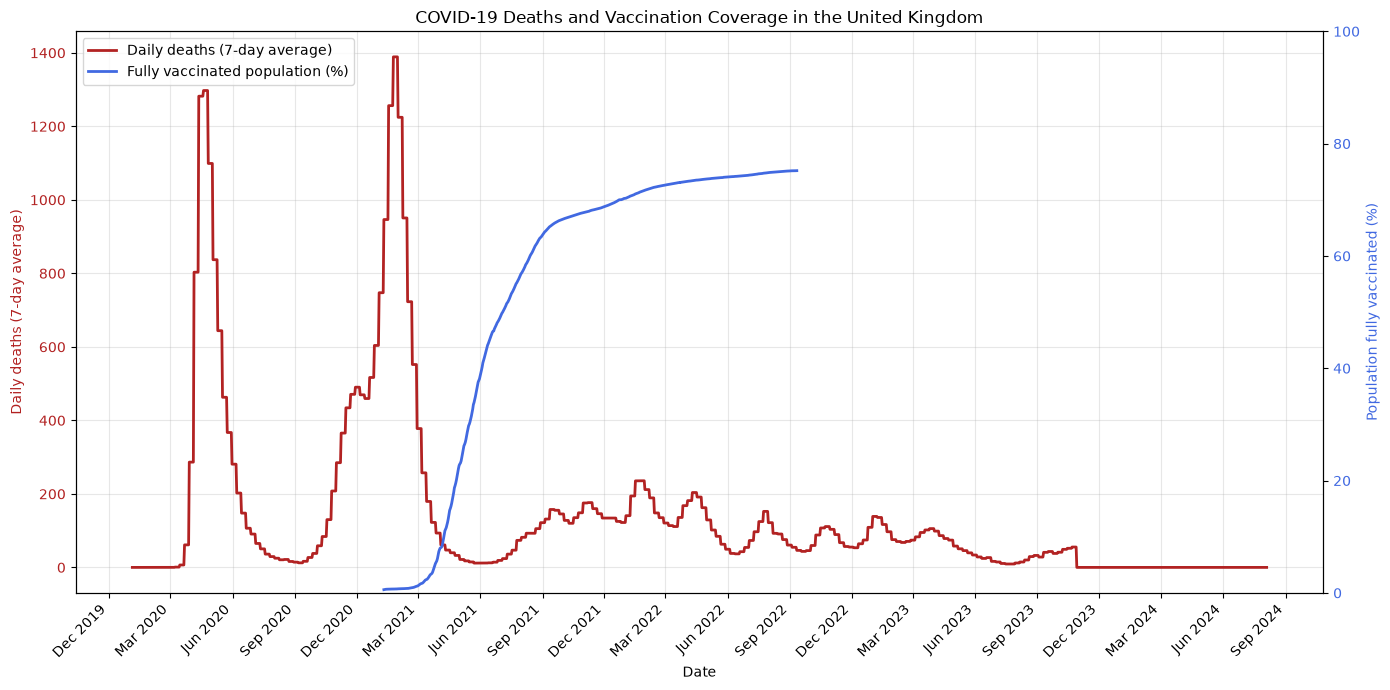

In [10]:

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Load the dataset
df = pd.read_csv("owid-covid-data.csv")

# Convert date column to datetime
df["date"] = pd.to_datetime(df["date"])

# Filter data for the United Kingdom
uk = df[df["location"] == "United Kingdom"].copy()
uk = uk.sort_values("date")

# Calculate the 7-day rolling average of daily deaths
uk["deaths_7day_avg"] = uk["new_deaths"].rolling(
    window=7, min_periods=1
).mean()

# Use vaccination coverage (% of population fully vaccinated)
uk["vaccination_pct"] = uk["people_fully_vaccinated_per_hundred"]

# Create the chart
fig, ax1 = plt.subplots(figsize=(14, 7))

# Plot daily deaths on the first y-axis
ax1.plot(
    uk["date"],
    uk["deaths_7day_avg"],
    color="firebrick",
    linewidth=2,
    label="Daily deaths (7-day average)"
)
ax1.set_xlabel("Date")
ax1.set_ylabel("Daily deaths (7-day average)", color="firebrick")
ax1.tick_params(axis="y", labelcolor="firebrick")
ax1.grid(True, alpha=0.3)

# Plot vaccination coverage on the second y-axis
ax2 = ax1.twinx()
ax2.plot(
    uk["date"],
    uk["vaccination_pct"],
    color="royalblue",
    linewidth=2,
    label="Fully vaccinated population (%)"
)
ax2.set_ylabel("Population fully vaccinated (%)", color="royalblue")
ax2.tick_params(axis="y", labelcolor="royalblue")
ax2.set_ylim(0, 100)

# Format the x-axis
ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.setp(ax1.get_xticklabels(), rotation=45, ha="right")

# Combine legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.title(
    "COVID-19 Deaths and Vaccination Coverage in the United Kingdom"
)
fig.tight_layout()
plt.show()


**Assessment: Valid – choice stated.** ChatGPT plotted a 7-day average of new deaths alongside the share of people fully vaccinated. Because each 7-day window contains exactly one weekly report, this average matches the dataset's own smoothed series. The chart shows deaths falling from about 1,400 per day in January 2021 to under 20 by mid-May 2021 as vaccination rose, then rising again in later waves to a much lower level. The answer cautioned that the chart shows a relationship over time, not proof of cause. Two limitations were not mentioned: the UK stopped reporting deaths to this dataset after 22 October 2023, and the file records the gap as zeros, so the chart wrongly suggests deaths fell to zero from November 2023; and the chart uses two y-axes, a design the visualisation literature lists as potentially misleading.

### T10. On which single day did the most people die of COVID in the United States?

Hidden choice: whether the "daily" figures are really daily.

Peak day: 2021-01-17
Reported new deaths: 23,312


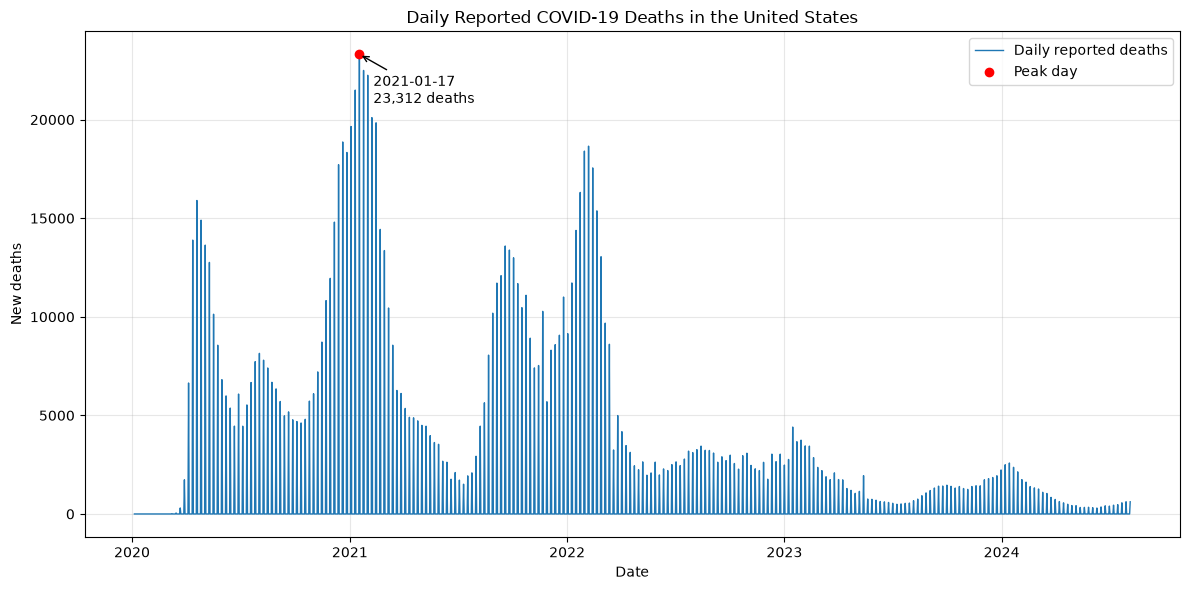

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("owid-covid-data.csv")

# Convert date to datetime
df["date"] = pd.to_datetime(df["date"])

# Filter data for the United States
us = df[df["location"] == "United States"].copy()

# Remove rows where daily deaths are missing
us = us.dropna(subset=["new_deaths"])

# Find the day with the highest reported daily deaths
peak_idx = us["new_deaths"].idxmax()
peak_day = us.loc[peak_idx, "date"]
peak_deaths = us.loc[peak_idx, "new_deaths"]

# Print the answer
print(f"Peak day: {peak_day.strftime('%Y-%m-%d')}")
print(f"Reported new deaths: {peak_deaths:,.0f}")

# Plot daily COVID-19 deaths
plt.figure(figsize=(12, 6))
plt.plot(us["date"], us["new_deaths"], linewidth=1, label="Daily reported deaths")

# Highlight the peak
plt.scatter(peak_day, peak_deaths, color="red", zorder=3, label="Peak day")
plt.annotate(
    f"{peak_day.strftime('%Y-%m-%d')}\n{peak_deaths:,.0f} deaths",
    xy=(peak_day, peak_deaths),
    xytext=(10, -35),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->"),
)

plt.title("Daily Reported COVID-19 Deaths in the United States")
plt.xlabel("Date")
plt.ylabel("New deaths")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Assessment: Silent analytical error.** ChatGPT reported 17 January 2021 as the single deadliest day, with 23,312 deaths. In this dataset, however, US deaths are recorded once a week, on Sundays, with zeros on the other days, so 23,312 is the total for the week ending 17 January (about 3,330 per day), and no single peak day can be identified. The answer's caveat mentioned reporting delays and revisions but not the weekly aggregation, so the roughly sevenfold overstatement goes unflagged.

### T11. What percentage of the population is vaccinated in each G7 country?

Hidden choice: doses per hundred people, or the share of people vaccinated.

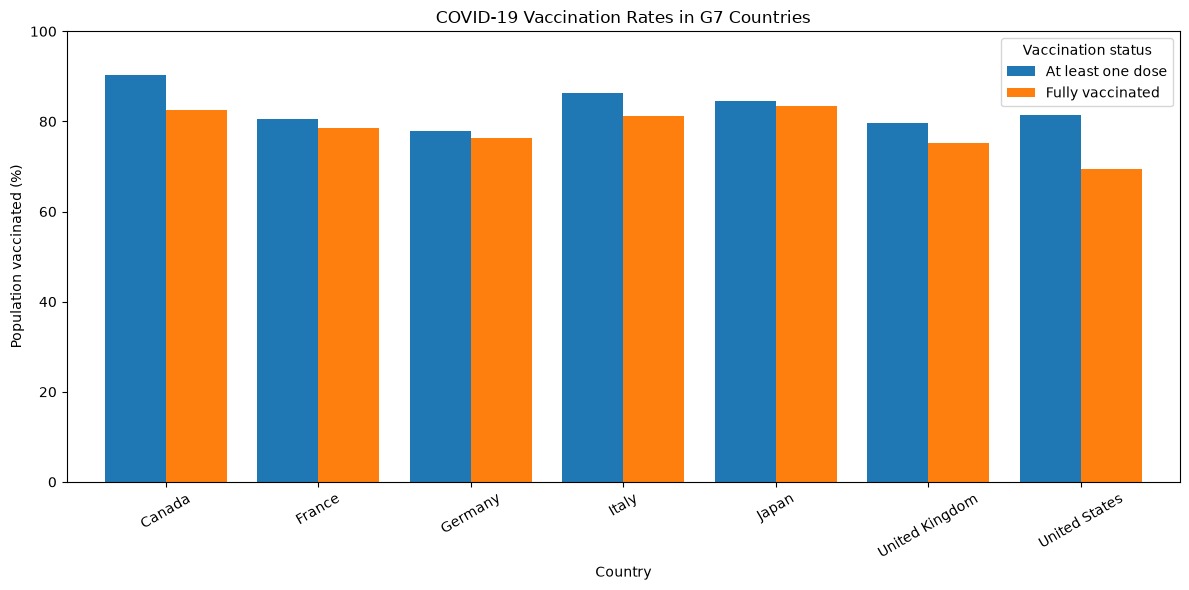

       Country Vaccination status  Percentage       Date
        Canada  At least one dose       90.35 2023-01-25
        Canada   Fully vaccinated       82.59 2023-01-25
        France  At least one dose       80.63 2023-07-10
        France   Fully vaccinated       78.44 2023-07-10
       Germany  At least one dose       77.82 2023-04-07
       Germany   Fully vaccinated       76.24 2023-04-07
         Italy  At least one dose       86.28 2023-11-16
         Italy   Fully vaccinated       81.21 2023-11-16
         Japan  At least one dose       84.47 2023-05-07
         Japan   Fully vaccinated       83.40 2023-05-07
United Kingdom  At least one dose       79.71 2022-09-11
United Kingdom   Fully vaccinated       75.19 2022-09-11
 United States  At least one dose       81.39 2023-05-09
 United States   Fully vaccinated       69.47 2023-05-09


In [12]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the COVID-19 dataset
df = pd.read_csv("owid-covid-data.csv", parse_dates=["date"])

# List of G7 countries
g7_countries = [
    "Canada",
    "France",
    "Germany",
    "Italy",
    "Japan",
    "United Kingdom",
    "United States"
]

# Vaccination metrics and their chart labels
vaccination_metrics = {
    "people_vaccinated_per_hundred": "At least one dose",
    "people_fully_vaccinated_per_hundred": "Fully vaccinated"
}

# Filter the data to include only G7 countries
g7_data = df[df["location"].isin(g7_countries)]

# Get the latest available non-missing value for each country and metric
latest_records = []

for country in g7_countries:
    country_data = g7_data[g7_data["location"] == country]

    for column, label in vaccination_metrics.items():
        available = country_data[["date", column]].dropna(subset=[column])

        if not available.empty:
            latest = available.loc[available["date"].idxmax()]

            latest_records.append({
                "Country": country,
                "Vaccination status": label,
                "Percentage": latest[column],
                "Date": latest["date"]
            })

# Convert the results to a DataFrame
latest_df = pd.DataFrame(latest_records)

# Arrange the data for plotting
chart_data = latest_df.pivot(
    index="Country",
    columns="Vaccination status",
    values="Percentage"
)

chart_data = chart_data.reindex(g7_countries)
chart_data = chart_data.reindex(
    columns=["At least one dose", "Fully vaccinated"]
)

# Create the grouped bar chart
ax = chart_data.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title("COVID-19 Vaccination Rates in G7 Countries")
ax.set_xlabel("Country")
ax.set_ylabel("Population vaccinated (%)")
ax.set_ylim(0, 100)
ax.legend(title="Vaccination status")
ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

# Print values and the dates they were reported
print(
    latest_df.sort_values(["Country", "Vaccination status"])
    .to_string(index=False)
)

**Assessment: Valid – choice stated.** ChatGPT used the share of people with at least one dose and the share fully vaccinated, rather than doses per hundred people (which exceed 100 because most people received several doses; Japan's is 309.6). It named both measures and noted that each country's latest reporting date may differ. Its answer did not explain why doses would be the wrong measure.

### T12. Which countries vaccinated the most people against COVID?

Hidden choice: people or doses; whether World, continent and income-group rows count as countries.

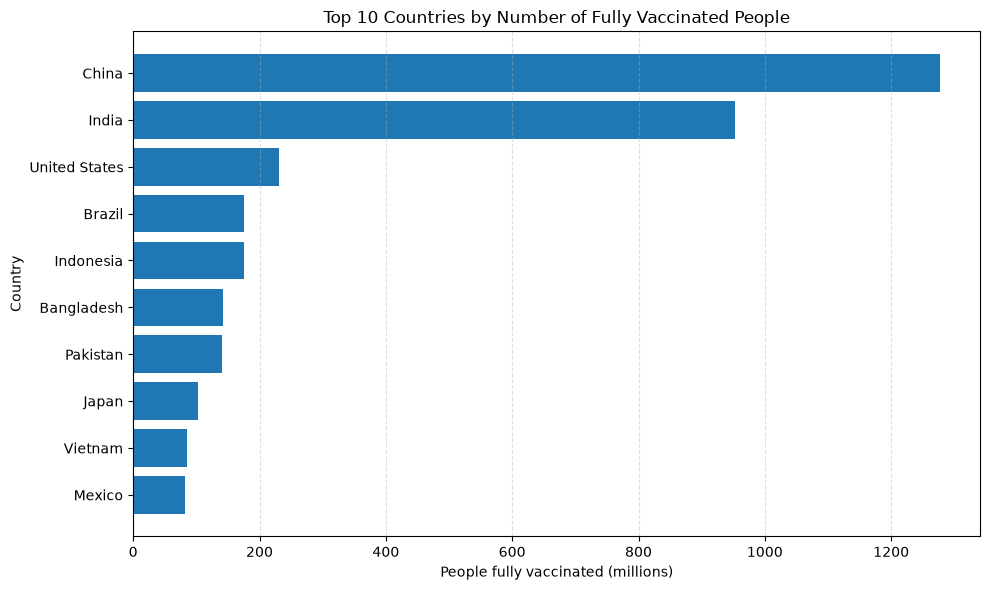

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the COVID-19 dataset
df = pd.read_csv("owid-covid-data.csv")

# Convert date column to datetime
df["date"] = pd.to_datetime(df["date"])

# Exclude aggregate regions and keep rows with vaccination data
countries = df[
    (~df["iso_code"].str.startswith("OWID_", na=False)) &
    (df["people_fully_vaccinated"].notna())
].copy()

# Get the latest available vaccination figure for each country
latest = (
    countries.sort_values("date")
    .groupby("location", as_index=False)
    .tail(1)
)

# Select the 10 countries with the most fully vaccinated people
top10 = latest.nlargest(10, "people_fully_vaccinated")

# Sort for a horizontal bar chart
top10 = top10.sort_values("people_fully_vaccinated")

# Plot the chart
plt.figure(figsize=(10, 6))
plt.barh(
    top10["location"],
    top10["people_fully_vaccinated"] / 1_000_000
)

plt.xlabel("People fully vaccinated (millions)")
plt.ylabel("Country")
plt.title("Top 10 Countries by Number of Fully Vaccinated People")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

**Assessment: Valid – choice stated.** ChatGPT counted people fully vaccinated rather than doses administered (China's dose count, 3.49 billion, exceeds its population), removed the World, continent and income-group rows, and noted that the ranking reflects absolute numbers rather than population share, which is appropriate for a question about the most people vaccinated.

### T13. Compare COVID vaccination rates across European countries.

Hidden choice: which rows count as countries; doses or people.

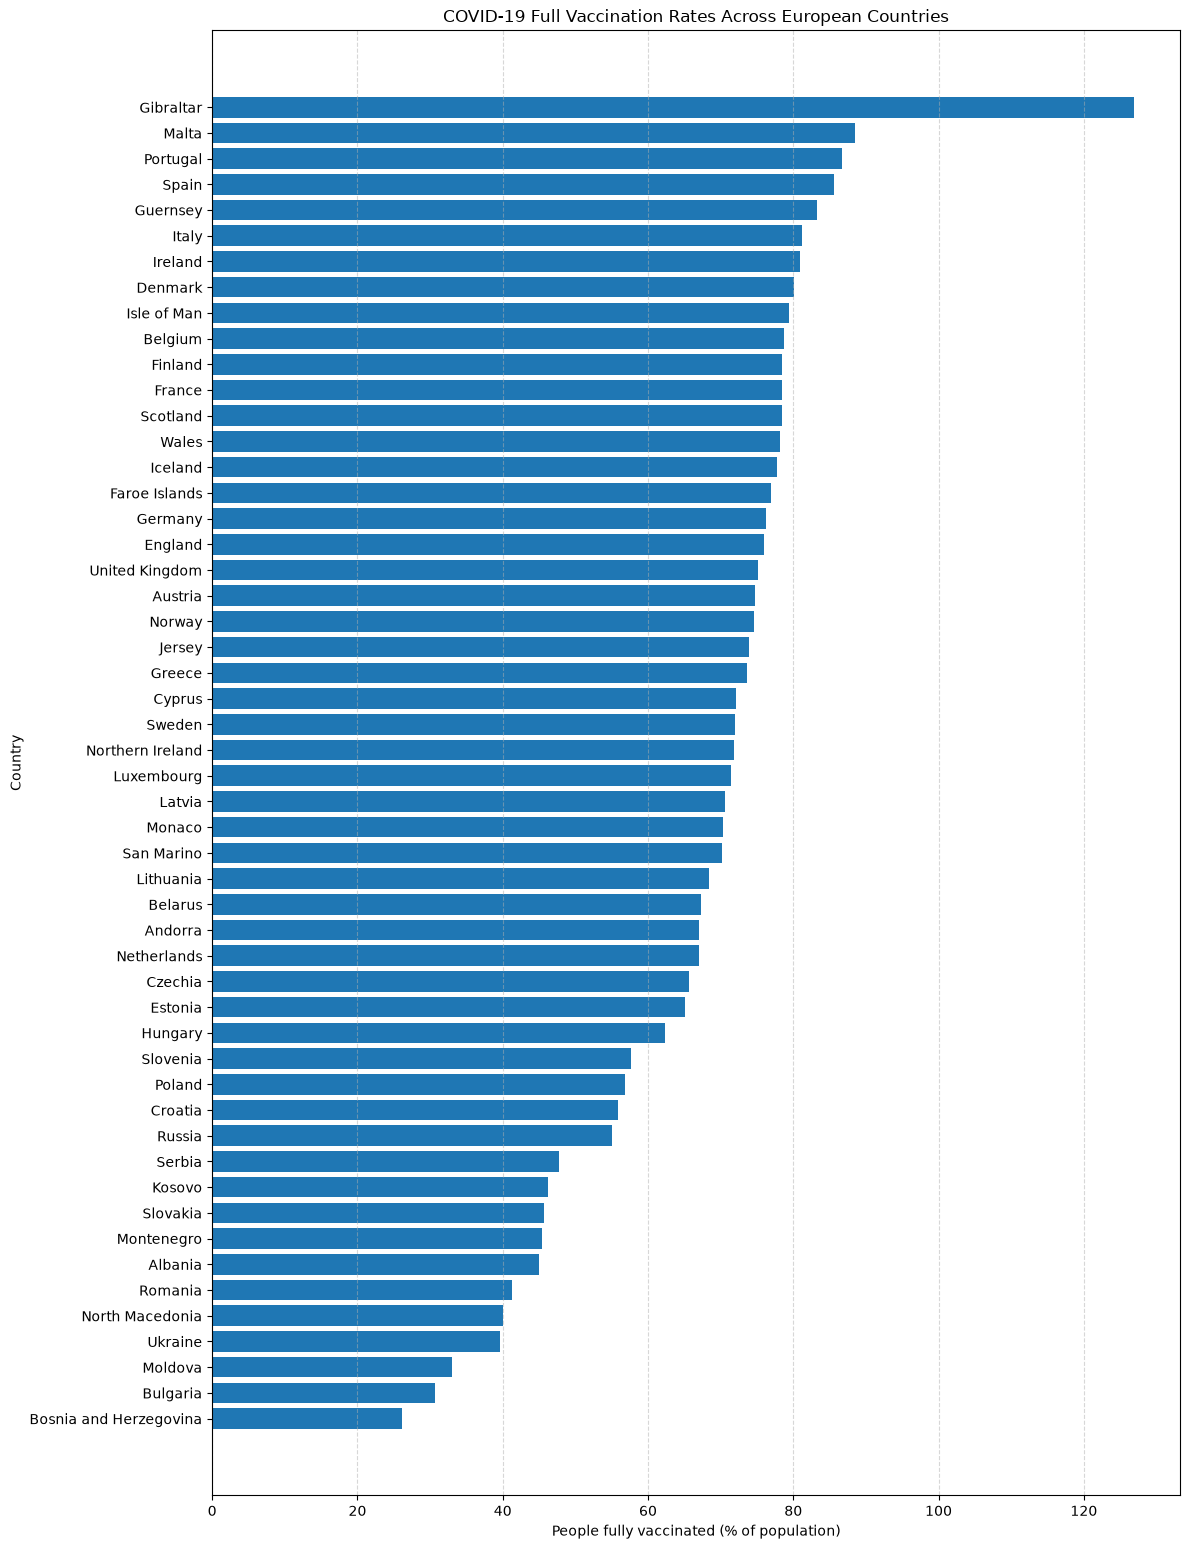

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the COVID-19 dataset
df = pd.read_csv(
    "owid-covid-data.csv",
    parse_dates=["date"]
)

# 2. Filter data to European countries
europe = df[df["continent"] == "Europe"].copy()

# 3. Keep records with reported full vaccination rates
europe = europe.dropna(
    subset=["people_fully_vaccinated_per_hundred"]
)

# 4. Get the latest available vaccination rate for each country
latest = (
    europe.sort_values("date")
    .groupby("location", as_index=False)
    .tail(1)
    .sort_values("people_fully_vaccinated_per_hundred")
)

# 5. Create a horizontal bar chart
plt.figure(figsize=(12, max(8, len(latest) * 0.3)))

plt.barh(
    latest["location"],
    latest["people_fully_vaccinated_per_hundred"]
)

plt.xlabel("People fully vaccinated (% of population)")
plt.ylabel("Country")
plt.title("COVID-19 Full Vaccination Rates Across European Countries")

plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

**Assessment: Silent analytical error.** ChatGPT correctly used the share of people fully vaccinated, but selected every row labelled Europe, so the chart's 52 bars include England, Scotland, Wales and Northern Ireland alongside the United Kingdom (the UK appears five times), as well as territories such as Gibraltar, Guernsey, Jersey, the Isle of Man and the Faroe Islands. The top bar is Gibraltar at 126.9%, an impossible share that most likely reflects vaccinations of people living outside the territory. The answer's caveats covered differing reporting dates only, and the chart is titled as a comparison of countries.

### T14. Show each country's latest COVID death rate per million.

Hidden choice: what "latest" means when the newest date in the file has no death data.

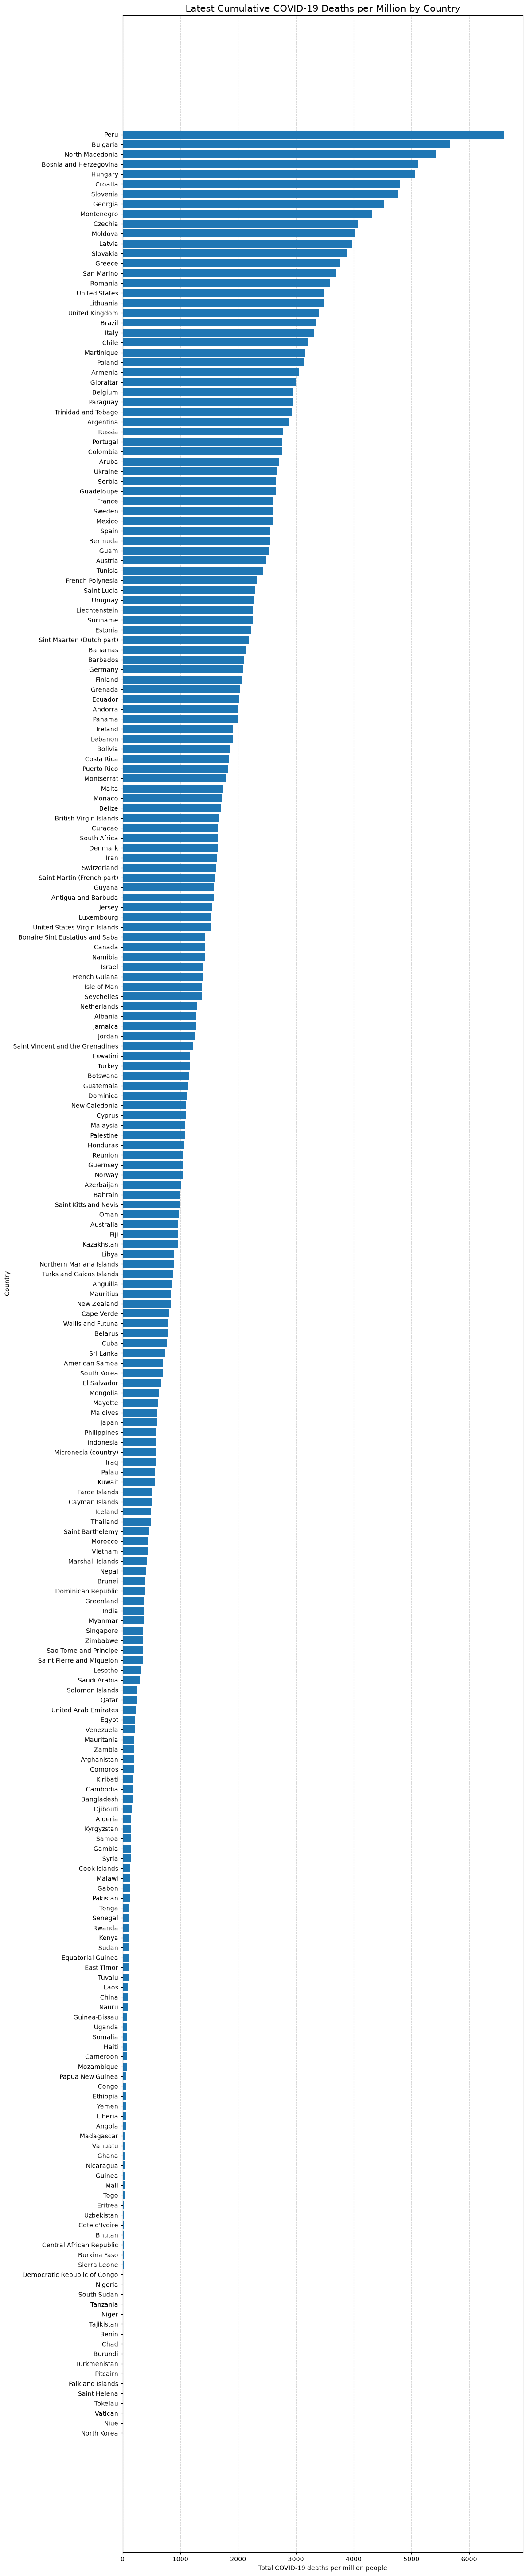

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the dataset
df = pd.read_csv("owid-covid-data.csv", parse_dates=["date"])

# 2. Keep country rows and exclude aggregate locations
countries = df[
    df["continent"].notna()
    & ~df["iso_code"].astype(str).str.startswith("OWID_")
].copy()

# 3. Ensure the death-rate column is numeric
countries["total_deaths_per_million"] = pd.to_numeric(
    countries["total_deaths_per_million"], errors="coerce"
)

# 4. Remove rows where the death-rate value is missing
countries = countries.dropna(subset=["total_deaths_per_million"])

# 5. Get each country's latest available observation
latest = (
    countries.sort_values("date")
    .groupby("location", as_index=False)
    .tail(1)
    .sort_values("total_deaths_per_million")
)

# 6. Create a horizontal bar chart
fig, ax = plt.subplots(
    figsize=(12, max(8, len(latest) * 0.25))
)

ax.barh(
    latest["location"],
    latest["total_deaths_per_million"]
)

ax.set_title(
    "Latest Cumulative COVID-19 Deaths per Million by Country",
    fontsize=15
)
ax.set_xlabel("Total COVID-19 deaths per million people")
ax.set_ylabel("Country")

ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    "latest_covid_death_rate_per_million.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

**Assessment: Valid – choice stated.** ChatGPT used each country's last available deaths-per-million value rather than filtering to the newest date in the file (14 August 2024), which contains no death data and would have produced an empty chart. It excluded the World, continent and income-group rows and noted that reporting dates may differ; in practice all 233 values date from 4 August 2024. The chart reports officially recorded zeros (for example, North Korea and Turkmenistan) without comment.

### T15. Compare how strict COVID restrictions were across countries in 2023.

Hidden choice: whether the dataset covers the period asked about.

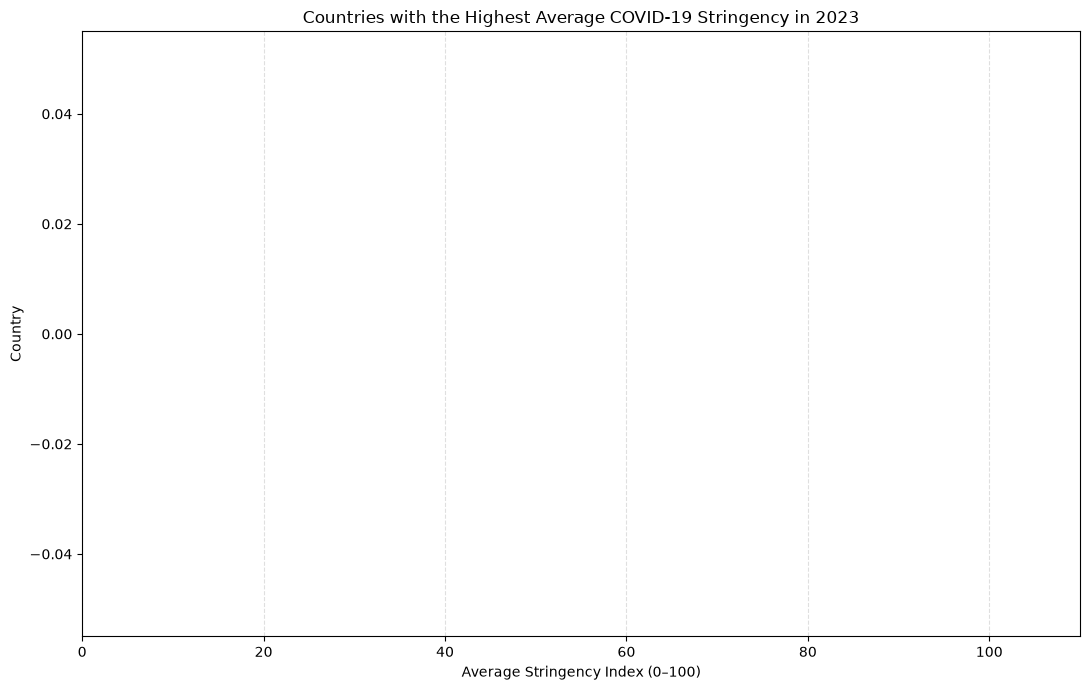

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the dataset and parse dates
df = pd.read_csv("owid-covid-data.csv", parse_dates=["date"])

# 2. Filter data to 2023
df_2023 = df[df["date"].dt.year == 2023].copy()

# 3. Keep countries, excluding regional and global aggregates
df_2023 = df_2023[
    df_2023["continent"].notna()
    & ~df_2023["iso_code"].fillna("").str.startswith("OWID_")
]

# 4. Ensure the stringency index is numeric
df_2023["stringency_index"] = pd.to_numeric(
    df_2023["stringency_index"], errors="coerce"
)

# 5. Calculate average stringency for each country
country_stats = (
    df_2023.dropna(subset=["stringency_index"])
    .groupby("location")
    .agg(
        average_stringency=("stringency_index", "mean"),
        reporting_days=("stringency_index", "count")
    )
)

# Require at least 30 days of reported data
country_stats = country_stats[
    country_stats["reporting_days"] >= 30
]

# Select the 15 countries with the highest average stringency
top_15 = country_stats.nlargest(
    15, "average_stringency"
).sort_values("average_stringency")

# 6. Create the horizontal bar chart
plt.figure(figsize=(11, 7))

bars = plt.barh(
    top_15.index,
    top_15["average_stringency"]
)

# Add average values beside the bars
for bar in bars:
    value = bar.get_width()
    plt.text(
        value + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}",
        va="center",
        fontsize=9
    )

plt.title(
    "Countries with the Highest Average COVID-19 "
    "Stringency in 2023"
)
plt.xlabel("Average Stringency Index (0–100)")
plt.ylabel("Country")
plt.xlim(0, 110)
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()

# 7. Display the chart
plt.show()

**Assessment: Visible error.** The Stringency Index in this dataset ends on 31 December 2022, so no 2023 values exist. ChatGPT's code filtered to 2023, found no data, and produced a titled chart with no bars, without raising an error or a message. Its answer described how to read the bars and did not mention that 2023 data might be missing. Although the empty chart signals a problem, its title invites the misreading that no country had restrictions in 2023.

### T16. Which countries had the highest excess mortality during the pandemic?

Hidden choice: absolute numbers or relative measures; the period covered, which differs by country.

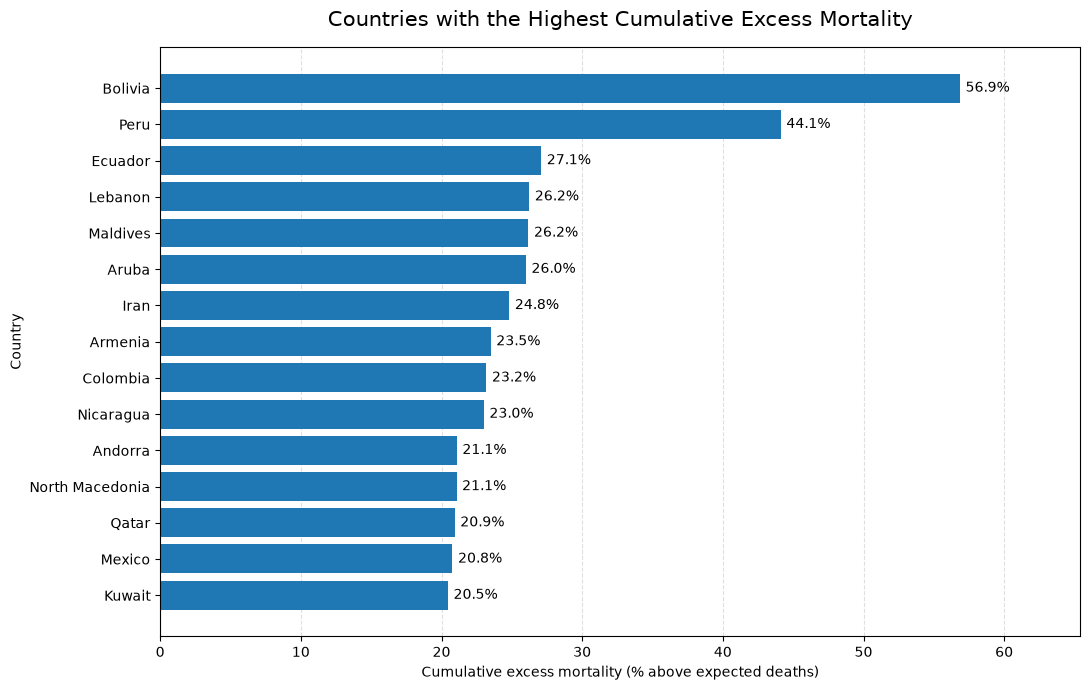

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the COVID-19 dataset
df = pd.read_csv("owid-covid-data.csv", parse_dates=["date"])

# 2. Select the metric for cumulative excess mortality (%)
metric = "excess_mortality_cumulative"

# Keep country-level records, excluding regional and global aggregates
countries = df.loc[
    df["continent"].notna(),
    ["location", "date", metric]
].copy()

# Ensure the mortality values are numeric
countries[metric] = pd.to_numeric(
    countries[metric], errors="coerce"
)

# Remove rows without a valid date or excess mortality value
countries = countries.dropna(subset=["date", metric])

# 3. Get each country's latest available observation
latest = (
    countries
    .sort_values("date")
    .drop_duplicates(subset="location", keep="last")
)

# 4. Select the 15 countries with the highest excess mortality
top_countries = (
    latest.nlargest(15, metric)
    .sort_values(metric, ascending=True)
)

# 5. Create a horizontal bar chart
fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    top_countries["location"],
    top_countries[metric]
)

# Add chart title and axis labels
ax.set_title(
    "Countries with the Highest Cumulative Excess Mortality",
    fontsize=15,
    pad=15
)
ax.set_xlabel("Cumulative excess mortality (% above expected deaths)")
ax.set_ylabel("Country")

# Display the values beside the bars
ax.bar_label(bars, fmt="%.1f%%", padding=4)

# Improve readability
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
ax.set_xlim(right=max(0, top_countries[metric].max()) * 1.15)

plt.tight_layout()
plt.show()

**Assessment: Flagged analytical error.** ChatGPT chose a suitable relative measure (cumulative excess mortality as a percentage above expected deaths) but took each country's latest value, so the bars cover different periods: of the 15 countries shown, four end in 2021, four in 2022 and seven in 2023. Because excess mortality was highest in 2020–2021, longer series are diluted, and the ranking partly reflects when each country stopped reporting. Measured over a common period to the end of 2021, for example, Kuwait's figure rises from 20.5% to 44.1% and Mexico's from 20.8% to 42.2%. The answer warned that observations may come from different points in time but did not show the dates. This is labelled as flagged rather than valid because the dates were not stated, a judgement recorded in the labelling log.

### T17. Which countries were best at testing for COVID?

Hidden choice: total tests or tests relative to population; a snapshot or the whole pandemic; units that differ between countries.

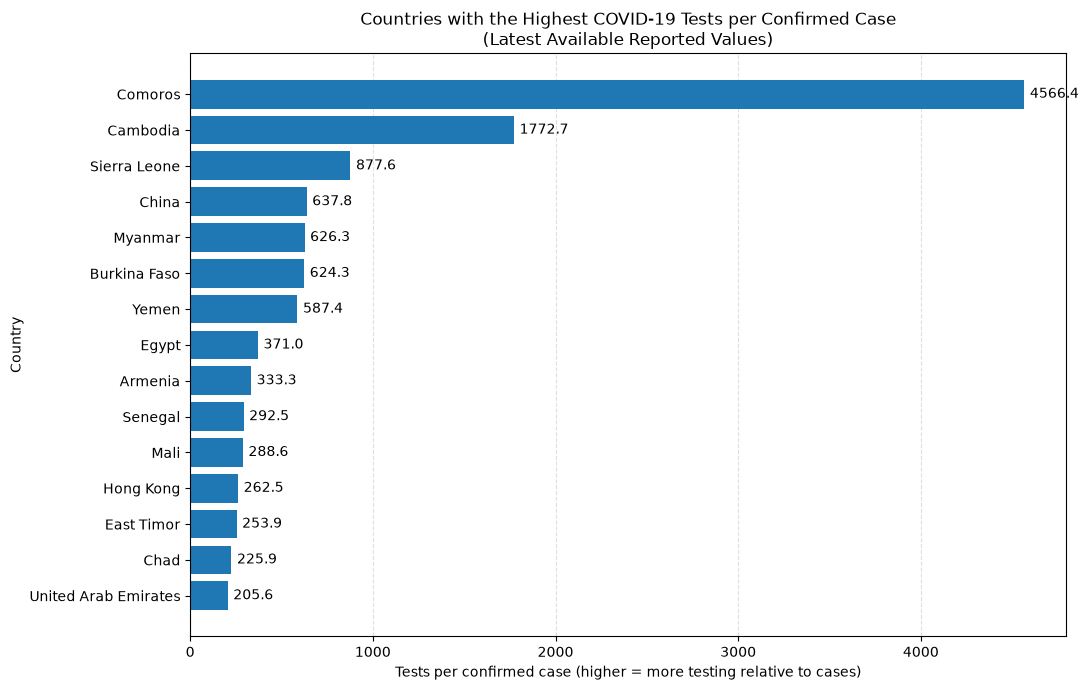

In [18]:

import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the COVID-19 dataset
df = pd.read_csv("owid-covid-data.csv")

# 2. Convert columns to the correct data types
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["tests_per_case"] = pd.to_numeric(
    df["tests_per_case"], errors="coerce"
)

# 3. Keep country-level records and valid testing values
df = df[
    df["continent"].notna()
    & df["tests_per_case"].notna()
    & (df["tests_per_case"] > 0)
].copy()

# Remove infinite values, if any
df = df[
    df["tests_per_case"].apply(lambda x: pd.notna(x) and x != float("inf"))
]

# 4. Find each country's latest available testing value
latest = (
    df.sort_values("date")
      .groupby("location")
      .tail(1)
)

# 5. Select the 15 countries with the highest tests-per-case values
top_countries = (
    latest.nlargest(15, "tests_per_case")
          .sort_values("tests_per_case", ascending=True)
)

# 6. Create the horizontal bar chart
fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    top_countries["location"],
    top_countries["tests_per_case"]
)

# Display the values at the ends of the bars
ax.bar_label(bars, fmt="%.1f", padding=4)

ax.set_title(
    "Countries with the Highest COVID-19 Tests per Confirmed Case\n"
    "(Latest Available Reported Values)"
)
ax.set_xlabel("Tests per confirmed case (higher = more testing relative to cases)")
ax.set_ylabel("Country")
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


**Assessment: Flagged analytical error.** ChatGPT ranked countries by tests per confirmed case at each country's last reported date, mostly mid-2022, when some countries were recording very few cases. Dividing by a near-zero case count produces very large ratios, so the top 15 include countries with some of the lowest testing levels of the pandemic: Chad, for example, ranks 14th with 226 tests per case, despite about 13 tests per 1,000 people in total, compared with more than 11,000 per 1,000 in Denmark. The answer cautioned that the ratio does not necessarily reflect testing quality and is influenced by case detection and reporting dates, and suggested tests per thousand people as an alternative, but it understated how far the ranking is distorted.

### T18. Do countries with higher diabetes rates have more COVID deaths?

Hidden choice: total deaths or deaths per person; whether to account for age.

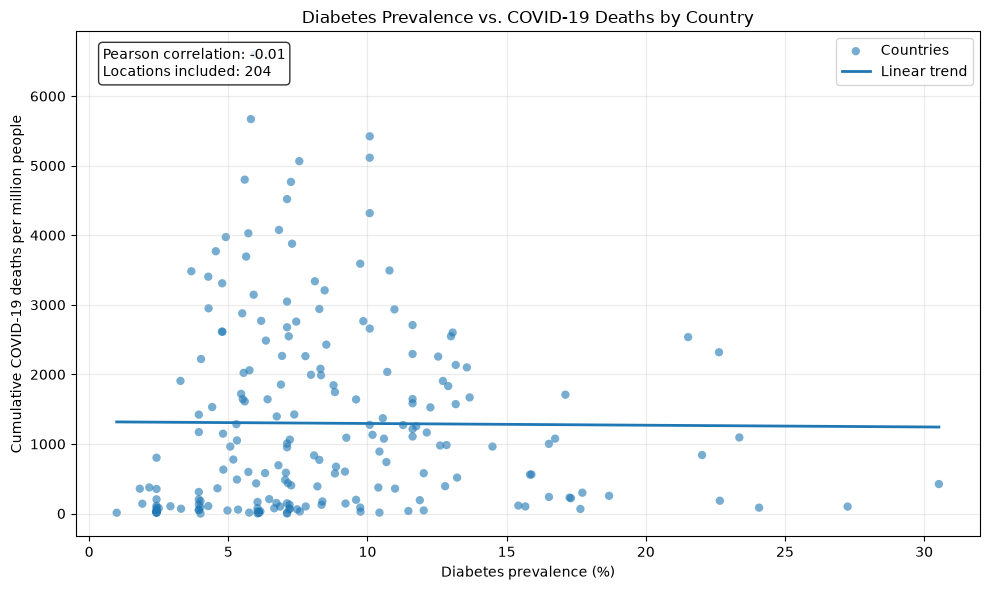

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Load the Our World in Data COVID-19 dataset
df = pd.read_csv("owid-covid-data.csv")

# 2. Convert columns to the appropriate data types
df["date"] = pd.to_datetime(df["date"], errors="coerce")

df["diabetes_prevalence"] = pd.to_numeric(
    df["diabetes_prevalence"], errors="coerce"
)
df["total_deaths_per_million"] = pd.to_numeric(
    df["total_deaths_per_million"], errors="coerce"
)

# 3. Exclude aggregate locations such as the World and continents
df = df[
    df["iso_code"].notna()
    & ~df["iso_code"].astype(str).str.startswith("OWID_")
].dropna(subset=["date"])

# 4. Get the latest available non-missing values for each location
df = df.sort_values("date")

countries = (
    df.groupby(["iso_code", "location"], as_index=False)
    .agg(
        diabetes_prevalence=("diabetes_prevalence", "last"),
        deaths_per_million=("total_deaths_per_million", "last")
    )
    .dropna(subset=["diabetes_prevalence", "deaths_per_million"])
)

# 5. Calculate the correlation between the two variables
x = countries["diabetes_prevalence"]
y = countries["deaths_per_million"]

correlation = x.corr(y)

# 6. Create the scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(
    x,
    y,
    alpha=0.6,
    edgecolors="none",
    label="Countries"
)

# Add a linear trend line
if len(countries) >= 2 and x.nunique() > 1:
    slope, intercept = np.polyfit(x, y, 1)
    x_line = np.linspace(x.min(), x.max(), 100)
    y_line = slope * x_line + intercept

    plt.plot(
        x_line,
        y_line,
        linewidth=2,
        label="Linear trend"
    )

# Add chart labels and title
plt.title("Diabetes Prevalence vs. COVID-19 Deaths by Country")
plt.xlabel("Diabetes prevalence (%)")
plt.ylabel("Cumulative COVID-19 deaths per million people")

plt.annotate(
    f"Pearson correlation: {correlation:.2f}\n"
    f"Locations included: {len(countries)}",
    xy=(0.03, 0.97),
    xycoords="axes fraction",
    va="top",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.8)
)

plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

**Assessment: Valid – choice stated.** ChatGPT compared diabetes prevalence with deaths per million across 204 countries, explaining that a per-person rate makes countries of different sizes comparable, and cautioned that the association is not causal and may reflect age structure, healthcare capacity, vaccination and reporting. The correlation is essentially zero (r = −0.01). The analysis does not adjust for age, which is far more strongly related to COVID death rates (r = 0.68 with the share aged 65 and over), and the answer does not warn that a country-level comparison cannot show whether diabetes raises an individual's risk (the ecological fallacy).

### T19. Did richer countries handle COVID better? Plot GDP per capita against COVID deaths.

Hidden choice: total deaths or deaths per person; whether richer countries are older and record deaths more completely.

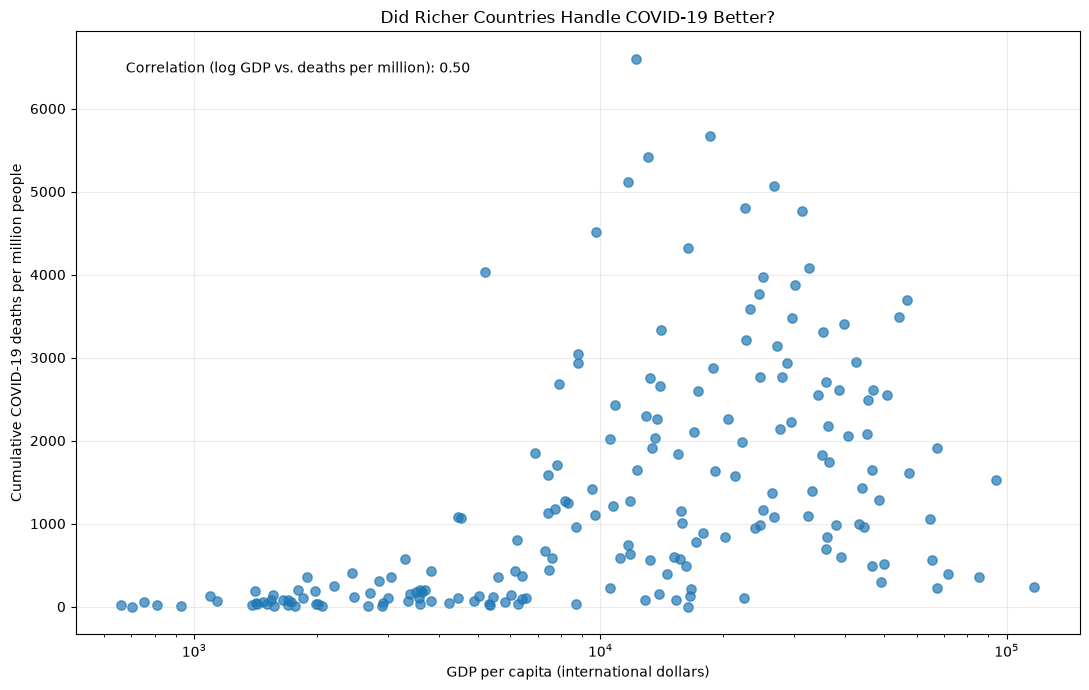

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Load the dataset
df = pd.read_csv("owid-covid-data.csv", parse_dates=["date"])

# 2. Keep individual countries and exclude regional aggregates
countries = df[
    df["continent"].notna()
    & ~df["iso_code"].str.startswith("OWID_", na=False)
].copy()

# 3. Keep rows with both GDP and COVID-19 death data
countries = countries.dropna(
    subset=["gdp_per_capita", "total_deaths_per_million"]
)

# Exclude invalid GDP values
countries = countries[countries["gdp_per_capita"] > 0]

# 4. Select the latest available observation for each country
latest = (
    countries.sort_values("date")
    .groupby(["iso_code", "location"], group_keys=False)
    .tail(1)
    .copy()
)

# 5. Calculate the correlation between log GDP and deaths per million
log_gdp = np.log10(latest["gdp_per_capita"])
correlation = log_gdp.corr(latest["total_deaths_per_million"])

# 6. Create the scatter plot
plt.figure(figsize=(11, 7))

plt.scatter(
    latest["gdp_per_capita"],
    latest["total_deaths_per_million"],
    alpha=0.7,
    s=45
)

# Use a logarithmic x-axis because GDP varies substantially
# between countries
plt.xscale("log")

plt.xlabel("GDP per capita (international dollars)")
plt.ylabel("Cumulative COVID-19 deaths per million people")
plt.title("Did Richer Countries Handle COVID-19 Better?")

plt.text(
    0.05,
    0.95,
    f"Correlation (log GDP vs. deaths per million): {correlation:.2f}",
    transform=plt.gca().transAxes,
    verticalalignment="top"
)

plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

**Assessment: Valid – choice stated.** ChatGPT plotted deaths per million against GDP per capita on a logarithmic scale, explaining that a per-person rate makes countries comparable, and cautioned that age, healthcare capacity and reporting quality also influence recorded deaths. The chart shows a clear positive correlation (r = 0.50 using log GDP, across 192 countries), which taken at face value suggests richer countries fared worse. However, richer countries are older (r = 0.66 between log GDP and the share aged 65 and over), and after adjusting for age the correlation falls to 0.08; poorer countries also recorded a smaller share of their deaths. The caveats name these factors, but the analysis does not adjust for them.

### T20. Did low-income countries have a lower COVID death rate than high-income countries?

Hidden choice: whether recorded deaths are equally complete across income groups.

Median cumulative reported COVID-19 deaths per million:
               median  countries
income_group                    
Low income      54.72         25
High income   1832.17         83


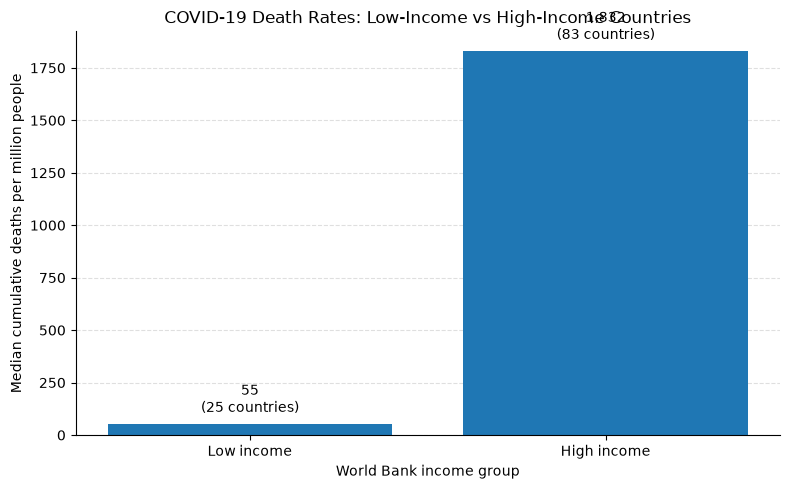


Conclusion: Low-income countries had a lower median reported cumulative COVID-19 death rate.


In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import requests

# 1. Load the Our World in Data COVID-19 dataset
df = pd.read_csv("owid-covid-data.csv", low_memory=False)

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["total_deaths_per_million"] = pd.to_numeric(
    df["total_deaths_per_million"], errors="coerce"
)

# 2. Retrieve World Bank country income classifications
url = "https://api.worldbank.org/v2/country?format=json&per_page=400"

response = requests.get(url, timeout=30)
response.raise_for_status()
payload = response.json()

if len(payload) < 2 or not isinstance(payload[1], list):
    raise ValueError("Could not retrieve World Bank country classifications.")

countries = payload[1]

income_records = []

for country in countries:
    income_code = country.get("incomeLevel", {}).get("id")
    iso_code = country.get("id")

    # Compare only low-income and high-income countries
    if income_code in ["LIC", "HIC"] and iso_code:
        income_records.append({
            "iso_code": iso_code,
            "income_group": {
                "LIC": "Low income",
                "HIC": "High income"
            }[income_code]
        })

income_df = pd.DataFrame(income_records).drop_duplicates(
    subset="iso_code"
)

# 3. Get each country's latest available cumulative death rate
df = df.dropna(subset=["iso_code", "date",
                       "total_deaths_per_million"])

df = df.sort_values("date")

latest = (
    df.groupby("iso_code", group_keys=False)
      .tail(1)
      .copy()
)

# 4. Match countries to their World Bank income groups
comparison = latest.merge(
    income_df,
    on="iso_code",
    how="inner"
)

# Middle-income countries and unmatched locations are excluded.
comparison = comparison[
    comparison["income_group"].isin(["Low income", "High income"])
]

# 5. Calculate the median deaths per million for each group
order = ["Low income", "High income"]

summary = (
    comparison.groupby("income_group")["total_deaths_per_million"]
    .agg(median="median", countries="count")
    .reindex(order)
)

print("Median cumulative reported COVID-19 deaths per million:")
print(summary)

# 6. Plot the results
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    order,
    summary["median"].values
)

ax.set_title(
    "COVID-19 Death Rates: Low-Income vs High-Income Countries"
)
ax.set_ylabel("Median cumulative deaths per million people")
ax.set_xlabel("World Bank income group")

# Display the median and number of countries above each bar
for bar, group in zip(bars, order):
    value = summary.loc[group, "median"]
    count = summary.loc[group, "countries"]

    if pd.notna(value):
        ax.annotate(
            f"{value:,.0f}\n({int(count)} countries)",
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom"
        )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# 7. Print the conclusion based on the chart
low = summary.loc["Low income", "median"]
high = summary.loc["High income", "median"]

if pd.notna(low) and pd.notna(high):
    if low < high:
        print(
            "\nConclusion: Low-income countries had a lower "
            "median reported cumulative COVID-19 death rate."
        )
    elif low > high:
        print(
            "\nConclusion: Low-income countries had a higher "
            "median reported cumulative COVID-19 death rate."
        )
    else:
        print(
            "\nConclusion: Both income groups had the same "
            "median reported cumulative COVID-19 death rate."
        )
else:
    print("\nInsufficient data to compare both income groups.")

**Assessment: Flagged analytical error.** ChatGPT downloaded current World Bank income classifications and compared the median country in each group, finding 54.7 recorded deaths per million in 25 low-income countries and 1,832 in 83 high-income countries, and printed the conclusion that low-income countries had a lower reported death rate. Recorded COVID deaths, however, captured a much smaller share of actual deaths where testing and death registration were weakest: WHO estimated 14.9 million excess deaths worldwide in 2020–2021, about 2.7 times the number reported (Msemburi et al., Nature, 2023). The answer noted that reported deaths are not all actual deaths and that reporting "can affect comparisons", but did not convey that the roughly 33-fold gap cannot be taken at face value. The code also relied on an external download rather than the dataset's own income-group rows, and the value label over the high-income bar overlaps the chart title.

### T21. Which country had the deadliest COVID outbreak?

Hidden choice: total deaths, deaths per person, or deaths per recorded case.

Country with the highest reported COVID-19 deaths:
Country: United States
Total deaths: 1,193,165
Latest data date: 2024-08-04


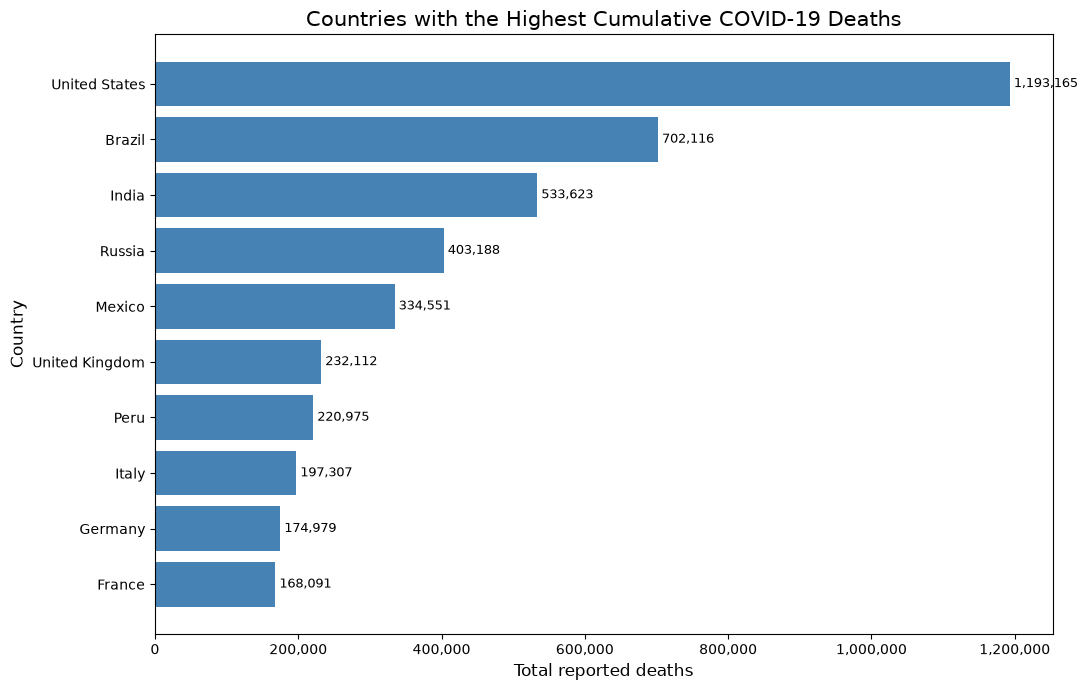

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# 1. Load the COVID-19 dataset
df = pd.read_csv("owid-covid-data.csv")

# 2. Convert dates and death counts to appropriate data types
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["total_deaths"] = pd.to_numeric(df["total_deaths"], errors="coerce")

# 3. Keep country-level records and exclude aggregate regions
#    such as World and continents.
df = df[df["iso_code"].str.fullmatch(r"[A-Z]{3}", na=False)].copy()

# 4. Keep records with known cumulative death counts
df = df.dropna(subset=["date", "total_deaths"])

# 5. Get each country's latest available cumulative death count
latest = (
    df.sort_values("date")
      .groupby("location", as_index=False)
      .tail(1)
      .copy()
)

# 6. Rank countries by total COVID-19 deaths
top10 = latest.nlargest(10, "total_deaths").sort_values(
    "total_deaths", ascending=True
)

# 7. Print the country with the highest total
deadliest = top10.iloc[-1]

print("Country with the highest reported COVID-19 deaths:")
print(f"Country: {deadliest['location']}")
print(f"Total deaths: {deadliest['total_deaths']:,.0f}")
print(f"Latest data date: {deadliest['date'].date()}")

# 8. Create a horizontal bar chart
plt.figure(figsize=(11, 7))

bars = plt.barh(
    top10["location"],
    top10["total_deaths"],
    color="steelblue"
)

plt.title(
    "Countries with the Highest Cumulative COVID-19 Deaths",
    fontsize=15
)
plt.xlabel("Total reported deaths", fontsize=12)
plt.ylabel("Country", fontsize=12)

# Format the x-axis with thousands separators
plt.gca().xaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:,.0f}")
)

# Add death counts beside each bar
for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f" {width:,.0f}",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

**Assessment: Flagged analytical error.** ChatGPT acknowledged that "deadliest" could mean total deaths or deaths per person, but chose total deaths and printed the United States (1,193,165 deaths) as the answer. Relative to population, the deadliest outbreak was Peru's (6,601 deaths per million, against 3,494 in the United States). The answer warned that populous countries may rank higher simply because they have more people and named deaths per million as the alternative.

### T22. Which countries saw COVID cases rise fastest in March 2020?

Hidden choice: absolute increase or relative growth; which countries to include.

Countries with the fastest relative case growth in March 2020:
    country  start_cases  end_cases daily_growth_pct
      Spain        148.0   108864.0           24.61%
    Germany        170.0    63904.0           21.85%
      Italy       1128.0    92472.0           15.82%
       Iran        593.0    35408.0           14.60%
  Singapore        102.0      802.0            7.12%
      Japan        239.0     1693.0            6.74%
South Korea       3526.0     9583.0            3.39%
      China      79968.0    82341.0            0.10%


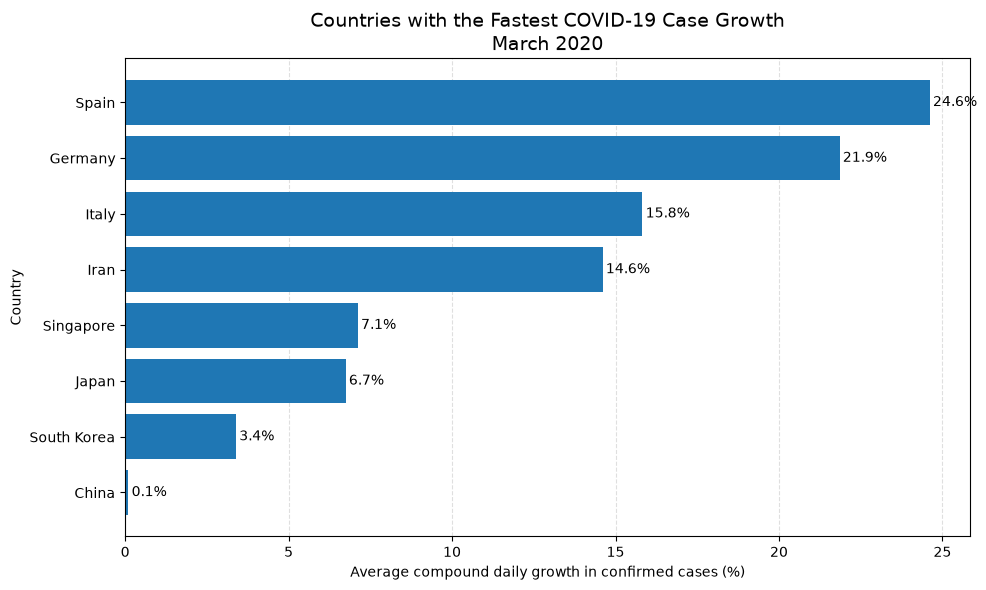

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the dataset
df = pd.read_csv("owid-covid-data.csv", parse_dates=["date"])

# 2. Select country-level data for March 2020
march = df.loc[
    df["date"].between("2020-03-01", "2020-03-31")
    & df["continent"].notna()
    & ~df["iso_code"].fillna("").str.startswith("OWID_"),
    ["iso_code", "location", "date", "total_cases"]
].copy()

march["total_cases"] = pd.to_numeric(
    march["total_cases"], errors="coerce"
)

march = march.dropna(
    subset=["iso_code", "total_cases"]
).sort_values("date")

# 3. Get the first and last available case counts for each country
stats = (
    march.groupby("iso_code")
    .agg(
        country=("location", "last"),
        start_date=("date", "first"),
        start_cases=("total_cases", "first"),
        end_date=("date", "last"),
        end_cases=("total_cases", "last")
    )
    .reset_index()
)

# Calculate the number of days covered
stats["days"] = (
    stats["end_date"] - stats["start_date"]
).dt.days

# Retain countries with a meaningful starting count and
# observations spanning at least 25 days
stats = stats[
    (stats["start_cases"] >= 100)
    & (stats["days"] >= 25)
    & (stats["end_cases"] > stats["start_cases"])
].copy()

# 4. Calculate compound average daily growth rate (%)
stats["daily_growth_pct"] = (
    (stats["end_cases"] / stats["start_cases"])
    ** (1 / stats["days"]) - 1
) * 100

# Select the 10 countries with the fastest growth
top10 = stats.nlargest(10, "daily_growth_pct")
top10 = top10.sort_values("daily_growth_pct")

# 5. Print the ranking
print("Countries with the fastest relative case growth in March 2020:")
print(
    top10.sort_values("daily_growth_pct", ascending=False)[
        ["country", "start_cases", "end_cases", "daily_growth_pct"]
    ].to_string(
        index=False,
        formatters={"daily_growth_pct": "{:.2f}%".format}
    )
)

# 6. Create a horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    top10["country"],
    top10["daily_growth_pct"]
)

ax.set_title(
    "Countries with the Fastest COVID-19 Case Growth\n"
    "March 2020",
    fontsize=14
)
ax.set_xlabel("Average compound daily growth in confirmed cases (%)")
ax.set_ylabel("Country")
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

# Display growth rates at the ends of the bars
for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 0.1,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f}%",
        va="center"
    )

plt.tight_layout()
plt.show()

**Assessment: Flagged analytical error.** ChatGPT chose a suitable measure, the average compound daily growth in confirmed cases, and explained why relative growth suits the question. However, it kept only countries with at least 100 cases on their first March observation, which leaves just 8 of 233 locations: the chart titled as a top 10 shows 8 bars, excludes countries whose outbreaks grew fastest during March, such as the United States, the United Kingdom and France, and includes China at 0.1% per day. The answer noted that some countries may be excluded by the threshold but understated how many.

### T23. Compare hospital bed capacity with COVID deaths across European countries.

Hidden choice: total deaths or deaths per person.

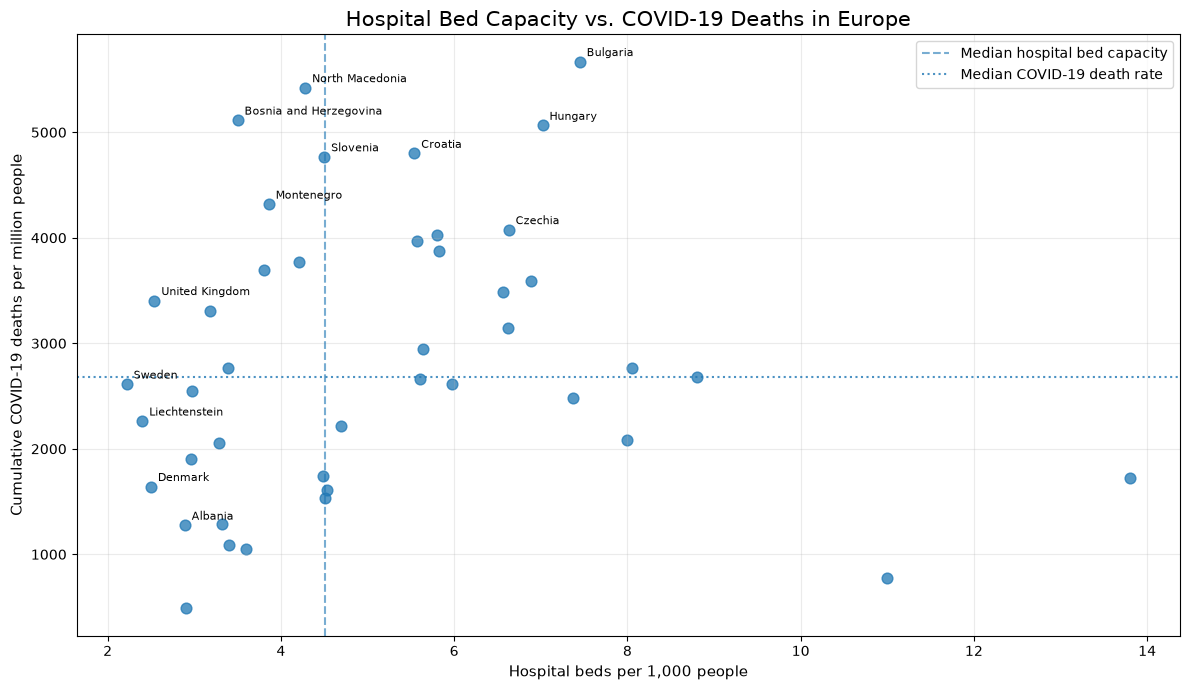

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the COVID-19 dataset
df = pd.read_csv("owid-covid-data.csv")

# Convert date to datetime format
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# 2. Keep European countries only.
# The 3-letter ISO code filter excludes regional and global aggregates.
europe = df[
    (df["continent"] == "Europe")
    & (df["iso_code"].str.fullmatch(r"[A-Z]{3}", na=False))
].copy()

# 3. Sort by date so we can select the latest non-missing values
europe = europe.sort_values("date")

# Get the latest available COVID death rate and hospital bed capacity
country_data = (
    europe.groupby(["iso_code", "location"], as_index=False)
    .agg(
        deaths_per_million=("total_deaths_per_million", "last"),
        beds_per_1000=("hospital_beds_per_thousand", "last")
    )
)

# Remove countries missing either measurement
plot_df = country_data.dropna(
    subset=["deaths_per_million", "beds_per_1000"]
).copy()

# 4. Create the scatter plot
fig, ax = plt.subplots(figsize=(12, 7))

ax.scatter(
    plot_df["beds_per_1000"],
    plot_df["deaths_per_million"],
    alpha=0.75,
    s=60
)

# Add median reference lines
ax.axvline(
    plot_df["beds_per_1000"].median(),
    linestyle="--",
    alpha=0.6,
    label="Median hospital bed capacity"
)

ax.axhline(
    plot_df["deaths_per_million"].median(),
    linestyle=":",
    alpha=0.8,
    label="Median COVID-19 death rate"
)

# 5. Label countries with the highest death rates
# and the lowest hospital bed capacity
labels = pd.concat([
    plot_df.nlargest(8, "deaths_per_million"),
    plot_df.nsmallest(5, "beds_per_1000")
]).drop_duplicates(subset=["iso_code"])

for _, row in labels.iterrows():
    ax.annotate(
        row["location"],
        xy=(row["beds_per_1000"], row["deaths_per_million"]),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8
    )

# 6. Add titles, labels, and formatting
ax.set_title(
    "Hospital Bed Capacity vs. COVID-19 Deaths in Europe",
    fontsize=15
)
ax.set_xlabel("Hospital beds per 1,000 people", fontsize=11)
ax.set_ylabel("Cumulative COVID-19 deaths per million people", fontsize=11)

ax.grid(True, alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

**Assessment: Valid – choice stated.** ChatGPT plotted hospital beds per 1,000 people against deaths per million for 43 European countries, explaining that rates make countries of different sizes comparable, and cautioned that the chart shows an association only and that age, policy, vaccination and reporting also matter. The relationship is essentially flat (r = 0.06). Two limitations were not mentioned: the bed figures are single pre-pandemic values rather than capacity during the pandemic, and some recorded death rates (for example, Belarus's) are widely considered undercounts.

### T24. Show how the number of new COVID cases changed in the United States during 2023.

Hidden choice: how to show the period after reporting stopped; whether the "daily" figures are really daily.

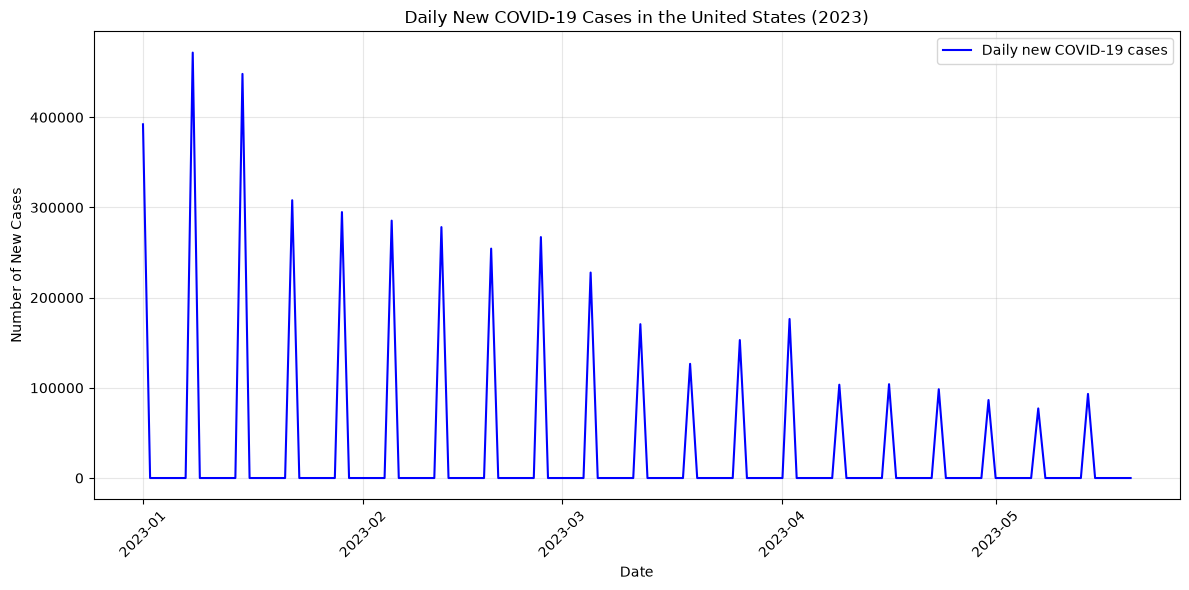

In [25]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the COVID-19 dataset
df = pd.read_csv("owid-covid-data.csv")

# Convert the date column to datetime format
df["date"] = pd.to_datetime(df["date"])

# Filter data for the United States during 2023
us_2023 = df[
    (df["location"] == "United States") &
    (df["date"].dt.year == 2023)
].copy()

# Sort the data by date
us_2023 = us_2023.sort_values("date")

# Create the chart
plt.figure(figsize=(12, 6))
plt.plot(
    us_2023["date"],
    us_2023["new_cases"],
    label="Daily new COVID-19 cases",
    color="blue"
)

# Add chart labels and title
plt.title("Daily New COVID-19 Cases in the United States (2023)")
plt.xlabel("Date")
plt.ylabel("Number of New Cases")
plt.grid(True, alpha=0.3)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

# Display the chart
plt.show()

**Assessment: Silent analytical error.** ChatGPT did not fill the missing months with zeros, but US case reporting in this dataset stops on 20 May 2023, and the chart's time axis ends there too, so a chart titled "2023" covers only January to May with nothing to show that the rest of the year is missing. It also plots new_cases as "Daily new COVID-19 cases", although US cases are recorded weekly on Sundays with zeros on other days, so each spike (up to 471,714 on 8 January) is a weekly total, roughly seven times the daily figure. The answer's note mentioned "missing values or reporting fluctuations" and suggested the smoothed column for a smoother view, but did not identify either problem.

### T25. Is there a link between the share of older people and COVID death rates?

Hidden choice: total deaths or deaths per person (the question largely specifies a rate).

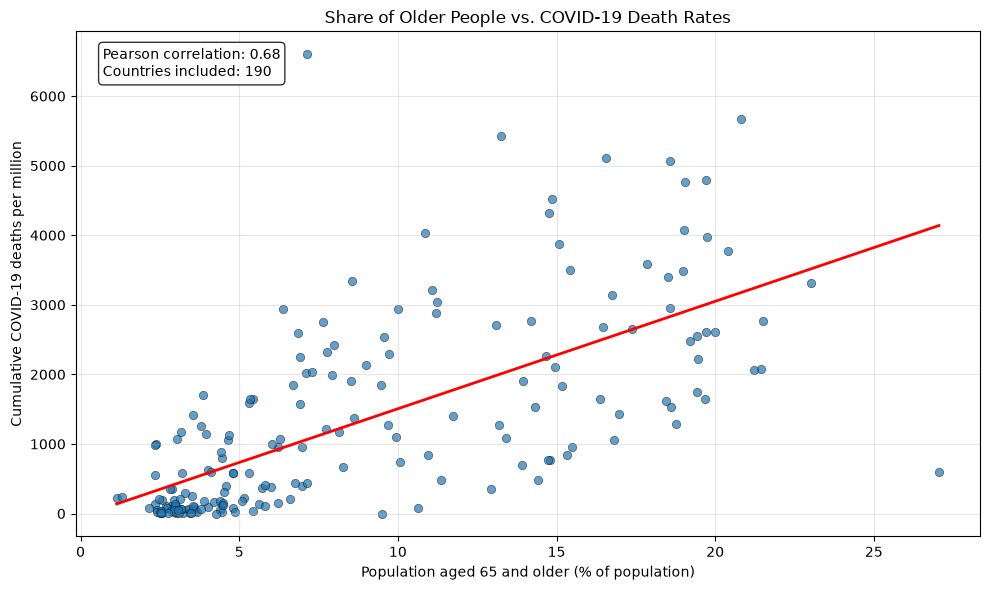

Correlation coefficient: 0.675
Number of countries analyzed: 190


In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Load the dataset
df = pd.read_csv("owid-covid-data.csv", parse_dates=["date"])

# Ensure the analysis columns are numeric
columns = ["aged_65_older", "total_deaths_per_million"]
for col in columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 2. Exclude OWID aggregate rows, such as World and continents
countries = df[
    ~df["iso_code"].fillna("").str.startswith("OWID_")
].copy()

# Keep rows with both variables available
countries = countries.dropna(
    subset=["iso_code", "aged_65_older", "total_deaths_per_million"]
)

# 3. Select the latest available record for each country
latest = (
    countries.sort_values("date")
    .groupby("iso_code")
    .tail(1)
    .copy()
)

# Extract variables for the chart
x = latest["aged_65_older"]
y = latest["total_deaths_per_million"]

# 4. Calculate the correlation coefficient
correlation = x.corr(y)

# Calculate a linear trendline
slope, intercept = np.polyfit(x, y, 1)
x_line = np.linspace(x.min(), x.max(), 100)
y_line = slope * x_line + intercept

# 5. Create the scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(x, y, alpha=0.7, edgecolor="black", linewidth=0.4)
plt.plot(x_line, y_line, linewidth=2, color="red")

plt.xlabel("Population aged 65 and older (% of population)")
plt.ylabel("Cumulative COVID-19 deaths per million")
plt.title("Share of Older People vs. COVID-19 Death Rates")

plt.annotate(
    f"Pearson correlation: {correlation:.2f}\n"
    f"Countries included: {len(latest)}",
    xy=(0.03, 0.97),
    xycoords="axes fraction",
    va="top",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.8)
)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Correlation coefficient: {correlation:.3f}")
print(f"Number of countries analyzed: {len(latest)}")

**Assessment: Valid – choice stated.** ChatGPT plotted the share of the population aged 65 and over against deaths per million for 190 countries and found a strong positive correlation (r = 0.68), jointly the strongest relationship in this pilot (with median age, C03). It cautioned that the chart shows an association only and that healthcare, vaccination, reporting practices, testing and timing also affect results. Part of the association may reflect more complete death recording in older, wealthier countries.

### C01. Plot the 7-day average of new COVID cases in Germany during 2021, using the new_cases_smoothed column.

Control question: fully specified, no hidden choice.

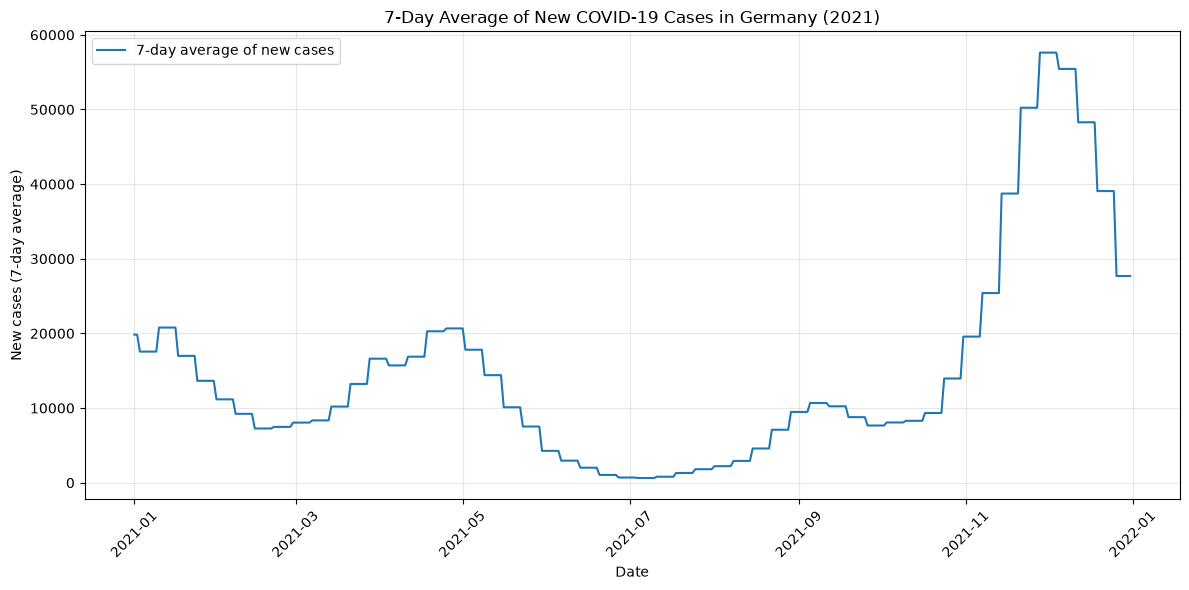

In [27]:

import pandas as pd
import matplotlib.pyplot as plt

# Load the COVID-19 dataset
df = pd.read_csv("owid-covid-data.csv")

# Convert the date column to datetime
df["date"] = pd.to_datetime(df["date"])

# Filter for Germany during 2021
germany_2021 = df[
    (df["location"] == "Germany") &
    (df["date"] >= "2021-01-01") &
    (df["date"] < "2022-01-01")
].copy()

# Sort data by date
germany_2021 = germany_2021.sort_values("date")

# Plot the 7-day average of new cases
plt.figure(figsize=(12, 6))
plt.plot(
    germany_2021["date"],
    germany_2021["new_cases_smoothed"],
    label="7-day average of new cases"
)

# Add chart labels and formatting
plt.title("7-Day Average of New COVID-19 Cases in Germany (2021)")
plt.xlabel("Date")
plt.ylabel("New cases (7-day average)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

# Display the chart
plt.show()


**Assessment: Valid.** ChatGPT plotted the requested column for the requested country and period, and correctly noted that new_cases_smoothed is already a 7-day average. The chart shows a spring wave, a summer low and the year's peak of about 57,600 cases per day on 28 November 2021.

### C02. Plot total COVID deaths per million over time for France, Germany, Italy and Spain.

Control question: fully specified, no hidden choice.

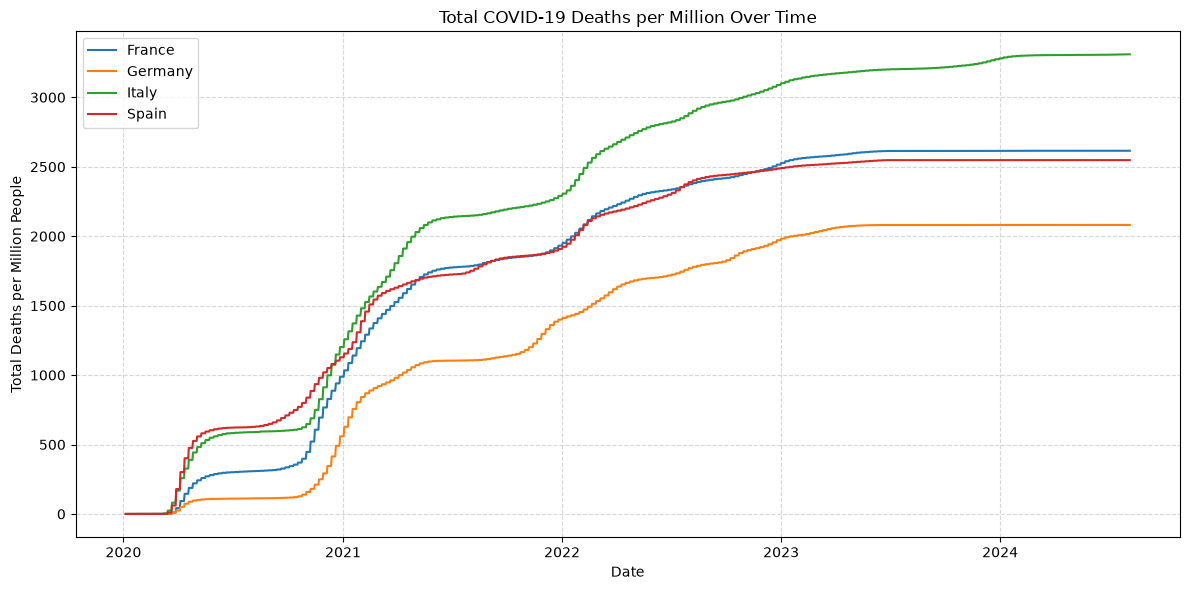

In [28]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the COVID-19 dataset
df = pd.read_csv("owid-covid-data.csv")

# Convert date column to datetime
df["date"] = pd.to_datetime(df["date"])

# Select the four countries
countries = ["France", "Germany", "Italy", "Spain"]
df = df[df["location"].isin(countries)]

# Plot total COVID-19 deaths per million over time
plt.figure(figsize=(12, 6))

for country in countries:
    country_data = df[df["location"] == country].sort_values("date")
    plt.plot(
        country_data["date"],
        country_data["total_deaths_per_million"],
        label=country
    )

# Add chart labels and formatting
plt.title("Total COVID-19 Deaths per Million Over Time")
plt.xlabel("Date")
plt.ylabel("Total Deaths per Million People")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

# Display the chart
plt.show()

**Assessment: Valid.** ChatGPT plotted the requested measure for the four requested countries. By the end of the series, Italy has the highest cumulative death rate (3,309 per million), followed by France (2,615), Spain (2,548) and Germany (2,081).

### C03. Make a scatter plot of median age against total COVID deaths per million, one point per country, excluding the regional and income-group rows.

Control question: fully specified, no hidden choice.

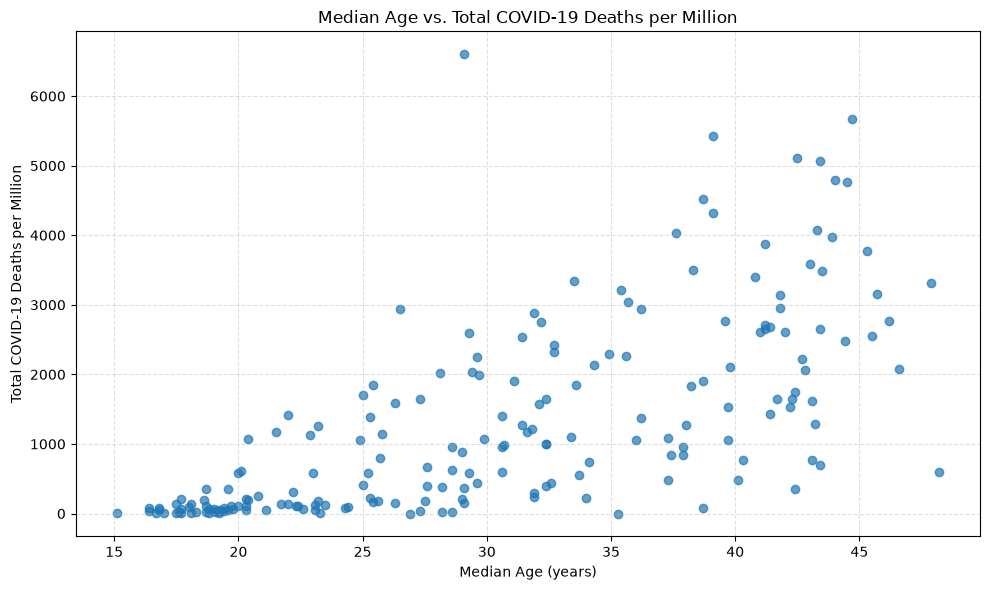

In [29]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("owid-covid-data.csv")

# Keep country rows only, excluding regional and income-group aggregates.
# OWID aggregate rows generally have ISO codes beginning with OWID_.
countries = df[~df["iso_code"].str.startswith("OWID_", na=False)].copy()

# Select the latest available record for each country
countries["date"] = pd.to_datetime(countries["date"])
latest = (
    countries.sort_values("date")
    .groupby("location", as_index=False)
    .last()
)

# Keep rows with valid values for both variables
plot_data = latest.dropna(subset=["median_age", "total_deaths_per_million"])

# Create the scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(
    plot_data["median_age"],
    plot_data["total_deaths_per_million"],
    alpha=0.7
)

plt.title("Median Age vs. Total COVID-19 Deaths per Million")
plt.xlabel("Median Age (years)")
plt.ylabel("Total COVID-19 Deaths per Million")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

**Assessment: Valid.** ChatGPT plotted median age against deaths per million for each country and excluded the regional and income-group rows as instructed. The 196 countries show a strong positive association (r = 0.68, calculated separately), consistent with T25.

## 3. Results with the "state choices" prompt

The same questions, asked with an added instruction: before writing code, list the analytical choices the question leaves open, say which option will be chosen and why, and point out anything in the dataset that could make the chart misleading.

### T01 (state choices). Which countries were hit hardest by COVID-19 deaths? Show me the top 10.

Top 10 locations by cumulative reported COVID-19 deaths
      location       date total_deaths
 United States 2024-08-04    1,193,165
        Brazil 2024-08-04      702,116
         India 2024-08-04      533,623
        Russia 2024-08-04      403,188
        Mexico 2024-08-04      334,551
United Kingdom 2024-08-04      232,112
          Peru 2024-08-04      220,975
         Italy 2024-08-04      197,307
       Germany 2024-08-04      174,979
        France 2024-08-04      168,091


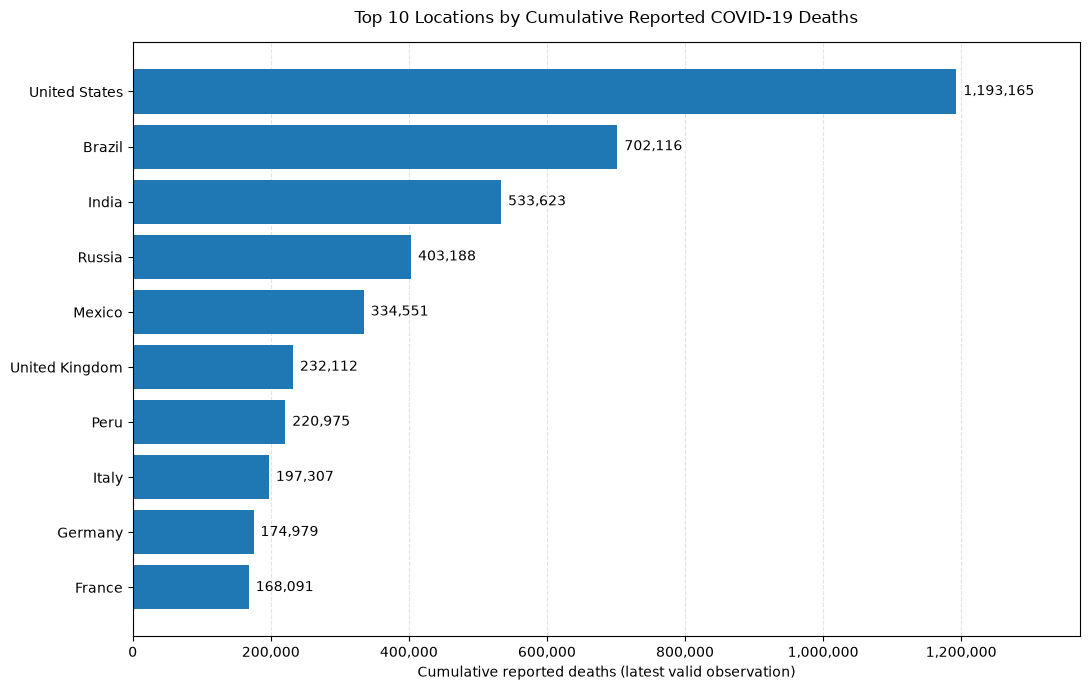

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# 1. Load the dataset
df = pd.read_csv("owid-covid-data.csv")

# Parse dates and ensure death totals are numeric.
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["total_deaths"] = pd.to_numeric(
    df["total_deaths"], errors="coerce"
)

# 2. Keep country-level locations, excluding most regional/global aggregates.
# A nonmissing continent is used as the country-level filter.
# This can still include territories and special locations.
country_rows = df.loc[
    df["continent"].notna()
    & df["iso_code"].notna()
    & df["location"].notna()
    & df["date"].notna()
    & df["total_deaths"].notna()
    & (df["total_deaths"] >= 0)
].copy()

# 3. Handle duplicate location-date records.
# After invalid death totals have been removed, keep the last valid
# record for each location and date.
country_rows = country_rows.sort_values(
    ["location", "date"]
)
country_rows = country_rows.drop_duplicates(
    subset=["location", "date"],
    keep="last"
)

# 4. Get each location's latest valid cumulative death total.
# Do not add cumulative totals across dates.
latest = country_rows.loc[
    country_rows.groupby("location")["date"].idxmax()
].copy()

# 5. Rank locations and select the top 10.
top10 = (
    latest.sort_values("total_deaths", ascending=False)
    .head(10)
    .copy()
)

# Print values and dates to make differences in reporting periods visible.
print("Top 10 locations by cumulative reported COVID-19 deaths")
print(
    top10[["location", "date", "total_deaths"]].to_string(
        index=False,
        formatters={
            "date": lambda d: d.strftime("%Y-%m-%d"),
            "total_deaths": lambda n: f"{n:,.0f}"
        }
    )
)

# Stop if the dataset contains no eligible observations.
if top10.empty:
    raise ValueError(
        "No valid country-level death observations were found."
    )

# 6. Prepare data for a horizontal bar chart.
# Ascending order puts the largest death toll at the top.
plot_data = top10.sort_values(
    "total_deaths", ascending=True
)

fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    plot_data["location"],
    plot_data["total_deaths"]
)

# Format the x-axis and add labels.
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, position: f"{x:,.0f}")
)

ax.set_title(
    "Top 10 Locations by Cumulative Reported COVID-19 Deaths",
    pad=14
)
ax.set_xlabel(
    "Cumulative reported deaths (latest valid observation)"
)
ax.set_ylabel("")

# Show exact death totals at the end of each bar.
for bar, value in zip(bars, plot_data["total_deaths"]):
    ax.annotate(
        f"{value:,.0f}",
        xy=(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(5, 0),
        textcoords="offset points",
        va="center"
    )

ax.grid(axis="x", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)
ax.margins(x=0.15)

fig.tight_layout()
plt.show()

**Assessment: Flagged analytical error (unchanged from baseline).** Asked to state its choices first, ChatGPT listed "absolute totals or population-adjusted rates" as an explicit decision and chose absolute totals, reasoning that they show which countries had the most deaths overall, a different question from which were hit hardest. The chart is the same as the baseline (United States first, Peru seventh). The stated warnings were considerably fuller, covering population size, under-reporting, reporting dates and territories, and the answer recommended deaths per million for a "more balanced assessment". The plan described filtering on three-letter country codes, but the code filters on the continent field instead.

### T02 (state choices). Make a chart comparing how badly COVID affected the countries of South America.

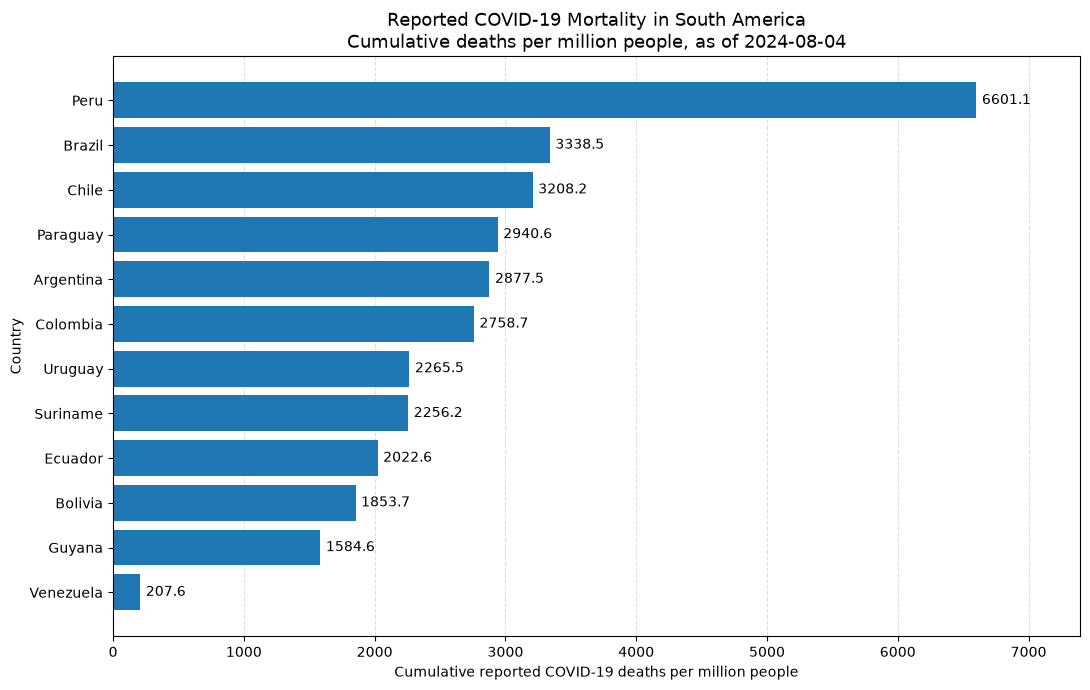

In [31]:
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Load the dataset
# --------------------------------------------------

file_path = "owid-covid-data.csv"

df = pd.read_csv(file_path, parse_dates=["date"])

# Ensure the death-rate column contains numeric values
metric = "total_deaths_per_million"
df[metric] = pd.to_numeric(df[metric], errors="coerce")


# --------------------------------------------------
# 2. Select the 12 sovereign countries of South America
# --------------------------------------------------

south_america_countries = [
    "Argentina",
    "Bolivia",
    "Brazil",
    "Chile",
    "Colombia",
    "Ecuador",
    "Guyana",
    "Paraguay",
    "Peru",
    "Suriname",
    "Uruguay",
    "Venezuela",
]

# Use the explicit country list to exclude aggregate rows
# such as "World" or regional summaries.
sa = df.loc[
    df["location"].isin(south_america_countries),
    ["location", "date", metric]
].copy()

if sa.empty:
    raise ValueError(
        "No matching South American country rows were found. "
        "Check the file path and the country names in the dataset."
    )

# Keep rows with both a valid date and a usable death-rate value.
valid = sa.dropna(subset=["date", metric]).copy()

countries_with_data = [
    country
    for country in south_america_countries
    if country in valid["location"].unique()
]

countries_without_data = sorted(
    set(south_america_countries) - set(countries_with_data)
)

if countries_without_data:
    print(
        "Countries with no usable death-rate observations:",
        ", ".join(countries_without_data)
    )

if not countries_with_data:
    raise ValueError(
        "No usable total_deaths_per_million values were found."
    )


# --------------------------------------------------
# 3. Find a common comparison date
# --------------------------------------------------

# Rows are dates; columns are countries.
# The value in each cell is the cumulative death rate
# for that country on that date.
wide = valid.pivot_table(
    index="date",
    columns="location",
    values=metric,
    aggfunc="last"
).reindex(columns=countries_with_data)

# Keep dates for which every included country has a value.
complete_dates = wide.dropna(subset=countries_with_data)

if not complete_dates.empty:
    # Latest date with an observation for every included country
    comparison_date = complete_dates.index.max()

    values = wide.loc[comparison_date, countries_with_data]

    latest = (
        values.rename(metric)
        .rename_axis("location")
        .reset_index()
    )

    latest["data_date"] = comparison_date
    latest["label"] = latest["location"]

    chart_title = (
        "Reported COVID-19 Mortality in South America\n"
        f"Cumulative deaths per million people, as of "
        f"{comparison_date:%Y-%m-%d}"
    )

else:
    # Fallback: use the latest valid observation for each country.
    # Dates are displayed in the country labels because they
    # may differ between countries.
    latest = (
        valid.sort_values("date")
        .groupby("location", as_index=False)
        .tail(1)
        [["location", "date", metric]]
        .copy()
    )

    latest["data_date"] = latest["date"]

    latest["label"] = latest.apply(
        lambda row: (
            f"{row['location']} "
            f"({row['data_date']:%Y-%m-%d})"
        ),
        axis=1
    )

    chart_title = (
        "Reported COVID-19 Mortality in South America\n"
        "Cumulative deaths per million people, "
        "latest available observation per country"
    )


# --------------------------------------------------
# 4. Sort countries by deaths per million
# --------------------------------------------------

latest = latest.sort_values(
    metric,
    ascending=True
)


# --------------------------------------------------
# 5. Create the horizontal bar chart
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    latest["label"],
    latest[metric]
)

# Add the value to the end of each bar.
ax.bar_label(
    bars,
    fmt="%.1f",
    padding=4
)

ax.set_title(chart_title, fontsize=13)
ax.set_xlabel("Cumulative reported COVID-19 deaths per million people")
ax.set_ylabel("Country")

# Light gridlines make comparisons easier.
ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.4
)
ax.set_axisbelow(True)

# Leave room for the numeric labels at the end of the bars.
ax.margins(x=0.12)

fig.tight_layout()
plt.show()

**Assessment: Valid – choice stated (improved on baseline).** ChatGPT set out its choices before coding: deaths per million, because totals would rank populous countries such as Brazil highest; the 12 sovereign countries of South America listed explicitly, which excludes the territories the baseline chart had included; and the latest date on which all twelve had data (4 August 2024), shown in the title. It treated missing values as unavailable rather than zero and noted that reported deaths depend on testing and certification and that the rate does not account for age structure.

### T03 (state choices). Which African countries were most affected by COVID?

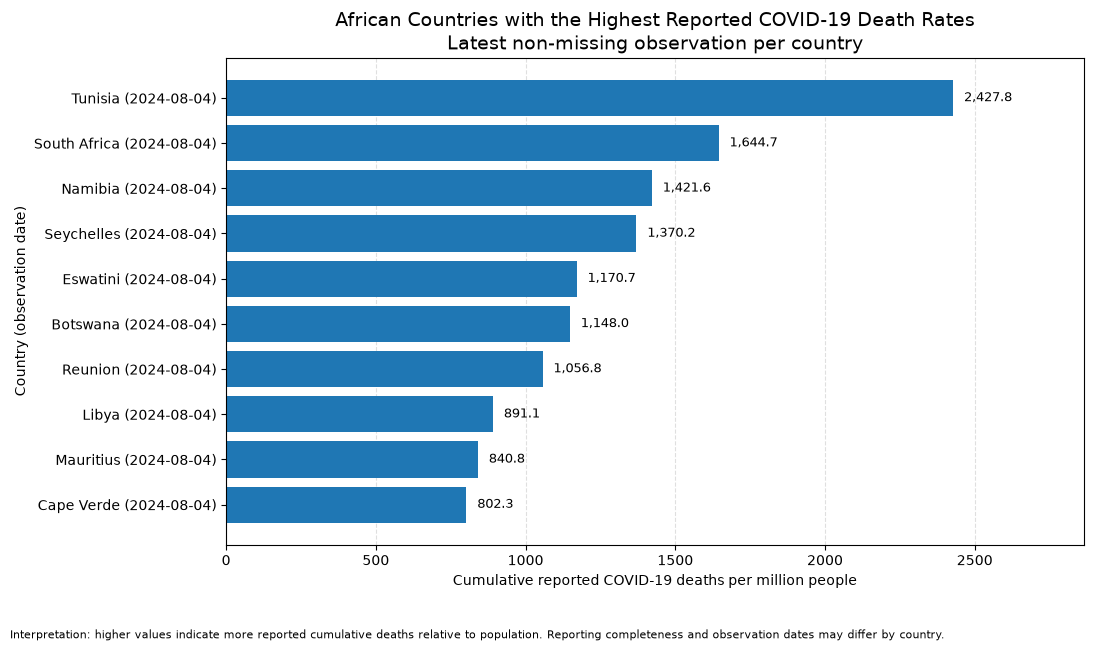


Top African countries by reported deaths per million:
    location       date total_deaths_per_million
     Tunisia 2024-08-04                  2,427.8
South Africa 2024-08-04                  1,644.7
     Namibia 2024-08-04                  1,421.6
  Seychelles 2024-08-04                  1,370.2
    Eswatini 2024-08-04                  1,170.7
    Botswana 2024-08-04                  1,148.0
     Reunion 2024-08-04                  1,056.8
       Libya 2024-08-04                    891.1
   Mauritius 2024-08-04                    840.8
  Cape Verde 2024-08-04                    802.3

Countries with valid observations: 57
Observation dates among the top 10: 2024-08-04 to 2024-08-04


In [32]:
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Load and prepare the data
# --------------------------------------------------
df = pd.read_csv("owid-covid-data.csv")

df["date"] = pd.to_datetime(df["date"], errors="coerce")

metric = "total_deaths_per_million"
df[metric] = pd.to_numeric(df[metric], errors="coerce")

# --------------------------------------------------
# 2. Select African countries, excluding aggregates
# --------------------------------------------------
continent = df["continent"].fillna("").astype(str).str.strip()
iso_code = df["iso_code"].fillna("").astype(str).str.strip()

africa = df.loc[
    continent.eq("Africa")
    & iso_code.ne("")
    & ~iso_code.str.startswith("OWID_")
].copy()

# --------------------------------------------------
# 3. Find the latest valid observation for each country
# --------------------------------------------------
# Exclude rows where the date or chosen measure is missing.
valid = africa.dropna(subset=["date", metric])

# Sort by date and keep one latest record per country.
latest = (
    valid.sort_values("date")
         .drop_duplicates(subset="iso_code", keep="last")
)

if latest.empty:
    raise ValueError(
        "No African country records with valid death-rate data were found."
    )

# --------------------------------------------------
# 4. Rank countries and select the top 10
# --------------------------------------------------
top10 = (
    latest.nlargest(10, metric)
          .sort_values(metric, ascending=True)
          .copy()
)

# Include the observation date so readers can see
# when each country's reported value was last updated.
top10["country_label"] = top10.apply(
    lambda row: (
        f"{row['location']} "
        f"({row['date']:%Y-%m-%d})"
    ),
    axis=1
)

# --------------------------------------------------
# 5. Create the horizontal bar chart
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    top10["country_label"],
    top10[metric]
)

ax.set_title(
    "African Countries with the Highest Reported "
    "COVID-19 Death Rates\n"
    "Latest non-missing observation per country",
    fontsize=14
)

ax.set_xlabel(
    "Cumulative reported COVID-19 deaths per million people"
)
ax.set_ylabel("Country (observation date)")

# Add a little space to the right for value labels.
max_value = max(top10[metric].max(), 1)
ax.set_xlim(0, max_value * 1.18)

# Label each bar with its numerical value.
for bar, value in zip(bars, top10[metric]):
    ax.text(
        bar.get_width() + max_value * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{value:,.1f}",
        va="center",
        fontsize=9
    )

ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

fig.text(
    0.01,
    0.01,
    "Interpretation: higher values indicate more reported "
    "cumulative deaths relative to population. Reporting "
    "completeness and observation dates may differ by country.",
    fontsize=8,
    wrap=True
)

plt.tight_layout(rect=[0, 0.06, 1, 0.93])
plt.show()

# --------------------------------------------------
# 6. Print the ranked results for reference
# --------------------------------------------------
print("\nTop African countries by reported deaths per million:")

print(
    top10[["location", "date", metric]]
    .sort_values(metric, ascending=False)
    .to_string(
        index=False,
        formatters={
            metric: lambda value: f"{value:,.1f}"
        }
    )
)

print(f"\nCountries with valid observations: {len(latest)}")
print(
    "Observation dates among the top 10:",
    top10["date"].min().date(),
    "to",
    top10["date"].max().date()
)

**Assessment: Valid – choice stated (same ranking as baseline, better caveats).** ChatGPT again ranked by deaths per million, with the same top 10 (Tunisia first). Unlike the baseline, it warned that rates for countries with small populations can be volatile, showed each country's observation date on the chart (all 4 August 2024) and printed a caveat on the chart itself. Réunion, a French territory, is still included.

### T04 (state choices). Show the 10 countries with the most COVID cases.

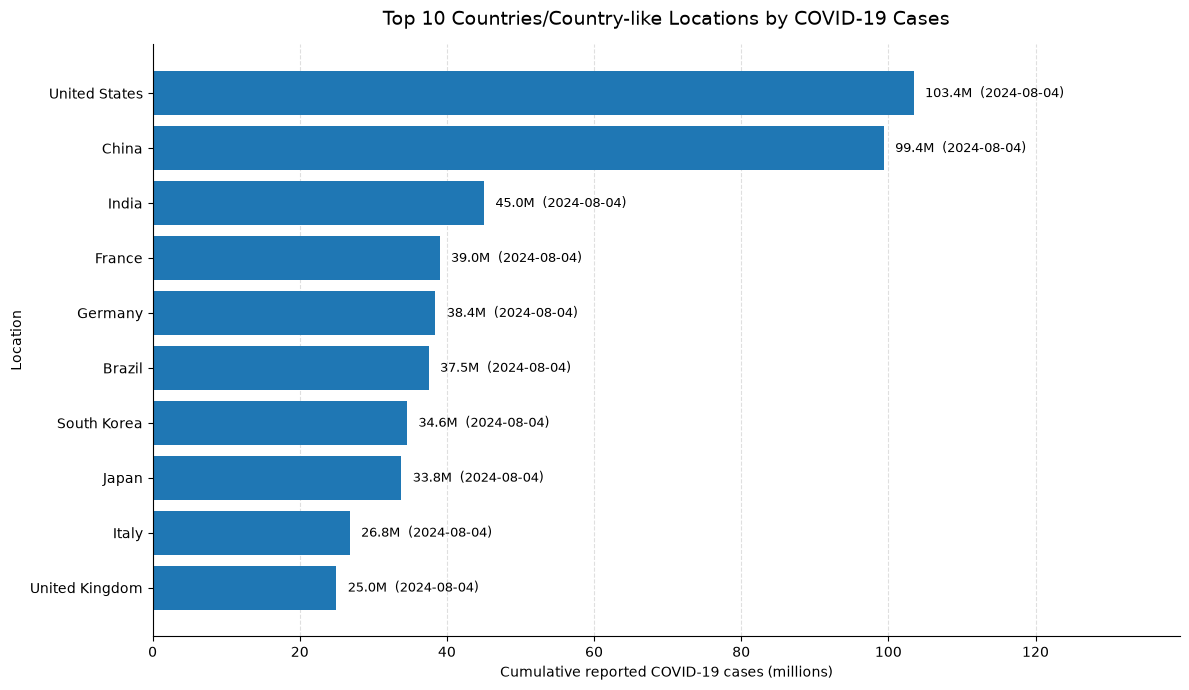

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# 1. Load the dataset
df = pd.read_csv("owid-covid-data.csv", low_memory=False)

# Ensure dates and case counts have appropriate data types
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["total_cases"] = pd.to_numeric(df["total_cases"], errors="coerce")

# 2. Keep country-like locations and valid observations.
# A non-missing continent excludes most aggregate rows, such as
# the world, continents, and income groups. Territories may remain.
eligible = df.loc[
    df["continent"].notna()
    & df["date"].notna()
    & df["total_cases"].notna(),
    ["location", "continent", "date", "total_cases"]
].copy()

if eligible.empty:
    raise ValueError(
        "No country-like locations with valid total_cases observations found."
    )

# 3. Get the latest non-missing cumulative case total for each location.
latest = (
    eligible
    .sort_values(["location", "date"])
    .drop_duplicates(subset="location", keep="last")
)

# 4. Select and rank the 10 locations with the highest case totals.
top10 = (
    latest
    .nlargest(10, "total_cases")
    .sort_values("total_cases", ascending=True)
    .copy()
)

# Convert case totals to millions for easier chart reading.
top10["cases_millions"] = top10["total_cases"] / 1_000_000

# 5. Create the horizontal bar chart.
fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    top10["location"],
    top10["cases_millions"]
)

# Add the total and the observation date beside each bar.
max_cases = top10["cases_millions"].max()

for bar, (_, row) in zip(bars, top10.iterrows()):
    cases = row["cases_millions"]
    report_date = row["date"].strftime("%Y-%m-%d")

    ax.text(
        bar.get_width() + max_cases * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{cases:,.1f}M  ({report_date})",
        va="center",
        fontsize=9
    )

# 6. Format the chart.
ax.set_title(
    "Top 10 Countries/Country-like Locations by COVID-19 Cases",
    fontsize=14,
    pad=14
)
ax.set_xlabel("Cumulative reported COVID-19 cases (millions)")
ax.set_ylabel("Location")

# Keep enough room for the case totals and dates displayed beside the bars.
ax.set_xlim(0, max_cases * 1.35 if max_cases > 0 else 1)

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:,.0f}")
)

ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

# Remove unnecessary borders for a cleaner chart.
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

**Assessment: Valid – choice stated (same as baseline).** ChatGPT kept absolute totals, correctly reasoning that the question asks for the most cases rather than the highest rate, and excluded the World, continent and income-group rows. The top 10 matches the baseline (United States, 103.4 million, first). It added each country's observation date beside its bar (all 4 August 2024) and labelled the chart "country-like locations" to acknowledge that territories could be included.

### T05 (state choices). How many people died of COVID in each continent? Show it as a bar chart.

Reported cumulative COVID-19 deaths by continent:
continent
Europe           2,102,483
North America    1,671,178
Asia             1,637,249
South America    1,354,187
Africa             259,117
Oceania             32,918
Name: total_deaths, dtype: str

Range of latest observation dates used:
                     min        max
continent                          
Africa        2024-08-04 2024-08-04
Asia          2024-08-04 2024-08-04
Europe        2024-08-04 2024-08-04
North America 2024-08-04 2024-08-04
Oceania       2024-08-04 2024-08-04
South America 2024-08-04 2024-08-04


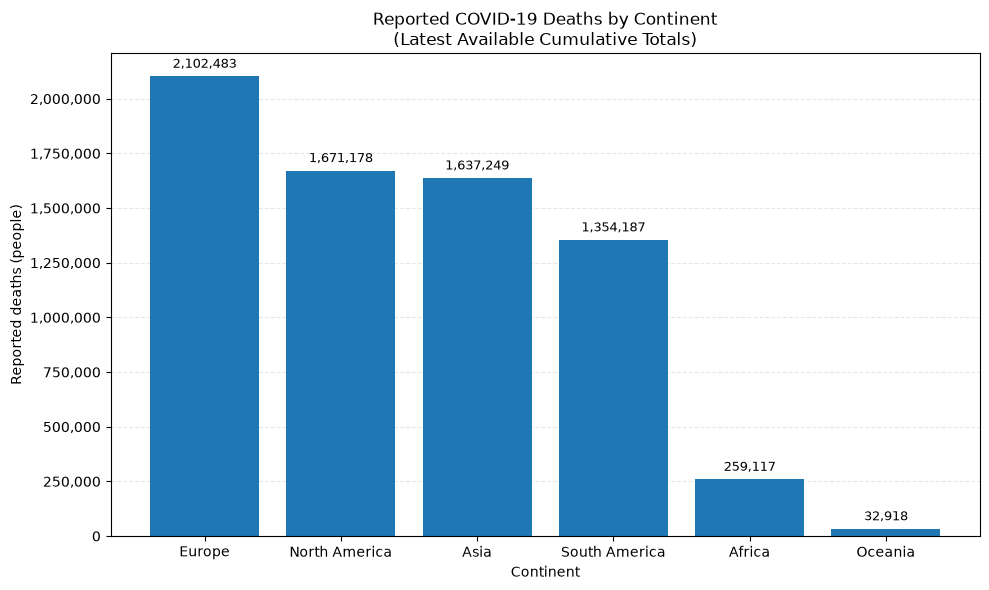

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# --------------------------------------------------
# 1. Load the dataset
# --------------------------------------------------
df = pd.read_csv("owid-covid-data.csv")

# Check that the necessary columns exist
required_columns = {"location", "continent", "date", "total_deaths"}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(
        f"The dataset is missing these columns: {missing_columns}"
    )

# Convert columns to suitable data types
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["total_deaths"] = pd.to_numeric(
    df["total_deaths"], errors="coerce"
)
df["continent"] = df["continent"].astype("string").str.strip()

# --------------------------------------------------
# 2. Select usable country/territory records
# --------------------------------------------------
# Exclude rows with missing continents, dates, or
# cumulative death counts. Aggregate rows without a
# continent assignment will also be excluded.

usable_rows = df.loc[
    df["continent"].notna()
    & df["continent"].ne("")
    & df["date"].notna()
    & df["total_deaths"].notna(),
    ["location", "continent", "date", "total_deaths"]
].copy()

if usable_rows.empty:
    raise ValueError("No usable rows were found in the dataset.")

# --------------------------------------------------
# 3. Keep the latest available death count per location
# --------------------------------------------------
# Do not sum across dates: total_deaths is cumulative.

latest_by_location = (
    usable_rows
    .sort_values(["location", "date"])
    .groupby(["location", "continent"], sort=False)
    .tail(1)
)

# --------------------------------------------------
# 4. Sum the location totals by continent
# --------------------------------------------------
continent_deaths = (
    latest_by_location
    .groupby("continent")["total_deaths"]
    .sum()
    .sort_values(ascending=False)
)

print("Reported cumulative COVID-19 deaths by continent:")
print(continent_deaths.round(0).astype("int64").map(
    lambda n: f"{n:,}"
))

# Show the range of latest observation dates included
# for each continent to reveal possible date differences.
date_coverage = (
    latest_by_location
    .groupby("continent")["date"]
    .agg(["min", "max"])
)

print("\nRange of latest observation dates used:")
print(date_coverage)

# --------------------------------------------------
# 5. Create the bar chart
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    continent_deaths.index,
    continent_deaths.values
)

ax.set_title(
    "Reported COVID-19 Deaths by Continent\n"
    "(Latest Available Cumulative Totals)"
)
ax.set_xlabel("Continent")
ax.set_ylabel("Reported deaths (people)")

# Format the vertical axis with thousands separators
ax.yaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

# Add the death total above each bar
for bar, value in zip(bars, continent_deaths.values):
    ax.annotate(
        f"{value:,.0f}",
        xy=(bar.get_x() + bar.get_width() / 2,
            bar.get_height()),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.xticks(rotation=0)
fig.tight_layout()
plt.show()

**Assessment: Valid – choice stated (silent error corrected).** Asked to set out its choices first, ChatGPT specified a two-step aggregation, taking each location's latest cumulative death total and then summing those totals within each continent, and illustrated why cumulative values must not be added across dates. The resulting totals (Europe 2.10 million, North America 1.67 million, Asia 1.64 million, South America 1.35 million, Africa 259,117, Oceania 32,918) match the dataset's own continent figures. In the baseline, the same question produced a chart in which each bar was a single country and Asia showed no deaths. The answer also printed the range of observation dates and noted that absolute totals reflect population size and reporting practices.

### T06 (state choices). What share of people in Africa were fully vaccinated against COVID?

Latest available observation: 2023-12-31
Share of people fully vaccinated: 32.4%


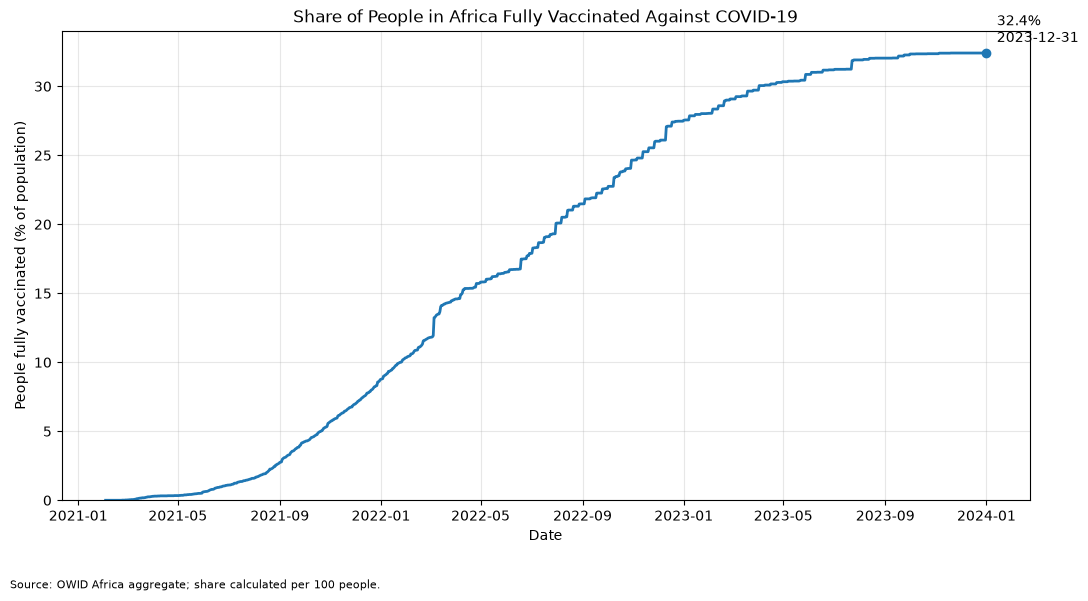

In [35]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the dataset
df = pd.read_csv("owid-covid-data.csv")

# Convert dates and vaccination/population fields to suitable types
df["date"] = pd.to_datetime(df["date"], errors="coerce")

for col in [
    "people_fully_vaccinated_per_hundred",
    "people_fully_vaccinated",
    "population",
]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 2. Prefer OWID's regional aggregate for Africa
africa = df.loc[
    df["location"].eq("Africa"),
    ["date", "people_fully_vaccinated_per_hundred"],
].copy()

africa = africa.rename(
    columns={
        "people_fully_vaccinated_per_hundred": "share_pct"
    }
)

africa = africa.dropna(subset=["date", "share_pct"])

if not africa.empty:
    series = africa[["date", "share_pct"]].copy()
    method_note = (
        "Source: OWID Africa aggregate; "
        "share calculated per 100 people."
    )

else:
    # 3. Fallback: use individual African locations
    countries = df.loc[df["continent"].eq("Africa")].copy()

    # Keep only records with a vaccination count and population
    valid = countries.dropna(
        subset=["date", "people_fully_vaccinated", "population"]
    )

    valid = valid.loc[valid["population"] > 0]

    # Aggregate counts and population by date.
    # This is population-weighted, not an average of country percentages.
    daily = (
        valid.groupby("date", as_index=False)
        .agg(
            fully_vaccinated=("people_fully_vaccinated", "sum"),
            population_covered=("population", "sum"),
        )
    )

    daily = daily.loc[daily["population_covered"] > 0].copy()

    daily["share_pct"] = (
        daily["fully_vaccinated"]
        / daily["population_covered"]
        * 100
    )

    series = daily[["date", "share_pct"]].copy()

    method_note = (
        "Fallback estimate: population-weighted share among "
        "African locations reporting both vaccination counts "
        "and population; coverage may vary by date."
    )

# 4. Clean and sort the time series
series = (
    series.dropna(subset=["date", "share_pct"])
    .sort_values("date")
    .drop_duplicates(subset=["date"], keep="last")
)

if series.empty:
    raise ValueError(
        "No usable African vaccination data was found in the CSV."
    )

# 5. Get the latest available estimate
latest = series.iloc[-1]

print(
    f"Latest available observation: {latest['date']:%Y-%m-%d}"
)
print(
    f"Share of people fully vaccinated: "
    f"{latest['share_pct']:.1f}%"
)

if (series["share_pct"] > 100).any():
    print(
        "Warning: Some percentages exceed 100%. "
        "Check reporting and population inconsistencies."
    )

# 6. Plot the results
fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    series["date"],
    series["share_pct"],
    linewidth=2,
)

# Emphasize the latest observation
ax.scatter(
    latest["date"],
    latest["share_pct"],
    zorder=3,
)

ax.annotate(
    f"{latest['share_pct']:.1f}%\n"
    f"{latest['date']:%Y-%m-%d}",
    xy=(latest["date"], latest["share_pct"]),
    xytext=(8, 8),
    textcoords="offset points",
)

ax.set_title(
    "Share of People in Africa Fully Vaccinated Against COVID-19"
)
ax.set_xlabel("Date")
ax.set_ylabel("People fully vaccinated (% of population)")
ax.set_ylim(bottom=0)
ax.grid(True, alpha=0.3)

# Explain which calculation was used
fig.text(
    0.01,
    0.01,
    method_note,
    ha="left",
    fontsize=8,
    wrap=True,
)

fig.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

**Assessment: Valid – choice stated (flagged error corrected).** In planning, ChatGPT noted that the dataset contains both a regional aggregate and country records and that a country-level sum would cover a changing set of reporting countries. It therefore used the dataset's own Africa series (people fully vaccinated per hundred), with a population-weighted country sum only as an unused fallback. The chart rises smoothly to 32.4% on 31 December 2023, the correct figure; the baseline, which summed whichever countries reported on each date, swung between almost 0% and 62.8% and reported 23.7%.

### T07 (state choices). Were there more COVID deaths in the United States in 2021 or in 2022? Make a chart.

Increase in cumulative reported COVID-19 deaths:
2021: 469,667
2022: 267,389

There were more reported COVID-19 deaths in 2021.


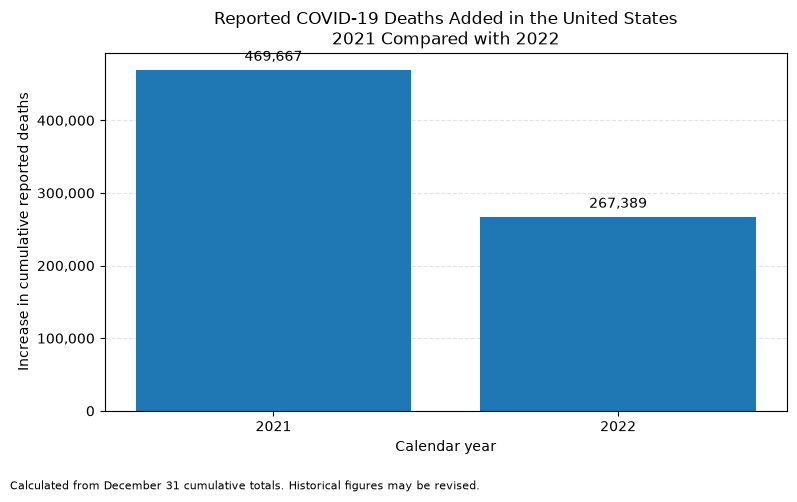

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# --------------------------------------------------
# 1. Load the dataset
# --------------------------------------------------
df = pd.read_csv(
    "owid-covid-data.csv",
    parse_dates=["date"]
)

# --------------------------------------------------
# 2. Keep only United States country-level records
# --------------------------------------------------
us = df.loc[
    (df["iso_code"] == "USA") &
    (df["location"] == "United States"),
    ["date", "total_deaths"]
].copy()

if us.empty:
    raise ValueError(
        "No United States records found. Check the CSV file and filters."
    )

us["date"] = pd.to_datetime(us["date"], errors="coerce")
us["total_deaths"] = pd.to_numeric(
    us["total_deaths"], errors="coerce"
)
us = us.dropna(subset=["date"])

# The comparison requires one record per date.
if us["date"].duplicated().any():
    raise ValueError(
        "Duplicate United States dates found. "
        "Check the data before calculating annual totals."
    )

# --------------------------------------------------
# 3. Get cumulative deaths at each year-end
# --------------------------------------------------
year_end_dates = [
    pd.Timestamp("2020-12-31"),
    pd.Timestamp("2021-12-31"),
    pd.Timestamp("2022-12-31"),
]

cumulative_deaths = {}

for date in year_end_dates:
    values = us.loc[
        us["date"] == date, "total_deaths"
    ].dropna()

    if values.empty:
        raise ValueError(
            f"Missing cumulative death total for {date.date()}. "
            "Check whether the CSV contains a valid value "
            "for this exact date."
        )

    cumulative_deaths[date.year] = float(values.iloc[0])

# --------------------------------------------------
# 4. Calculate the increase during each calendar year
# --------------------------------------------------
annual_deaths = {
    2021: (
        cumulative_deaths[2021] - cumulative_deaths[2020]
    ),
    2022: (
        cumulative_deaths[2022] - cumulative_deaths[2021]
    ),
}

print("Increase in cumulative reported COVID-19 deaths:")
for year, deaths in annual_deaths.items():
    print(f"{year}: {deaths:,.0f}")

if annual_deaths[2021] > annual_deaths[2022]:
    print("\nThere were more reported COVID-19 deaths in 2021.")
elif annual_deaths[2022] > annual_deaths[2021]:
    print("\nThere were more reported COVID-19 deaths in 2022.")
else:
    print("\nThe reported totals were equal.")

# --------------------------------------------------
# 5. Create the bar chart
# --------------------------------------------------
years = list(annual_deaths.keys())
deaths = list(annual_deaths.values())

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    [str(year) for year in years],
    deaths
)

# Add the numerical total above each bar.
ax.bar_label(
    bars,
    labels=[f"{value:,.0f}" for value in deaths],
    padding=4
)

ax.set_title(
    "Reported COVID-19 Deaths Added in the United States\n"
    "2021 Compared with 2022"
)
ax.set_xlabel("Calendar year")
ax.set_ylabel("Increase in cumulative reported deaths")
ax.yaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

fig.text(
    0.01,
    0.01,
    "Calculated from December 31 cumulative totals. "
    "Historical figures may be revised.",
    fontsize=8
)

fig.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

**Assessment: Valid – choice stated (same as baseline).** ChatGPT calculated each year's deaths as the difference between consecutive year-end cumulative totals (2021: 469,667; 2022: 267,389) and correctly concluded that 2021 had more deaths. This differs from the baseline method (summing new deaths within each year) but gives identical figures. The plan stated the formula explicitly, the code stops if a year-end value is missing, and a note on the chart explains the calculation.

### T08 (state choices). Plot how COVID deaths changed over time in Italy.

Number of Italy date rows: 1677
Missing daily death counts: 3


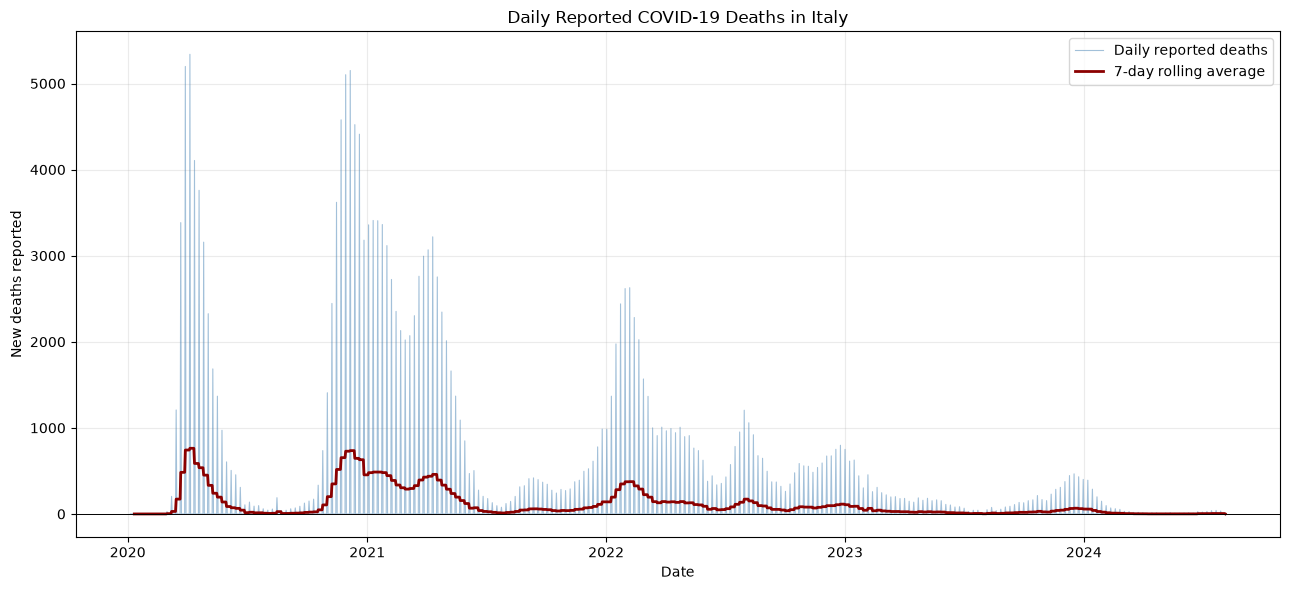

In [37]:

import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the Our World in Data COVID-19 dataset.
df = pd.read_csv(
    "owid-covid-data.csv",
    parse_dates=["date"]
)

# 2. Keep only observations for Italy.
italy = (
    df.loc[df["location"].eq("Italy"), ["date", "new_deaths"]]
    .sort_values("date")
    .copy()
)

if italy.empty:
    raise ValueError("No rows were found for Italy in the dataset.")

# 3. Check whether there is more than one row per date.
duplicate_dates = italy.loc[
    italy["date"].duplicated(keep=False), "date"
].drop_duplicates()

if not duplicate_dates.empty:
    print("Warning: duplicate dates found for Italy:")
    print(duplicate_dates.to_list())
    print("Investigate these rows before interpreting the chart.")

# 4. Report missing values and retain them as missing.
missing_count = italy["new_deaths"].isna().sum()
print(f"Number of Italy date rows: {len(italy)}")
print(f"Missing daily death counts: {missing_count}")

# 5. Compute a seven-calendar-day rolling average.
# min_periods=7 means the average is shown only when all
# seven calendar-day observations are available and non-missing.
italy["new_deaths_7day_avg"] = (
    italy.set_index("date")["new_deaths"]
    .rolling("7D", min_periods=7)
    .mean()
    .to_numpy()
)

# 6. Plot daily reported deaths and the rolling average.
fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    italy["date"],
    italy["new_deaths"],
    color="steelblue",
    linewidth=0.8,
    alpha=0.5,
    label="Daily reported deaths"
)

ax.plot(
    italy["date"],
    italy["new_deaths_7day_avg"],
    color="darkred",
    linewidth=2,
    label="7-day rolling average"
)

ax.axhline(0, color="black", linewidth=0.7)
ax.set_title("Daily Reported COVID-19 Deaths in Italy")
ax.set_xlabel("Date")
ax.set_ylabel("New deaths reported")
ax.grid(True, alpha=0.25)
ax.legend()
fig.tight_layout()

plt.show()


**Assessment: Flagged analytical error (improved on baseline).** In planning, ChatGPT reasoned that cumulative deaths only rise and would hide changes, and plotted new deaths with a 7-day rolling average. The rolling average is correct (it matches the dataset's own smoothed series, peaking at about 763 deaths per day in April 2020), but it is drawn alongside the raw series, labelled "Daily reported deaths", which consists of weekly totals recorded on Sundays (up to 5,339). These weekly spikes set the scale of the y-axis and dominate the chart, so the obvious reading overstates daily deaths about sevenfold. The answer warned that deaths may be reported in batches but did not identify the weekly structure.

### T09 (state choices). Did COVID deaths in the United Kingdom fall after vaccines were rolled out?

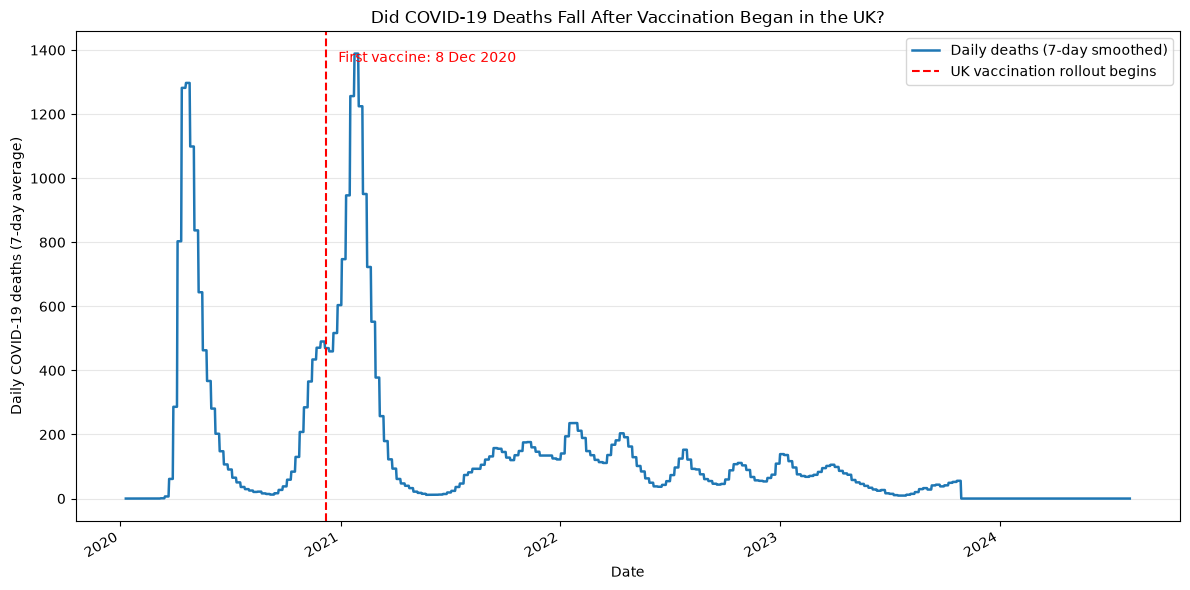

In [38]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the dataset
file_path = "owid-covid-data.csv"
df = pd.read_csv(file_path)

# 2. Select only the United Kingdom's records
uk = df.loc[
    df["location"] == "United Kingdom",
    ["date", "new_deaths_smoothed"]
].copy()

# 3. Convert columns to suitable data types
uk["date"] = pd.to_datetime(uk["date"], errors="coerce")
uk["new_deaths_smoothed"] = pd.to_numeric(
    uk["new_deaths_smoothed"], errors="coerce"
)

# 4. Remove missing observations and sort chronologically
uk = (
    uk.dropna(subset=["date", "new_deaths_smoothed"])
      .sort_values("date")
)

if uk.empty:
    raise ValueError(
        "No valid United Kingdom death data was found in the CSV."
    )

# 5. Set the date of the first UK vaccination
rollout_date = pd.Timestamp("2020-12-08")

# 6. Create the chart
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    uk["date"],
    uk["new_deaths_smoothed"],
    linewidth=1.8,
    label="Daily deaths (7-day smoothed)"
)

# Mark the start of the vaccination rollout
ax.axvline(
    rollout_date,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="UK vaccination rollout begins"
)

# Add a label near the top of the chart
ax.text(
    rollout_date + pd.Timedelta(days=20),
    0.96,
    "First vaccine: 8 Dec 2020",
    transform=ax.get_xaxis_transform(),
    color="red",
    verticalalignment="top"
)

# 7. Add titles and labels
ax.set_title(
    "Did COVID-19 Deaths Fall After Vaccination Began in the UK?"
)
ax.set_xlabel("Date")
ax.set_ylabel("Daily COVID-19 deaths (7-day average)")

ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

**Assessment: Valid – choice stated (same as baseline; cleaner design).** ChatGPT plotted the dataset's 7-day smoothed daily deaths, explaining that cumulative deaths would hide declines, and marked the start of the UK rollout (8 December 2020) with a vertical line. Its caveats noted that the association is not causal, that coverage rose gradually after the first dose, and that later waves should be considered. Unlike the baseline, it avoids a dual y-axis, but it no longer shows vaccination coverage itself. As in the baseline, the chart's flat line at zero from November 2023 reflects the end of UK reporting to this dataset, which is not mentioned.

### T10 (state choices). On which single day did the most people die of COVID in the United States?

Highest daily reported COVID-19 deaths in the U.S.
Reported deaths: 23,312
Peak date(s):
2021-01-17


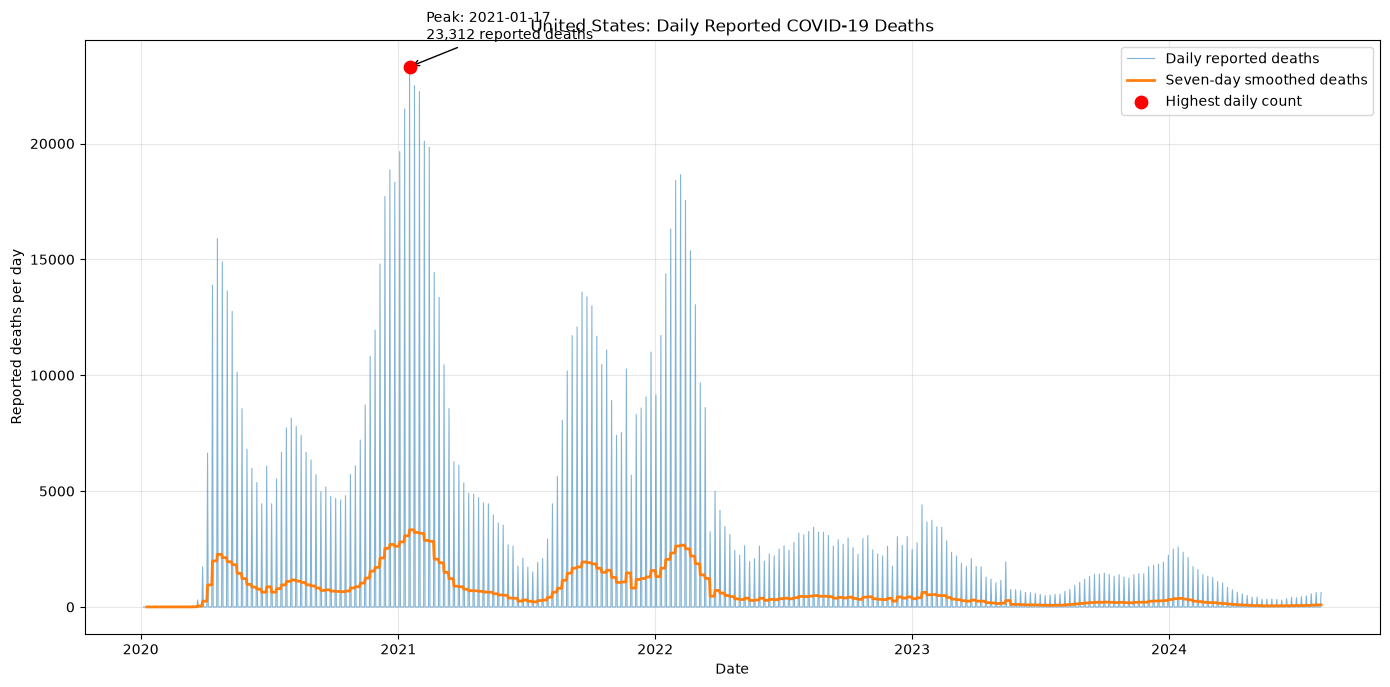

In [39]:
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Load the dataset
# --------------------------------------------------
file_path = "owid-covid-data.csv"

df = pd.read_csv(file_path)

# Parse dates and convert death counts to numeric values.
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["new_deaths"] = pd.to_numeric(
    df["new_deaths"], errors="coerce"
)
df["new_deaths_smoothed"] = pd.to_numeric(
    df["new_deaths_smoothed"], errors="coerce"
)

# --------------------------------------------------
# 2. Select the national-level United States records
# --------------------------------------------------
us = df.loc[
    df["location"].eq("United States")
].copy()

if us.empty:
    raise ValueError(
        "No rows found for location = 'United States'. "
        "Check the location names in the CSV."
    )

# Exclude records that cannot be used to identify a peak.
us = us.dropna(subset=["date", "new_deaths"])

# The dataset is expected to have one row per location/date.
# Stop rather than silently double-counting unexpected duplicates.
if us["date"].duplicated().any():
    duplicates = us.loc[
        us["date"].duplicated(keep=False), "date"
    ].sort_values()

    raise ValueError(
        "Duplicate United States dates found. "
        f"Investigate these dates before proceeding:\n"
        f"{duplicates.to_list()}"
    )

# Sort chronologically for plotting.
us = us.sort_values("date").reset_index(drop=True)

if us.empty:
    raise ValueError(
        "No valid U.S. daily death counts are available."
    )

# --------------------------------------------------
# 3. Identify the maximum single-day reported death count
# --------------------------------------------------
max_deaths = us["new_deaths"].max()

# Keep all dates in case multiple days share the same maximum.
peak_rows = us.loc[
    us["new_deaths"].eq(max_deaths)
]

# Print the result.
print("Highest daily reported COVID-19 deaths in the U.S.")
print(f"Reported deaths: {max_deaths:,.0f}")
print("Peak date(s):")

for date in peak_rows["date"]:
    print(date.strftime("%Y-%m-%d"))

# --------------------------------------------------
# 4. Plot daily deaths and the smoothed trend
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 7))

# Raw daily reported deaths: this series determines the answer.
ax.plot(
    us["date"],
    us["new_deaths"],
    linewidth=0.8,
    alpha=0.55,
    label="Daily reported deaths"
)

# Seven-day smoothed series: context only.
ax.plot(
    us["date"],
    us["new_deaths_smoothed"],
    linewidth=2,
    label="Seven-day smoothed deaths"
)

# Highlight every date tied for the maximum raw daily count.
ax.scatter(
    peak_rows["date"],
    peak_rows["new_deaths"],
    color="red",
    s=80,
    zorder=5,
    label="Highest daily count"
)

# Annotate the first peak; all tied dates are printed above.
peak = peak_rows.iloc[0]

ax.annotate(
    f"Peak: {peak['date']:%Y-%m-%d}\n"
    f"{max_deaths:,.0f} reported deaths",
    xy=(peak["date"], peak["new_deaths"]),
    xytext=(12, 20),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"},
    fontsize=10
)

ax.set_title(
    "United States: Daily Reported COVID-19 Deaths"
)
ax.set_xlabel("Date")
ax.set_ylabel("Reported deaths per day")
ax.legend()
ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

**Assessment: Flagged analytical error (improved from silent).** ChatGPT again reported 17 January 2021, with 23,312 deaths, as the single deadliest day; in this dataset that figure is the weekly total recorded on a Sunday (about 3,330 per day). Unlike the baseline, its plan warned that a large daily count "may reflect deaths reported together after a delay, rather than an unusually large number of deaths occurring on that particular day", and the chart adds the 7-day smoothed series for context. It did not identify that all US deaths in the dataset are reported weekly, so it still answered with a single day.

### T11 (state choices). What percentage of the population is vaccinated in each G7 country?

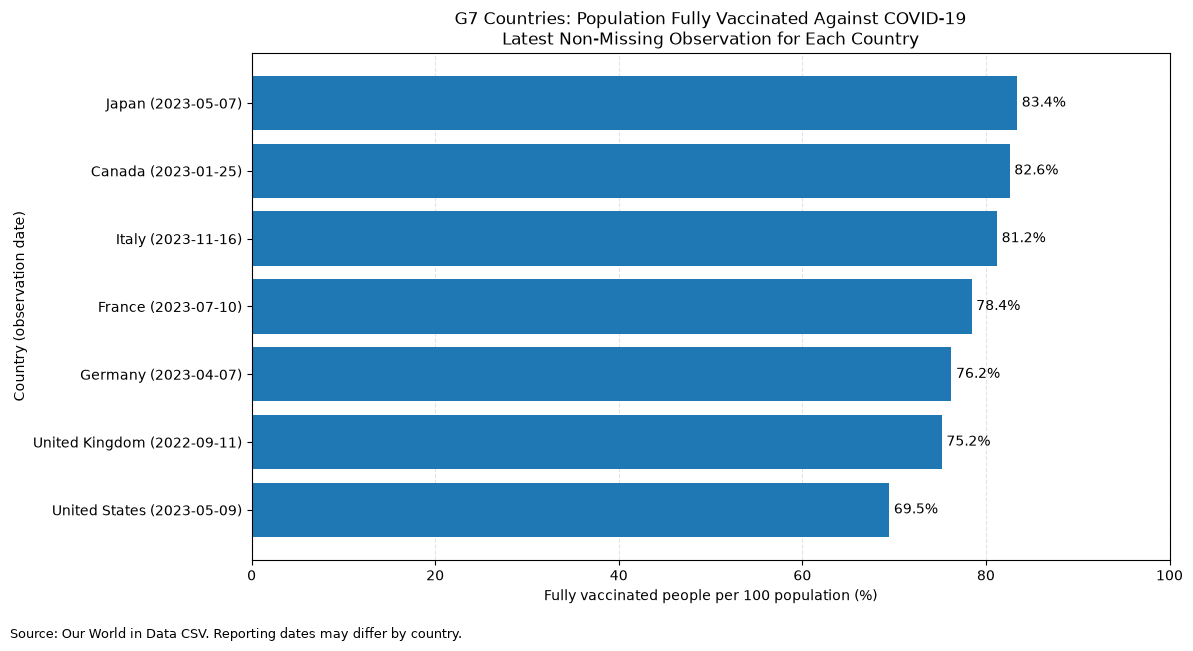

In [40]:
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Configure the file, countries, and measure
# --------------------------------------------------
file_path = "owid-covid-data.csv"

g7_countries = [
    "Canada",
    "France",
    "Germany",
    "Italy",
    "Japan",
    "United Kingdom",
    "United States"
]

metric = "people_fully_vaccinated_per_hundred"

# Load only the columns needed for this analysis
df = pd.read_csv(
    file_path,
    usecols=["location", "date", metric],
    parse_dates=["date"]
)

# --------------------------------------------------
# 2. Keep only the seven G7 countries
# --------------------------------------------------
g7 = df.loc[df["location"].isin(g7_countries)].copy()

# Make sure the vaccination measure is numeric
g7[metric] = pd.to_numeric(g7[metric], errors="coerce")

# Missing dates or rates cannot be used for the chart
g7 = g7.dropna(subset=["date", metric])

# --------------------------------------------------
# 3. Get each country's latest usable observation
# --------------------------------------------------
latest = (
    g7.sort_values(["location", "date"])
      .drop_duplicates(subset="location", keep="last")
      .copy()
)

# Do not silently omit countries with no usable data
missing_countries = sorted(
    set(g7_countries) - set(latest["location"])
)

if missing_countries:
    raise ValueError(
        "No usable vaccination data found for: "
        + ", ".join(missing_countries)
    )

# Add each observation date to the country label
latest["country_label"] = latest.apply(
    lambda row: (
        f"{row['location']} ({row['date']:%Y-%m-%d})"
    ),
    axis=1
)

# Sort from lowest to highest vaccination percentage
latest = latest.sort_values(metric, ascending=True)

# --------------------------------------------------
# 4. Create the horizontal bar chart
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 6.5))

bars = ax.barh(
    latest["country_label"],
    latest[metric]
)

# Allow values above 100 to remain visible
max_rate = latest[metric].max()
x_max = max(100.0, max_rate * 1.12 + 1)
ax.set_xlim(0, x_max)

# Add percentage labels at the end of each bar
label_offset = max(0.5, x_max * 0.005)

for bar, value in zip(bars, latest[metric]):
    ax.text(
        value + label_offset,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center",
        ha="left"
    )

ax.set_title(
    "G7 Countries: Population Fully Vaccinated Against COVID-19\n"
    "Latest Non-Missing Observation for Each Country"
)

ax.set_xlabel(
    "Fully vaccinated people per 100 population (%)"
)
ax.set_ylabel("Country (observation date)")

# Improve readability
ax.set_axisbelow(True)
ax.grid(axis="x", linestyle="--", alpha=0.35)

fig.text(
    0.01,
    0.01,
    "Source: Our World in Data CSV. Reporting dates may differ by country.",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.04, 1, 1])

plt.show()

**Assessment: Valid – choice stated (same as baseline).** ChatGPT used the share of people fully vaccinated rather than doses, explained the difference between one dose and a completed course, selected the seven G7 countries by name and showed each country's observation date beside its name, with a note on the chart that dates differ. It also anticipated that rates can exceed 100% because of population or reporting issues and chose not to cap the axis. The baseline showed both one-dose and full-vaccination shares without dates on the chart.

### T12 (state choices). Which countries vaccinated the most people against COVID?

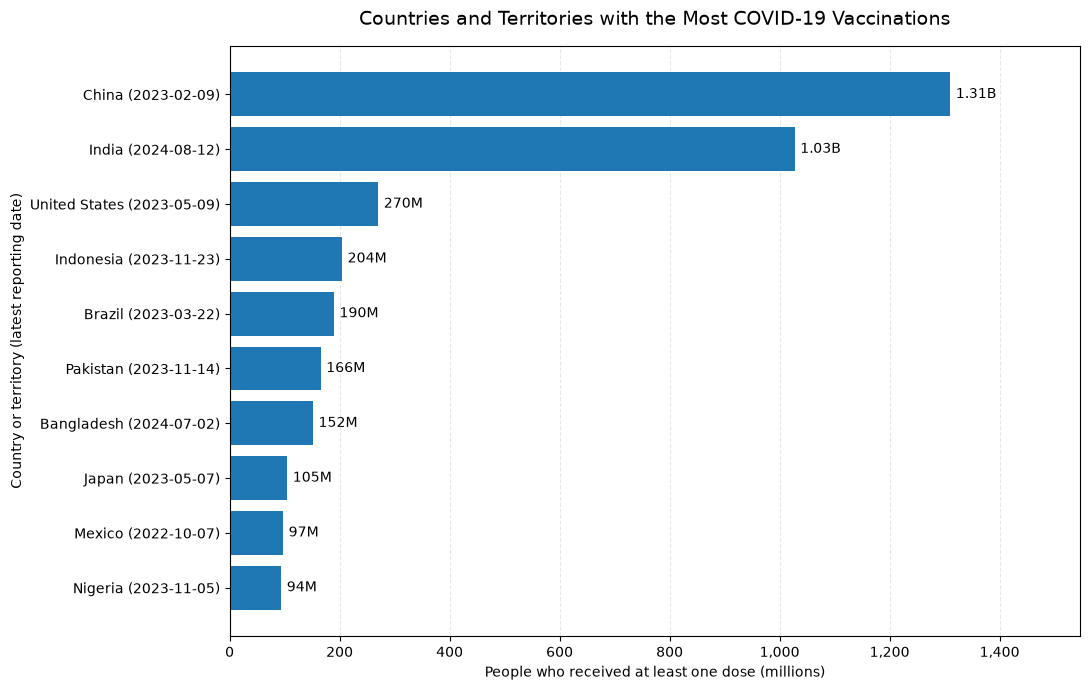

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# --------------------------------------------------
# 1. Load the dataset
# --------------------------------------------------

file_path = "owid-covid-data.csv"
df = pd.read_csv(file_path)

# Check that the necessary columns are present.
required_columns = {
    "iso_code",
    "location",
    "date",
    "people_vaccinated"
}

missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(
        f"The CSV file is missing these columns: {missing_columns}"
    )

# --------------------------------------------------
# 2. Clean the relevant columns
# --------------------------------------------------

df["date"] = pd.to_datetime(df["date"], errors="coerce")

df["people_vaccinated"] = pd.to_numeric(
    df["people_vaccinated"],
    errors="coerce"
)

# Normalize ISO codes for consistent filtering.
df["_iso_code"] = df["iso_code"].fillna("").str.upper()

# Include entries with standard three-letter ISO codes.
# Kosovo is included separately because OWID uses OWID_KOS.
is_country_or_territory = (
    df["_iso_code"].str.fullmatch(r"[A-Z]{3}", na=False)
    | df["_iso_code"].eq("OWID_KOS")
)

# Exclude rows without a usable date or vaccination count.
valid_rows = (
    is_country_or_territory
    & df["date"].notna()
    & df["people_vaccinated"].notna()
)

df_clean = df.loc[
    valid_rows,
    ["_iso_code", "location", "date", "people_vaccinated"]
].copy()

if df_clean.empty:
    raise ValueError(
        "No valid country/territory vaccination observations were found."
    )

# --------------------------------------------------
# 3. Find the latest available observation per entry
# --------------------------------------------------

# The values are cumulative, so do not sum across dates.
# Select the latest date with a non-missing vaccination count
# for each country or territory.

latest = (
    df_clean
    .sort_values(["_iso_code", "date"])
    .drop_duplicates(subset="_iso_code", keep="last")
)

# --------------------------------------------------
# 4. Rank countries and select the top 10
# --------------------------------------------------

top_10 = (
    latest
    .nlargest(10, "people_vaccinated")
    .copy()
)

# Convert counts to millions for plotting.
top_10["vaccinated_millions"] = (
    top_10["people_vaccinated"] / 1_000_000
)

# Include each entry's latest reporting date in its label.
top_10["chart_label"] = (
    top_10["location"].fillna(top_10["_iso_code"])
    + " ("
    + top_10["date"].dt.strftime("%Y-%m-%d")
    + ")"
)

# --------------------------------------------------
# 5. Create the horizontal bar chart
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    top_10["chart_label"],
    top_10["vaccinated_millions"]
)

# Show the largest value at the top.
ax.invert_yaxis()

ax.set_title(
    "Countries and Territories with the Most COVID-19 Vaccinations",
    fontsize=14,
    pad=15
)

ax.set_xlabel(
    "People who received at least one dose (millions)"
)

ax.set_ylabel("Country or territory (latest reporting date)")

# Format the horizontal axis using millions of people.
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, position: f"{x:,.0f}")
)

# Format bar-end labels using millions or billions.
def format_people(value):
    if value >= 1_000_000_000:
        return f"{value / 1_000_000_000:.2f}B"
    return f"{value / 1_000_000:.0f}M"

labels = [
    format_people(value)
    for value in top_10["people_vaccinated"]
]

ax.bar_label(
    bars,
    labels=labels,
    padding=4
)

# Leave space on the right for the bar-end labels.
max_value = top_10["vaccinated_millions"].max()

ax.set_xlim(
    0,
    max_value * 1.18 if max_value > 0 else 1
)

ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

**Assessment: Valid – choice stated (same as baseline).** ChatGPT counted people with at least one dose rather than doses administered, kept absolute totals because the question asks about the most people, excluded aggregate rows using three-letter country codes while deliberately retaining Kosovo (which has an OWID_ code), and showed each country's reporting date. China (1.31 billion) and India (1.03 billion) lead; Nigeria enters the top 10 at 94 million. The baseline used people fully vaccinated, which is also a count of people.

### T13 (state choices). Compare COVID vaccination rates across European countries.

In [42]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Load the data and validate the required columns
# --------------------------------------------------

file_path = Path("owid-covid-data.csv")
rate_col = "people_fully_vaccinated_per_hundred"

df = pd.read_csv(file_path, low_memory=False)

required_cols = {
    "iso_code",
    "continent",
    "location",
    "date",
    rate_col,
}

missing_cols = required_cols - set(df.columns)

if missing_cols:
    raise ValueError(
        f"The CSV is missing required columns: {sorted(missing_cols)}"
    )

# Convert date and vaccination rate to appropriate data types.
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df[rate_col] = pd.to_numeric(df[rate_col], errors="coerce")


# --------------------------------------------------
# 2. Keep European countries, excluding aggregates
# --------------------------------------------------

# Standard three-letter ISO codes help exclude OWID aggregate
# rows such as continents and the world. Locations without
# standard ISO alpha-3 codes, such as OWID_KOS, are also excluded.
iso_codes = df["iso_code"].astype("string")

country_mask = (
    df["continent"].eq("Europe")
    & iso_codes.str.fullmatch(r"[A-Z]{3}", na=False)
)

europe = df.loc[
    country_mask,
    ["iso_code", "location", "date", rate_col],
].copy()

if europe.empty:
    raise ValueError("No European country records were found.")

all_country_codes = set(europe["iso_code"].dropna())

# Rows without a usable date cannot be used to identify the
# latest observation.
invalid_dates = europe["date"].isna().sum()

if invalid_dates:
    print(f"Excluding {invalid_dates} rows with invalid or missing dates.")

europe = europe.dropna(subset=["date"]).copy()


# --------------------------------------------------
# 3. Check for duplicate country-date records
# --------------------------------------------------

duplicates = europe.duplicated(
    subset=["iso_code", "date"],
    keep=False,
)

if duplicates.any():
    print("Duplicate country-date records detected:")
    print(
        europe.loc[
            duplicates,
            ["iso_code", "location", "date", rate_col],
        ]
        .sort_values(["iso_code", "date"])
        .to_string(index=False)
    )

    raise ValueError(
        "Resolve duplicate country-date records before plotting "
        "to avoid an arbitrary comparison."
    )


# --------------------------------------------------
# 4. Select each country's latest non-missing rate
# --------------------------------------------------

# Do not replace missing vaccination rates with zero.
# Select the latest available non-missing rate for each country.
latest = (
    europe.dropna(subset=[rate_col])
    .sort_values(["iso_code", "date"])
    .drop_duplicates(subset=["iso_code"], keep="last")
    .copy()
)

# Report countries that have no usable vaccination-rate record.
country_names = (
    europe.groupby("iso_code")["location"]
    .first()
    .to_dict()
)

missing_rate_codes = sorted(
    all_country_codes - set(latest["iso_code"])
)

if missing_rate_codes:
    missing_names = [
        country_names.get(code, code)
        for code in missing_rate_codes
    ]
    print(
        "Countries without a usable vaccination-rate observation:",
        ", ".join(missing_names),
    )


# --------------------------------------------------
# 5. Exclude out-of-range rates
# --------------------------------------------------

# The measure is a percentage of the population. Values outside
# 0–100 require investigation and are excluded from this chart.
invalid_rates = ~latest[rate_col].between(0, 100)

if invalid_rates.any():
    print("Excluding countries with out-of-range latest rates:")
    print(
        latest.loc[
            invalid_rates,
            ["location", "date", rate_col],
        ].to_string(index=False)
    )

latest = latest.loc[~invalid_rates].copy()

if latest.empty:
    raise ValueError(
        "No valid European vaccination-rate observations remain."
    )


# --------------------------------------------------
# 6. Sort countries and label observations by date
# --------------------------------------------------

latest["country_label"] = (
    latest["location"]
    + " ("
    + latest["date"].dt.strftime("%Y-%m-%d")
    + ")"
)

# For a horizontal bar chart, ascending order places the
# highest value at the top.
plot_data = latest.sort_values(
    rate_col,
    ascending=True,
)


# --------------------------------------------------
# 7. Draw the horizontal bar chart
# --------------------------------------------------

fig_height = max(8, 0.32 * len(plot_data))

fig, ax = plt.subplots(figsize=(12, fig_height))

bars = ax.barh(
    plot_data["country_label"],
    plot_data[rate_col],
)

# Add percentage labels to the bars.
for bar, value in zip(bars, plot_data[rate_col]):
    ax.text(
        value + 0.8,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center",
        ha="left",
        fontsize=8,
    )

ax.set_xlim(0, 110)
ax.set_xticks(range(0, 101, 20))

ax.set_xlabel("Population fully vaccinated (%)")
ax.set_ylabel("Country (date of latest reported value)")

ax.set_title(
    "COVID-19 Full Vaccination Coverage in European Countries\n"
    "Latest Available Observation for Each Country"
)

ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

Duplicate country-date records detected:
iso_code      location       date  people_fully_vaccinated_per_hundred
     FRO Faroe Islands 2021-01-29                                 0.00
     FRO Faroe Islands 2021-01-29                                  NaN
     FRO Faroe Islands 2021-01-30                                  NaN
     FRO Faroe Islands 2021-01-30                                  NaN
     FRO Faroe Islands 2021-01-31                                  NaN
     FRO Faroe Islands 2021-01-31                                  NaN
     FRO Faroe Islands 2021-02-01                                  NaN
     FRO Faroe Islands 2021-02-01                                  NaN
     FRO Faroe Islands 2021-02-02                                  NaN
     FRO Faroe Islands 2021-02-02                                  NaN
     FRO Faroe Islands 2021-02-03                                  NaN
     FRO Faroe Islands 2021-02-03                                  NaN
     FRO Faroe Islands 2021-02-04   

ValueError: Resolve duplicate country-date records before plotting to avoid an arbitrary comparison.

**Assessment: Visible error (no chart produced).** ChatGPT's stated plan addressed both problems in the baseline: it kept only standard three-letter country codes, which excludes England, Scotland, Wales and Northern Ireland, and it planned to exclude and report values above 100%, such as Gibraltar's. It also added a check for duplicate country-date records. That check found a genuine issue in the dataset: the Faroe Islands has two rows for most dates between 29 January 2021 and 26 February 2022 (788 rows in total, typically one with a value and one blank). Rather than resolving this, for example by keeping the row with a value, the code deliberately stopped with a ValueError at line 89, so no chart was produced. In the baseline, the same question produced a misleading chart with no warning; here the failure is visible rather than silent, but the user receives no answer.

### T14 (state choices). Show each country's latest COVID death rate per million.

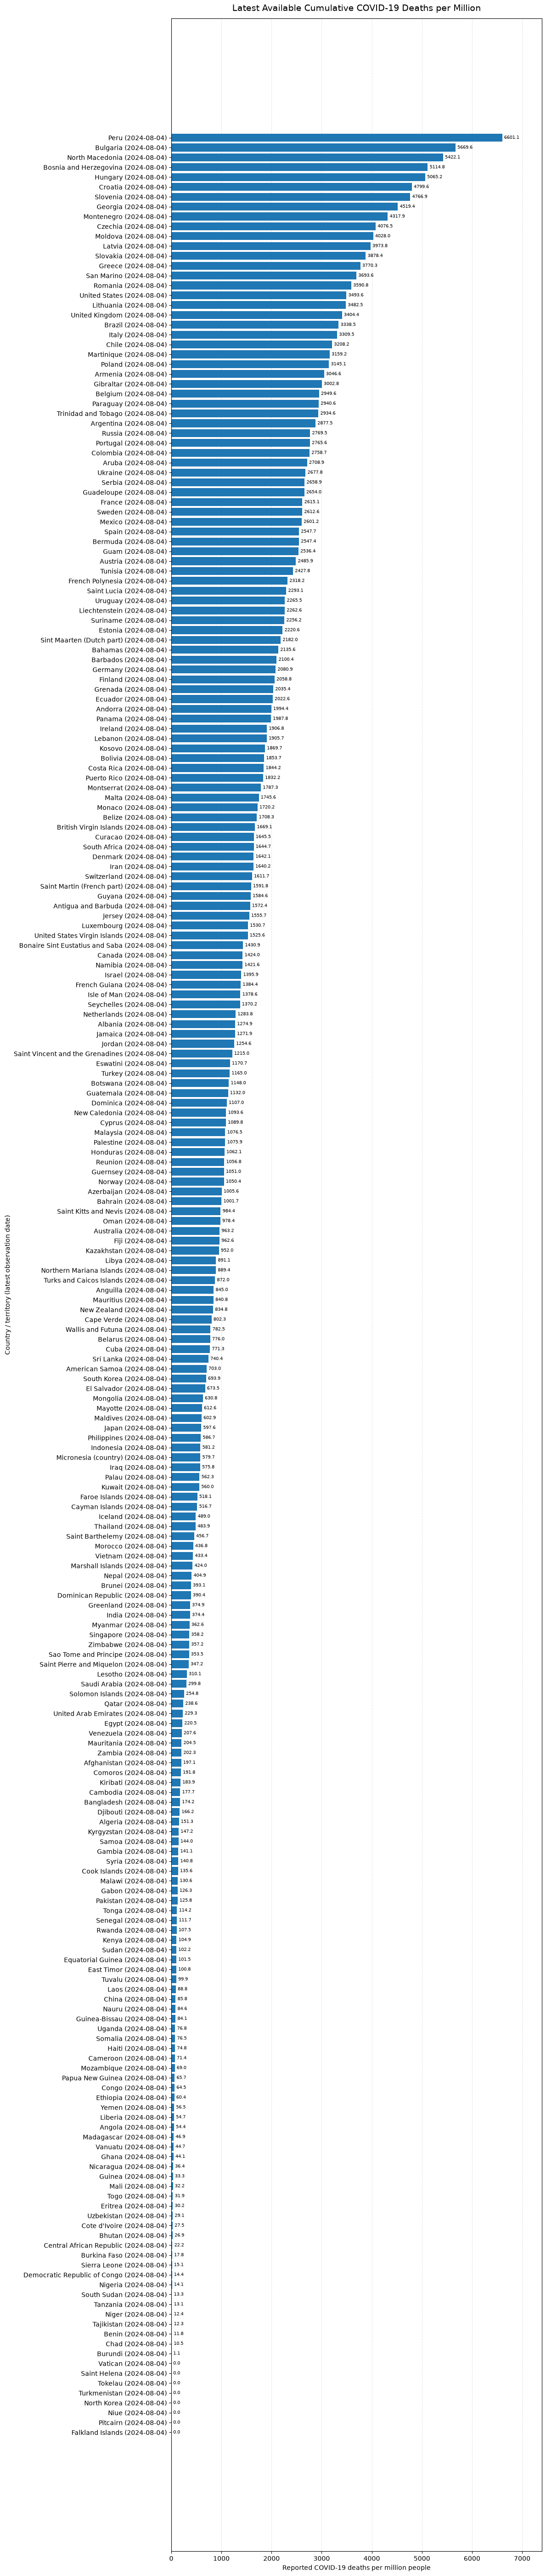

                        location       date  total_deaths_per_million
                            Peru 2024-08-04                   6601.11
                        Bulgaria 2024-08-04                   5669.61
                 North Macedonia 2024-08-04                   5422.13
          Bosnia and Herzegovina 2024-08-04                   5114.82
                         Hungary 2024-08-04                   5065.21
                         Croatia 2024-08-04                   4799.55
                        Slovenia 2024-08-04                   4766.86
                         Georgia 2024-08-04                   4519.36
                      Montenegro 2024-08-04                   4317.90
                         Czechia 2024-08-04                   4076.47
                         Moldova 2024-08-04                   4027.98
                          Latvia 2024-08-04                   3973.83
                        Slovakia 2024-08-04                   3878.36
                    

In [43]:
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Load the dataset
# --------------------------------------------------
df = pd.read_csv("owid-covid-data.csv", low_memory=False)

# Ensure dates and death rates have the correct data types.
df["date"] = pd.to_datetime(df["date"], errors="coerce")

df["total_deaths_per_million"] = pd.to_numeric(
    df["total_deaths_per_million"],
    errors="coerce"
)

# --------------------------------------------------
# 2. Select country and territory records
# --------------------------------------------------
# A missing continent is used as a practical indicator
# of an aggregate location, such as World or a region.
countries = df.loc[
    df["continent"].notna()
    & df["location"].notna()
    & df["date"].notna()
    & df["total_deaths_per_million"].notna(),
    [
        "location",
        "date",
        "total_deaths_per_million"
    ]
].copy()

# --------------------------------------------------
# 3. Find the latest valid observation per location
# --------------------------------------------------
# Filter missing rates first so that a missing value on
# a later date does not replace an earlier valid value.
latest = (
    countries
    .sort_values("date")
    .groupby("location", sort=False)
    .tail(1)
    .sort_values("total_deaths_per_million")
    .reset_index(drop=True)
)

if latest.empty:
    raise ValueError(
        "No eligible locations have a valid "
        "total_deaths_per_million value."
    )

# Include the observation date in each country label.
latest["chart_label"] = latest.apply(
    lambda row: (
        f"{row['location']} "
        f"({row['date']:%Y-%m-%d})"
    ),
    axis=1
)

# --------------------------------------------------
# 4. Create the horizontal bar chart
# --------------------------------------------------
rates = latest["total_deaths_per_million"]
labels = latest["chart_label"]

# Scale the figure height to keep country labels readable.
fig_height = max(8, 0.24 * len(latest))

fig, ax = plt.subplots(
    figsize=(12, fig_height)
)

bars = ax.barh(
    labels,
    rates
)

# Titles and axis labels.
ax.set_title(
    "Latest Available Cumulative COVID-19 Deaths per Million",
    fontsize=14,
    pad=12
)

ax.set_xlabel("Reported COVID-19 deaths per million people")
ax.set_ylabel("Country / territory (latest observation date)")

# Display each rate at the end of its bar.
ax.bar_label(
    bars,
    fmt="%.1f",
    padding=3,
    fontsize=7
)

# Leave room for the numeric labels at the right edge.
max_rate = rates.max()
ax.set_xlim(
    0,
    max_rate * 1.12 if max_rate > 0 else 1
)

# Add subtle gridlines to help compare values.
ax.set_axisbelow(True)
ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.35
)

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 5. Optional: inspect the data used in the chart
# --------------------------------------------------
print(
    latest[
        [
            "location",
            "date",
            "total_deaths_per_million"
        ]
    ]
    .sort_values(
        "total_deaths_per_million",
        ascending=False
    )
    .to_string(index=False)
)

**Assessment: Valid – choice stated.** ChatGPT stated that "latest" would mean each location's most recent non-missing value of total_deaths_per_million, and that aggregates would be excluded using a missing continent. The code therefore avoided the trap of filtering on the newest date in the file (14 August 2024), which has no death data. All 234 plotted locations resolve to 4 August 2024, the last date with death data, and each bar is labelled with its date. Peru is highest (6,601 per million), and several locations, including North Korea and Turkmenistan, report zero; the response warns that reported deaths may understate the true toll. A minor point not mentioned: for countries that stopped reporting earlier, such as the United Kingdom, the 4 August value is a total carried forward from their last report.

### T15 (state choices). Compare how strict COVID restrictions were across countries in 2023.

Country/territory locations with 2023 records: 241
Locations meeting the coverage requirement: 0

No country or territory has at least 330 observed stringency scores in 2023.
A reliable full-year comparison cannot be produced from the available observations.


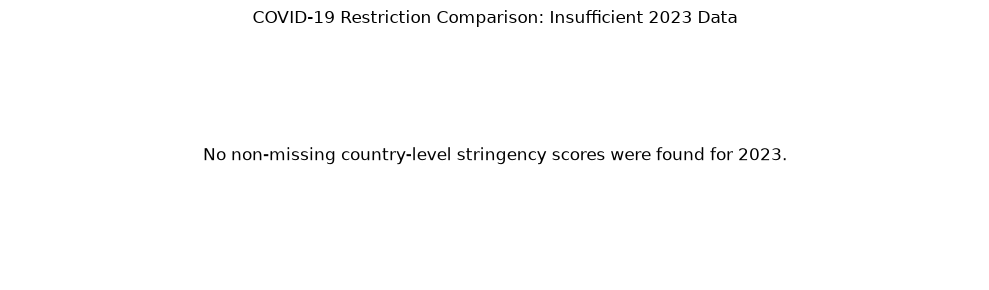

In [44]:
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Load and prepare the data
# --------------------------------------------------

FILE = "owid-covid-data.csv"

df = pd.read_csv(FILE, parse_dates=["date"])

# Ensure the policy measure is numeric.
df["stringency_index"] = pd.to_numeric(
    df["stringency_index"], errors="coerce"
)

# Select the requested period: all of 2023.
year_data = df.loc[
    (df["date"] >= "2023-01-01")
    & (df["date"] < "2024-01-01")
].copy()

# Keep country/territory locations rather than aggregate rows.
# In this dataset, aggregate locations generally have no continent.
country_data = year_data.loc[
    year_data["continent"].notna()
    & year_data["iso_code"].notna()
].copy()

# The dataset should have one row per location per date.
# Remove duplicate country-date records to avoid double-counting.
country_data = country_data.drop_duplicates(
    subset=["iso_code", "date"]
)

# --------------------------------------------------
# 2. Calculate the annual average and data coverage
# --------------------------------------------------

DAYS_IN_2023 = 365
MIN_DAYS_REQUIRED = 330  # Approximately 90% coverage

country_summary = (
    country_data
    .groupby(["iso_code", "location"], as_index=False)
    .agg(
        mean_stringency=("stringency_index", "mean"),
        days_with_score=("stringency_index", "count")
    )
)

# Calculate the proportion of the year with an observed score.
country_summary["coverage_pct"] = (
    country_summary["days_with_score"]
    / DAYS_IN_2023
    * 100
)

# Only include countries with sufficient data for the main chart.
comparable = country_summary.loc[
    country_summary["days_with_score"] >= MIN_DAYS_REQUIRED
].copy()

print("Country/territory locations with 2023 records:",
      country_data["iso_code"].nunique())

print("Locations meeting the coverage requirement:",
      len(comparable))

# --------------------------------------------------
# 3. Plot the comparison, if the data supports it
# --------------------------------------------------

if not comparable.empty:

    # Sort from lowest average strictness to highest.
    comparable = comparable.sort_values(
        "mean_stringency", ascending=True
    )

    # Adjust the figure height to fit the country labels.
    fig_height = max(6, 0.28 * len(comparable))

    fig, ax = plt.subplots(figsize=(11, fig_height))

    ax.barh(
        comparable["location"],
        comparable["mean_stringency"]
    )

    ax.set_xlim(0, 100)
    ax.set_xlabel("Average daily stringency index (0–100)")
    ax.set_ylabel("Country or territory")
    ax.set_title(
        "Average COVID-19 Policy Stringency by Country, 2023\n"
        "(Only locations with at least 330 observed daily scores)"
    )

    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.show()

else:
    print(
        "\nNo country or territory has at least "
        f"{MIN_DAYS_REQUIRED} observed stringency scores in 2023."
    )
    print(
        "A reliable full-year comparison cannot be produced "
        "from the available observations."
    )

    # --------------------------------------------------
    # 4. Show a diagnostic instead of a misleading ranking
    # --------------------------------------------------

    available = country_summary.loc[
        country_summary["days_with_score"] > 0
    ].copy()

    if not available.empty:

        # Show up to 20 locations with the most observed days.
        available = available.sort_values(
            "days_with_score", ascending=True
        ).tail(20)

        fig_height = max(4, 0.35 * len(available))
        fig, ax = plt.subplots(figsize=(10, fig_height))

        ax.barh(
            available["location"],
            available["days_with_score"]
        )

        ax.set_xlim(0, DAYS_IN_2023)
        ax.set_xlabel("Days with a reported stringency score (out of 365)")
        ax.set_ylabel("Country or territory")
        ax.set_title(
            "Availability of COVID-19 Stringency Data in 2023\n"
            "(This chart shows data coverage, not restriction strictness)"
        )

        ax.grid(axis="x", alpha=0.3)
        ax.set_axisbelow(True)

    else:

        fig, ax = plt.subplots(figsize=(10, 3))

        ax.text(
            0.5,
            0.5,
            "No non-missing country-level stringency scores "
            "were found for 2023.",
            ha="center",
            va="center",
            wrap=True,
            transform=ax.transAxes,
            fontsize=12
        )

        ax.set_title(
            "COVID-19 Restriction Comparison: Insufficient 2023 Data"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()

**Assessment: Valid – choice stated.** Before writing code, ChatGPT stated that the stringency index from the Oxford COVID-19 Government Response Tracker ends on 31 December 2022 for almost all countries, and explicitly declined to substitute 2022 data without changing the question. Its code required at least 330 observed daily scores in 2023 before including a country; none of the 241 locations met this, and the code displayed a notice stating that no country-level stringency scores exist for 2023 instead of a chart. This is the correct answer to an unanswerable question. In the baseline, the same question produced an empty chart with no explanation. The response contains web-search citation markers, indicating that ChatGPT searched the web to establish the data's end date.

### T16 (state choices). Which countries had the highest excess mortality during the pandemic?

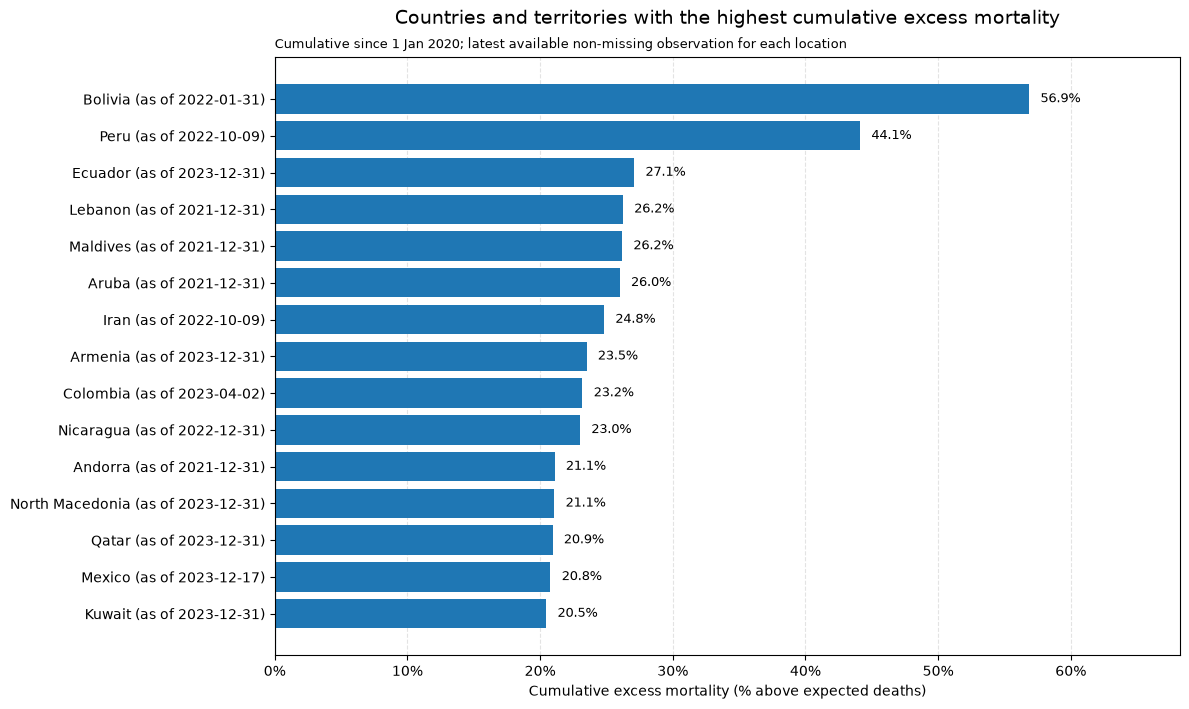

In [45]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# --------------------------------------------------
# 1. Load the dataset
# --------------------------------------------------
FILE = "owid-covid-data.csv"
METRIC = "excess_mortality_cumulative"
TOP_N = 15

df = pd.read_csv(FILE, low_memory=False)

# Check that the required columns are present.
required_columns = [
    "iso_code",
    "continent",
    "location",
    "date",
    METRIC,
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Parse dates and convert the chosen measure to numeric.
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df[METRIC] = pd.to_numeric(df[METRIC], errors="coerce")


# --------------------------------------------------
# 2. Keep country and territory rows, not aggregates
# --------------------------------------------------
# OWID aggregate codes generally do not have a standard
# three-letter ISO code or a continent value.
#
# This retains locations with a three-letter code and
# a non-missing continent. It can include territories
# and special jurisdictions, not only sovereign states.

is_country_or_territory = (
    df["continent"].notna()
    & df["iso_code"].astype("string").str.fullmatch(
        r"[A-Z]{3}", na=False
    )
)

country_data = df.loc[is_country_or_territory].copy()


# --------------------------------------------------
# 3. Remove rows without a usable measurement
# --------------------------------------------------
valid_data = country_data.dropna(
    subset=["date", METRIC]
).copy()

if valid_data.empty:
    raise ValueError(
        f"No valid observations found for {METRIC}."
    )


# --------------------------------------------------
# 4. Select each location's latest non-missing value
# --------------------------------------------------
# Sorting by date ensures that the final row for each
# ISO code contains its latest available measurement.

latest = (
    valid_data
    .sort_values(["iso_code", "date"])
    .groupby("iso_code", group_keys=False)
    .tail(1)
    .copy()
)


# --------------------------------------------------
# 5. Rank locations and select the top 15
# --------------------------------------------------
top = (
    latest
    .nlargest(TOP_N, METRIC)
    .sort_values(METRIC, ascending=True)
    .copy()
)

# Include the observation date to expose differences
# in reporting coverage between locations.
top["chart_label"] = (
    top["location"]
    + " (as of "
    + top["date"].dt.strftime("%Y-%m-%d")
    + ")"
)


# --------------------------------------------------
# 6. Create a horizontal bar chart
# --------------------------------------------------
fig, ax = plt.subplots(
    figsize=(12, max(6, 0.48 * len(top)))
)

bars = ax.barh(
    top["chart_label"],
    top[METRIC],
)

# A zero reference line distinguishes positive and
# negative cumulative excess mortality.
ax.axvline(0, linewidth=0.8)

ax.set_title(
    "Countries and territories with the highest "
    "cumulative excess mortality",
    fontsize=14,
    pad=24,
)

ax.set_xlabel(
    "Cumulative excess mortality (% above expected deaths)"
)

ax.set_ylabel("")

# The column stores percentage values as numbers such as
# 20 for 20%, rather than decimals such as 0.20.
ax.xaxis.set_major_formatter(
    PercentFormatter(xmax=100)
)

# Add a percentage label to the end of each bar.
largest_value = max(
    1,
    top[METRIC].abs().max()
)
label_offset = largest_value * 0.015

for bar, value in zip(bars, top[METRIC]):
    y = bar.get_y() + bar.get_height() / 2

    if value >= 0:
        x = value + label_offset
        alignment = "left"
    else:
        x = value - label_offset
        alignment = "right"

    ax.text(
        x,
        y,
        f"{value:.1f}%",
        va="center",
        ha=alignment,
        fontsize=9,
    )

ax.text(
    0,
    1.01,
    "Cumulative since 1 Jan 2020; latest available "
    "non-missing observation for each location",
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=9,
)

ax.grid(axis="x", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)
ax.margins(x=0.20)

plt.tight_layout()
plt.show()

**Assessment: Valid – choice stated.** ChatGPT chose cumulative excess mortality as a percentage of expected deaths, which allows comparison across countries of different sizes, and explained that rankings by absolute or per-million excess deaths would differ. It used each country's latest available value and named differing reporting end dates as the first limitation; the chart labels every country with its end date. Bolivia (56.9%, to January 2022) and Peru (44.1%, to October 2022) rank highest. Among the 125 countries with data, 73 end in December 2023, 12 in December 2022 and 15 in December 2021. Not stated: windows ending in 2021 cover only the most severe pandemic years, so these countries' percentages are likely higher than they would be over a full period. In the baseline, the same question produced a Flagged analytical error.

### T17 (state choices). Which countries were best at testing for COVID?


Top locations by reported cumulative testing rate:
            location total_tests_per_thousand       date     tests_units
              Cyprus                 32,925.8 2022-04-14 tests performed
             Austria                 21,272.1 2022-06-23 tests performed
United Arab Emirates                 17,994.7 2022-06-23 tests performed
           Gibraltar                 16,322.9 2022-04-01 tests performed
       Faroe Islands                 14,707.4 2022-02-26   people tested
             Denmark                 11,043.3 2022-06-22 tests performed
            Slovakia                  9,405.7 2022-06-22 tests performed
              Greece                  8,088.1 2022-06-22  samples tested
      United Kingdom                  7,480.1 2022-05-19 tests performed
             Bahrain                  6,812.9 2022-06-23   units unclear
          Luxembourg                  6,725.7 2022-06-21 tests performed
           Hong Kong                  6,595.0 2022-05-24 tests performed

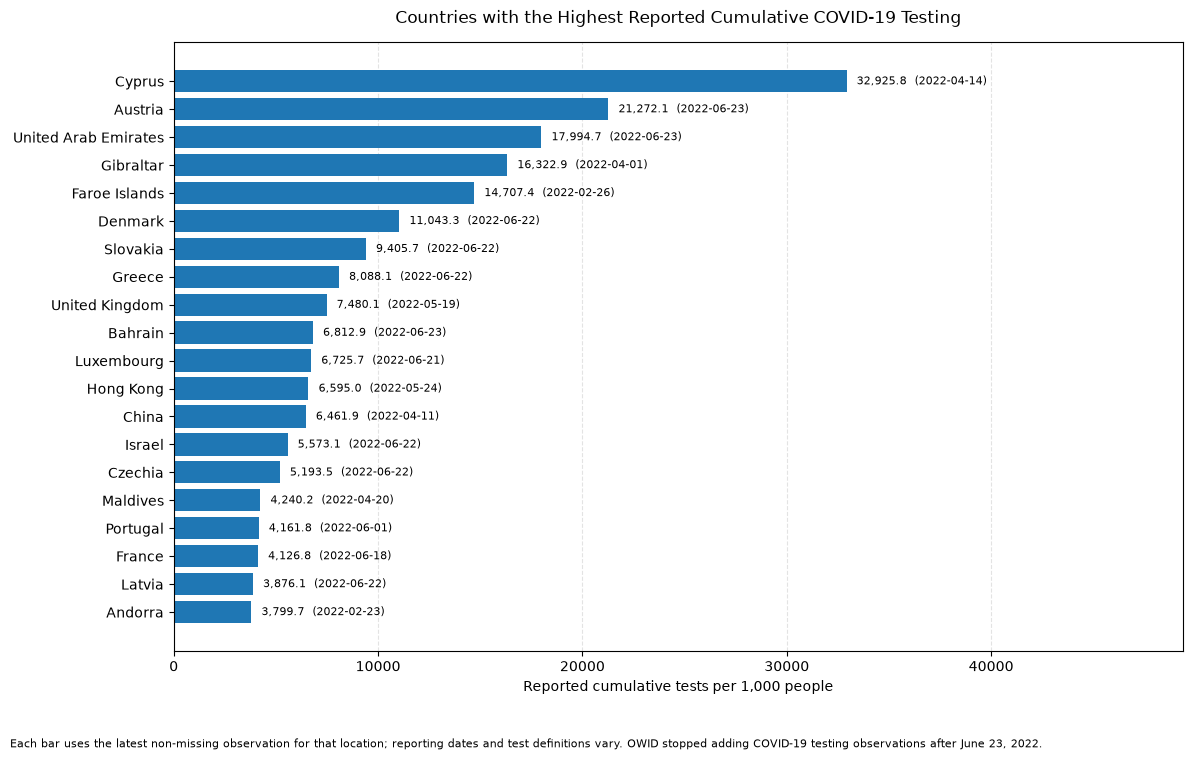

In [46]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the dataset
df = pd.read_csv("owid-covid-data.csv")

# 2. Prepare the date and testing-rate columns
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["total_tests_per_thousand"] = pd.to_numeric(
    df["total_tests_per_thousand"], errors="coerce"
)

# 3. Keep country-level locations and the fields needed for analysis.
# A non-missing continent generally excludes OWID global and regional aggregates.
country_data = df.loc[
    df["continent"].notna(),
    [
        "location",
        "continent",
        "date",
        "total_tests_per_thousand",
        "tests_units",
    ],
].copy()

# 4. Exclude observations with missing dates or testing rates.
# Negative cumulative rates are not meaningful for this comparison.
country_data = country_data.dropna(
    subset=["date", "total_tests_per_thousand"]
)
country_data = country_data[
    country_data["total_tests_per_thousand"] >= 0
]

if country_data.empty:
    raise ValueError(
        "No usable country-level observations were found for "
        "'total_tests_per_thousand'."
    )

# 5. Select each location's latest non-missing reported testing rate.
latest = (
    country_data
    .sort_values(["location", "date"])
    .drop_duplicates(subset="location", keep="last")
)

# 6. Rank locations and select the top 20.
TOP_N = 20

top = latest.nlargest(TOP_N, "total_tests_per_thousand").copy()

# Print the ranking, reporting date, and test unit for interpretation.
print("\nTop locations by reported cumulative testing rate:")
print(
    top[
        [
            "location",
            "total_tests_per_thousand",
            "date",
            "tests_units",
        ]
    ]
    .sort_values("total_tests_per_thousand", ascending=False)
    .to_string(
        index=False,
        formatters={
            "total_tests_per_thousand": lambda x: f"{x:,.1f}",
            "date": lambda x: x.strftime("%Y-%m-%d"),
        },
    )
)

# 7. Sort from lowest to highest so the highest bar appears at the top.
plot_data = top.sort_values("total_tests_per_thousand", ascending=True)

# 8. Draw a horizontal bar chart.
fig, ax = plt.subplots(
    figsize=(12, max(6, 0.38 * len(plot_data)))
)

bars = ax.barh(
    plot_data["location"],
    plot_data["total_tests_per_thousand"],
)

# Show both the testing rate and its latest observation date.
max_rate = plot_data["total_tests_per_thousand"].max()
x_padding = max(max_rate * 0.015, 0.1)

for bar, (_, row) in zip(bars, plot_data.iterrows()):
    rate = row["total_tests_per_thousand"]
    date_label = row["date"].strftime("%Y-%m-%d")

    ax.text(
        bar.get_width() + x_padding,
        bar.get_y() + bar.get_height() / 2,
        f"{rate:,.1f}  ({date_label})",
        va="center",
        fontsize=8,
    )

# 9. Add descriptive labels and a note about interpretation.
ax.set_title(
    "Countries with the Highest Reported Cumulative COVID-19 Testing",
    pad=14,
)
ax.set_xlabel("Reported cumulative tests per 1,000 people")
ax.set_ylabel("")

ax.grid(axis="x", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

# Leave room for the values and dates printed beside the bars.
ax.set_xlim(0, max_rate * 1.5 if max_rate > 0 else 1)

fig.text(
    0.01,
    0.01,
    "Each bar uses the latest non-missing observation for that location; "
    "reporting dates and test definitions vary. "
    "OWID stopped adding COVID-19 testing observations after June 23, 2022.",
    fontsize=8,
    wrap=True,
)

plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

**Assessment: Valid – choice stated.** ChatGPT interpreted "best at testing" as the highest cumulative tests per 1,000 people, explicitly rejecting raw totals because they favour larger countries. It named differing test definitions (tests performed, people tested, samples tested) as its first limitation, and the code prints each country's test unit alongside the ranking. It also stated that OWID testing data ended in June 2022, labelled each bar with its date, and cautioned that a high testing rate is not proof of better testing policy. Cyprus ranks highest (32,926 per 1,000 people). The chart's footnote states that test definitions vary, but which definition each country uses appears only in the printed table, not on the chart. In the baseline, the same question produced a Flagged analytical error.

### T18 (state choices). Do countries with higher diabetes rates have more COVID deaths?

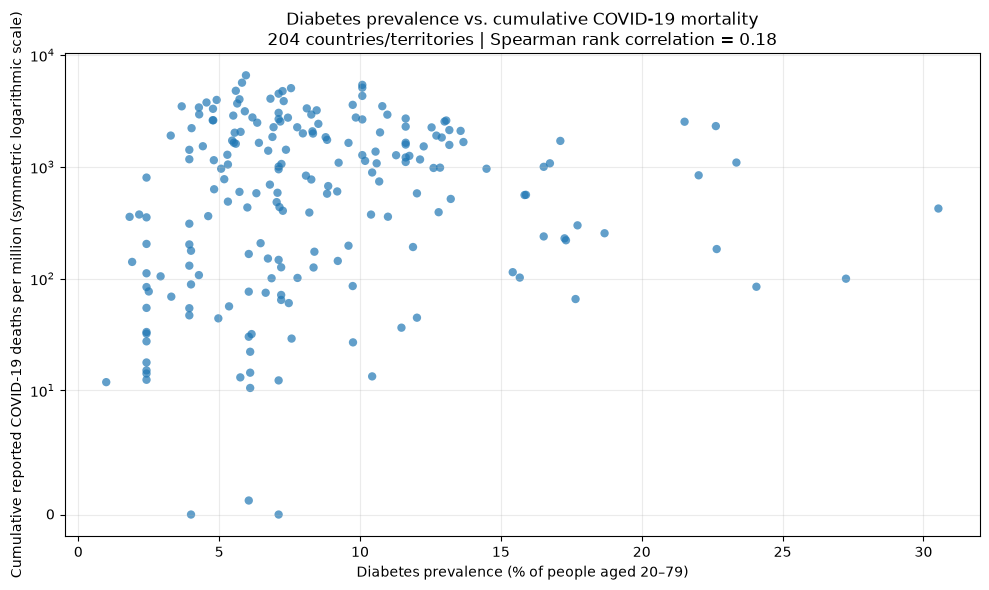

Countries/territories plotted: 204
Spearman rank correlation: 0.18
Selected death-observation dates range from 2024-08-04 to 2024-08-04.


In [47]:
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Load the dataset
# --------------------------------------------------
FILE = "owid-covid-data.csv"

df = pd.read_csv(FILE, low_memory=False)

required_columns = [
    "iso_code",
    "continent",
    "location",
    "date",
    "diabetes_prevalence",
    "total_deaths_per_million",
]

missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Convert dates and the two analytical variables to usable types.
df["date"] = pd.to_datetime(df["date"], errors="coerce")

for col in ["diabetes_prevalence", "total_deaths_per_million"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")


# --------------------------------------------------
# 2. Keep country- and territory-level observations
# --------------------------------------------------
# Aggregate rows, such as the world and continents, generally
# have no continent value of their own.
country_rows = df.loc[
    df["continent"].notna()
    & df["iso_code"].notna()
    & df["date"].notna()
].copy()


# --------------------------------------------------
# 3. Select the latest valid diabetes estimate
#    for each country/territory
# --------------------------------------------------
valid_diabetes = country_rows.loc[
    country_rows["diabetes_prevalence"].between(0, 100)
].copy()

latest_diabetes = (
    valid_diabetes
    .sort_values("date")
    .groupby("iso_code", as_index=False)
    .tail(1)[
        ["iso_code", "diabetes_prevalence"]
    ]
)


# --------------------------------------------------
# 4. Select the latest valid cumulative death rate
#    for each country/territory
# --------------------------------------------------
valid_deaths = country_rows.loc[
    country_rows["total_deaths_per_million"].ge(0)
].copy()

latest_deaths = (
    valid_deaths
    .sort_values("date")
    .groupby("iso_code", as_index=False)
    .tail(1)[
        [
            "iso_code",
            "location",
            "date",
            "total_deaths_per_million",
        ]
    ]
)


# --------------------------------------------------
# 5. Combine both measures into one row per country
# --------------------------------------------------
plot_df = latest_deaths.merge(
    latest_diabetes,
    on="iso_code",
    how="inner",
)

plot_df = plot_df.dropna(
    subset=[
        "diabetes_prevalence",
        "total_deaths_per_million",
    ]
)

if plot_df.empty:
    raise ValueError(
        "No country/territory observations have valid values "
        "for both diabetes prevalence and deaths per million."
    )


# --------------------------------------------------
# 6. Calculate the Spearman rank correlation
# --------------------------------------------------
rho = plot_df["diabetes_prevalence"].corr(
    plot_df["total_deaths_per_million"],
    method="spearman",
)

rho_text = f"{rho:.2f}" if pd.notna(rho) else "not defined"


# --------------------------------------------------
# 7. Create the scatter plot
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    plot_df["diabetes_prevalence"],
    plot_df["total_deaths_per_million"],
    alpha=0.7,
    edgecolors="none",
)

# Keep zero-death observations visible while reducing the
# visual dominance of countries with exceptionally high rates.
ax.set_yscale("symlog", linthresh=10)

ax.set_xlabel(
    "Diabetes prevalence (% of people aged 20–79)"
)

ax.set_ylabel(
    "Cumulative reported COVID-19 deaths per million "
    "(symmetric logarithmic scale)"
)

ax.set_title(
    "Diabetes prevalence vs. cumulative COVID-19 mortality\n"
    f"{len(plot_df)} countries/territories | "
    f"Spearman rank correlation = {rho_text}"
)

ax.grid(True, which="both", alpha=0.25)

fig.tight_layout()
plt.show()


# --------------------------------------------------
# 8. Print information needed to interpret the chart
# --------------------------------------------------
print(f"Countries/territories plotted: {len(plot_df)}")
print(f"Spearman rank correlation: {rho_text}")

print(
    "Selected death-observation dates range from "
    f"{plot_df['date'].min().date()} to "
    f"{plot_df['date'].max().date()}."
)

**Assessment: Valid – choice stated.** ChatGPT plotted diabetes prevalence against cumulative deaths per million rather than total deaths, explaining that totals reflect population size. Among the limitations it listed, it named age structure as a factor that could influence the relationship, stated that correlation does not imply causation, and noted that country-level data cannot show whether individuals with diabetes were more likely to die (the ecological fallacy). The chart covers 204 countries and territories, all with death data to 4 August 2024, and reports a Spearman rank correlation of 0.18, a weak positive association. In the baseline, the same question was also answered validly; this version adds the age and ecological caveats and a summary statistic.

### T19 (state choices). Did richer countries handle COVID better? Plot GDP per capita against COVID deaths.

Latest date in CSV: 2024-08-14
Number of locations plotted: 193
Locations whose selected death-rate observation is more than 90 days before the cutoff: 0
Spearman rank correlation: 0.647


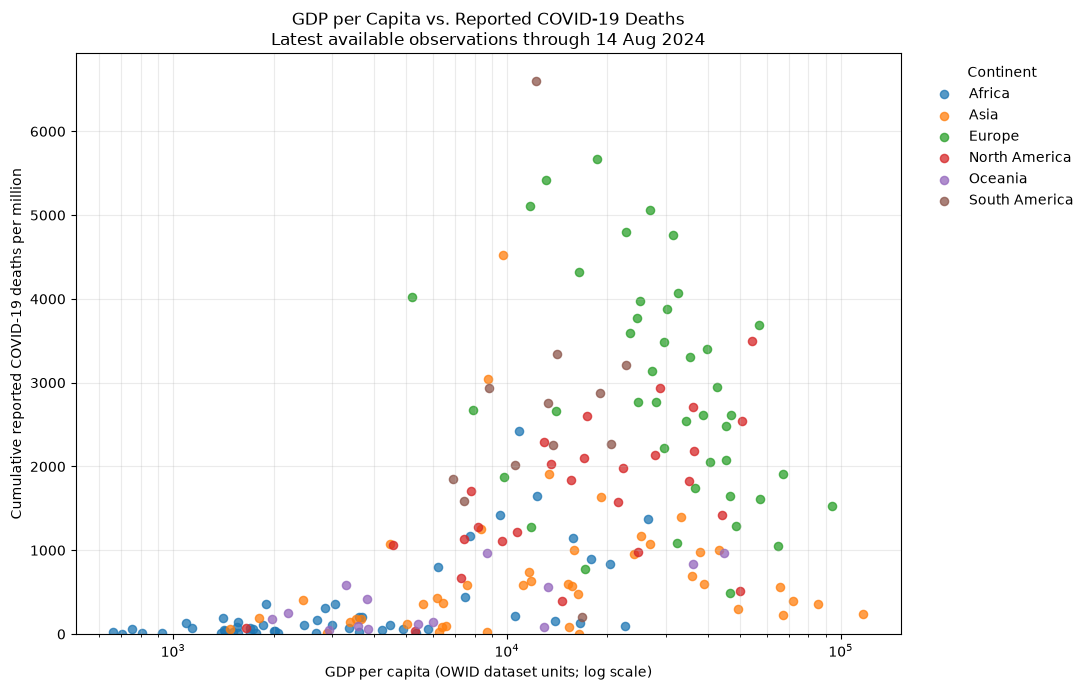

In [48]:

import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Load and clean the data
# --------------------------------------------------

FILE = "owid-covid-data.csv"

df = pd.read_csv(FILE, low_memory=False)

df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Ensure the relevant columns are numeric.
for col in ["gdp_per_capita", "total_deaths_per_million"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Latest date represented anywhere in the file.
cutoff_date = df["date"].max()

if pd.isna(cutoff_date):
    raise ValueError("No valid dates were found in the CSV file.")

# Ignore rows with invalid dates or no country/territory
# classification. This removes the usual OWID aggregates.
country_rows = df.loc[
    df["date"].notna()
    & df["iso_code"].notna()
    & df["continent"].notna()
    & (df["date"] <= cutoff_date)
].copy()

# --------------------------------------------------
# 2. Get the latest available death rate per location
# --------------------------------------------------

deaths = (
    country_rows
    .dropna(subset=["total_deaths_per_million"])
    .sort_values(["iso_code", "date"])
    .drop_duplicates(subset="iso_code", keep="last")
    [
        [
            "iso_code",
            "location",
            "continent",
            "date",
            "total_deaths_per_million",
        ]
    ]
    .rename(columns={"date": "deaths_observation_date"})
)

# --------------------------------------------------
# 3. Get the latest available GDP per capita
# --------------------------------------------------

gdp = (
    country_rows
    .dropna(subset=["gdp_per_capita"])
    .sort_values(["iso_code", "date"])
    .drop_duplicates(subset="iso_code", keep="last")
    [["iso_code", "gdp_per_capita"]]
)

# Join GDP and deaths so each location appears only once.
plot_df = deaths.merge(gdp, on="iso_code", how="inner")

# Keep valid values suitable for the chosen axes.
plot_df = plot_df.loc[
    (plot_df["gdp_per_capita"] > 0)
    & (plot_df["total_deaths_per_million"] >= 0)
].copy()

if plot_df.empty:
    raise ValueError(
        "No locations have valid GDP and death-rate data."
    )

# --------------------------------------------------
# 4. Check how old the selected death observations are
# --------------------------------------------------

plot_df["days_before_cutoff"] = (
    cutoff_date - plot_df["deaths_observation_date"]
).dt.days

print(f"Latest date in CSV: {cutoff_date:%Y-%m-%d}")
print(f"Number of locations plotted: {len(plot_df)}")

stale_count = (
    plot_df["days_before_cutoff"] > 90
).sum()

print(
    "Locations whose selected death-rate observation is "
    f"more than 90 days before the cutoff: {stale_count}"
)

# Spearman correlation measures the direction and strength
# of the rank-based association between GDP and death rates.
rho = plot_df["gdp_per_capita"].corr(
    plot_df["total_deaths_per_million"],
    method="spearman",
)

print(f"Spearman rank correlation: {rho:.3f}")

# --------------------------------------------------
# 5. Plot GDP per capita against reported COVID deaths
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 7))

for continent, group in plot_df.groupby("continent", sort=True):
    ax.scatter(
        group["gdp_per_capita"],
        group["total_deaths_per_million"],
        s=35,
        alpha=0.75,
        label=continent,
    )

# GDP varies across a wide range, so use a log scale.
ax.set_xscale("log")

ax.set_xlabel("GDP per capita (OWID dataset units; log scale)")
ax.set_ylabel("Cumulative reported COVID-19 deaths per million")

ax.set_title(
    "GDP per Capita vs. Reported COVID-19 Deaths\n"
    f"Latest available observations through {cutoff_date:%d %b %Y}"
)

ax.set_ylim(bottom=0)
ax.grid(True, which="both", alpha=0.25)

ax.legend(
    title="Continent",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
)

fig.tight_layout()
plt.show()


**Assessment: Valid – choice stated.** ChatGPT plotted GDP per capita (log scale) against cumulative deaths per million for 193 locations, rejecting total GDP and total deaths because both reflect population size. The resulting Spearman correlation is 0.647: richer countries reported more deaths per person. Read naively, this suggests richer countries handled COVID worse, but ChatGPT's stated limitations named both main explanations in advance: older populations have higher death rates, and countries differ in the completeness of death recording. It stated explicitly that the chart cannot establish whether richer countries handled the pandemic better or worse. Because ChatGPT did not see the output, these caveats were not applied to the specific positive correlation. In the baseline, the same question was also answered validly.

### T20 (state choices). Did low-income countries have a lower COVID death rate than high-income countries?

Comparison cutoff: 2023-12-31

Median cumulative reported COVID-19 deaths
per 100,000 people:
              median_rate  countries
income_group                        
Low income           5.54         25
High income        183.61         83


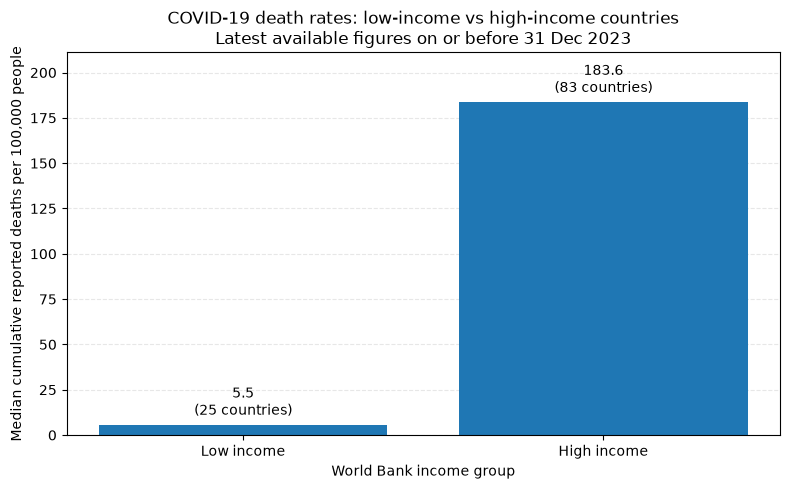


The median country-level reported COVID-19 death rate was LOWER in low-income countries.
Interpret this as a comparison of reported deaths, not necessarily the true mortality burden.


In [49]:

import json
from urllib.request import urlopen

import pandas as pd
import matplotlib.pyplot as plt


# --------------------------------------------------
# 1. Load the COVID-19 dataset
# --------------------------------------------------
df = pd.read_csv(
    "owid-covid-data.csv",
    low_memory=False,
    parse_dates=["date"]
)

# Ensure numeric columns are numeric
for col in ["total_deaths", "population"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["date", "iso_code"]).copy()

if df.empty:
    raise ValueError("The dataset contains no usable dated records.")


# --------------------------------------------------
# 2. Set a common cutoff date
# --------------------------------------------------
requested_cutoff = pd.Timestamp("2023-12-31")

dates_before_cutoff = df.loc[
    df["date"] <= requested_cutoff, "date"
]

if dates_before_cutoff.empty:
    # Fallback if the file contains only dates after
    # the requested cutoff.
    cutoff = df["date"].max()
    print(
        "No records exist on or before December 31, 2023. "
        f"Using the latest dataset date: {cutoff.date()}."
    )
else:
    cutoff = dates_before_cutoff.max()

print(f"Comparison cutoff: {cutoff.date()}")


# --------------------------------------------------
# 3. Retrieve World Bank income classifications
# --------------------------------------------------
url = (
    "https://api.worldbank.org/v2/country"
    "?format=json&per_page=400"
)

with urlopen(url, timeout=30) as response:
    wb_data = json.load(response)

if len(wb_data) < 2 or wb_data[1] is None:
    raise RuntimeError("Could not retrieve World Bank country data.")

income_rows = []

for country in wb_data[1]:
    iso3 = country.get("id")
    income = (country.get("incomeLevel") or {}).get("id")
    region = (country.get("region") or {}).get("id")

    # Retain actual countries/economies in the two groups.
    # Exclude regional and other aggregate entries.
    if iso3 and region != "NA" and income in ["LIC", "HIC"]:
        income_rows.append({
            "iso_code": iso3,
            "income_group": {
                "LIC": "Low income",
                "HIC": "High income"
            }[income]
        })

income_df = pd.DataFrame(income_rows).drop_duplicates("iso_code")

if income_df.empty:
    raise RuntimeError("No eligible World Bank income classifications found.")


# --------------------------------------------------
# 4. Get each country's latest reported deaths by cutoff
# --------------------------------------------------
eligible = df.loc[
    (df["date"] <= cutoff) & df["total_deaths"].notna()
].copy()

# Exclude non-country aggregates by matching to the
# World Bank's ISO-3 country codes in the later merge.
latest_deaths = (
    eligible
    .sort_values("date")
    .drop_duplicates("iso_code", keep="last")
    [["iso_code", "location", "date", "total_deaths"]]
)

# Get the latest available population on or before cutoff.
pop_rows = df.loc[
    (df["date"] <= cutoff) & df["population"].notna()
].copy()

latest_population = (
    pop_rows
    .sort_values("date")
    .drop_duplicates("iso_code", keep="last")
    [["iso_code", "population"]]
)

# Join deaths, population, and income group.
country_data = (
    latest_deaths
    .merge(latest_population, on="iso_code", how="inner")
    .merge(income_df, on="iso_code", how="inner")
)

# Missing values are not zero. Require a valid population
# and a non-negative cumulative death count.
country_data = country_data.loc[
    (country_data["population"] > 0)
    & (country_data["total_deaths"] >= 0)
].copy()

# Cumulative reported deaths per 100,000 people.
country_data["deaths_per_100k"] = (
    country_data["total_deaths"]
    / country_data["population"]
    * 100_000
)

if country_data.empty:
    raise ValueError(
        "No countries have usable death counts, population, "
        "and World Bank income classifications at the cutoff."
    )


# --------------------------------------------------
# 5. Compare median country-level death rates
# --------------------------------------------------
group_order = ["Low income", "High income"]

summary = (
    country_data
    .groupby("income_group")["deaths_per_100k"]
    .agg(median_rate="median", countries="count")
    .reindex(group_order)
)

if summary["median_rate"].isna().any():
    raise ValueError(
        "At least one income group has no eligible countries. "
        "Check the file and the income-group matches."
    )

print("\nMedian cumulative reported COVID-19 deaths")
print("per 100,000 people:")
print(summary.round(2).to_string())


# --------------------------------------------------
# 6. Plot the comparison
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    summary.index,
    summary["median_rate"]
)

ax.set_title(
    "COVID-19 death rates: low-income vs high-income countries\n"
    f"Latest available figures on or before {cutoff:%d %b %Y}"
)
ax.set_ylabel(
    "Median cumulative reported deaths per 100,000 people"
)
ax.set_xlabel("World Bank income group")

# Label each bar with its rate and number of countries.
for bar, group in zip(bars, group_order):
    rate = summary.loc[group, "median_rate"]
    n = int(summary.loc[group, "countries"])

    ax.annotate(
        f"{rate:,.1f}\n({n} countries)",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom"
    )

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.margins(y=0.15)

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 7. Print the answer supported by this chart
# --------------------------------------------------
low_rate = summary.loc["Low income", "median_rate"]
high_rate = summary.loc["High income", "median_rate"]

if low_rate < high_rate:
    print(
        "\nThe median country-level reported COVID-19 death "
        "rate was LOWER in low-income countries."
    )
elif low_rate > high_rate:
    print(
        "\nThe median country-level reported COVID-19 death "
        "rate was HIGHER in low-income countries."
    )
else:
    print(
        "\nThe median country-level reported COVID-19 death "
        "rates were equal in the two income groups."
    )

print(
    "Interpret this as a comparison of reported deaths, "
    "not necessarily the true mortality burden."
)


**Assessment: Valid – choice stated.** ChatGPT compared World Bank low-income and high-income countries using the median country-level rate of cumulative reported deaths per 100,000 people, with a common cutoff of 31 December 2023. Its first stated limitation addressed the central problem: under-reporting may be particularly serious in low-income countries, which could make their reported death rates look artificially low. It also disclosed that the median gives each country equal weight, and that the income classifications are current rather than those in force during the pandemic. The median reported rate was 5.5 per 100,000 in low-income countries (25 countries) against 183.6 in high-income countries (83 countries), a roughly 33-fold gap, and the code concludes by printing that this is a comparison of reported deaths, not necessarily the true mortality burden. This is a judgement call: the chart itself carries no caveat, its title omits the word "reported", and the response does not state that a gap of this size is implausible. Unlike other responses, the code retrieves income groups from the World Bank API at run time rather than using the income-group rows already in the OWID file, so the result depends on an external website. In the baseline, the same question produced a Flagged analytical error.

### T21 (state choices). Which country had the deadliest COVID outbreak?

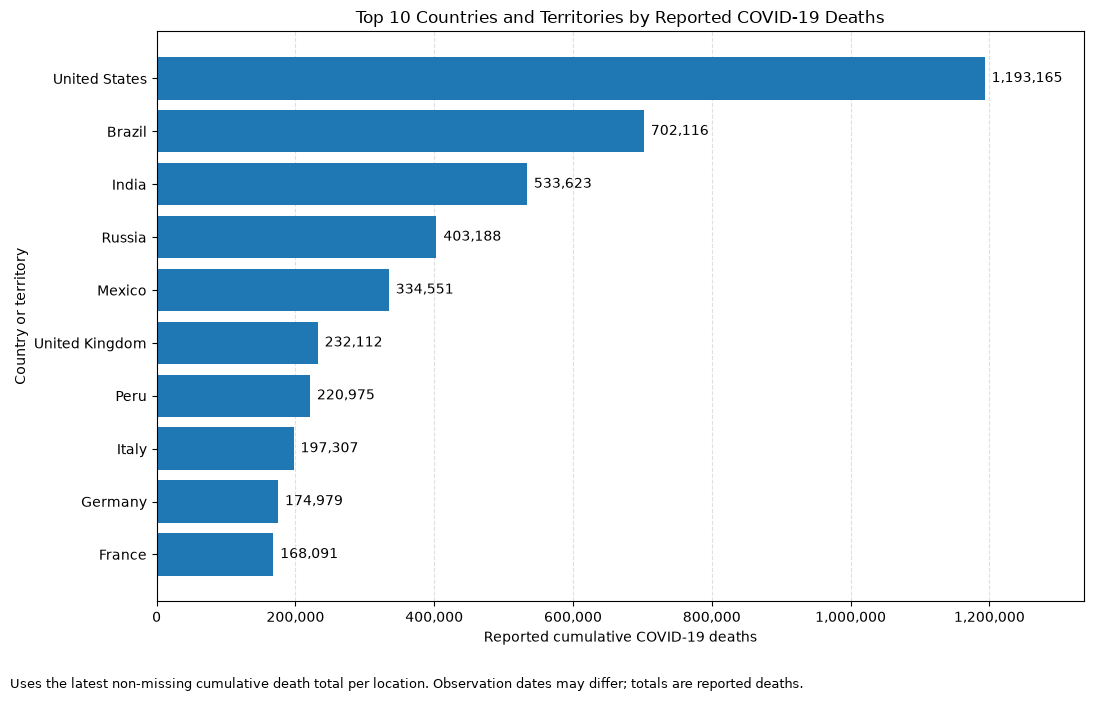

Highest reported cumulative death toll: United States
Reported deaths: 1,193,165
Last reported observation: 2024-08-04


In [50]:

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# 1. Load the dataset
df = pd.read_csv("owid-covid-data.csv")

# 2. Prepare the fields used in the analysis
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["total_deaths"] = pd.to_numeric(
    df["total_deaths"], errors="coerce"
)

# 3. Keep country/territory rows with standard three-letter ISO codes.
# This excludes aggregate rows such as World and continents.
iso3_mask = (
    df["iso_code"]
    .astype("string")
    .str.upper()
    .str.fullmatch(r"[A-Z]{3}", na=False)
)

locations = df.loc[
    iso3_mask,
    ["iso_code", "location", "date", "total_deaths"]
].copy()

# 4. Keep observations with a usable date and cumulative death total
locations = locations.dropna(
    subset=["date", "total_deaths"]
)

if locations.empty:
    raise ValueError(
        "No country/territory rows with valid dates and death totals "
        "were found. Check the CSV file and its columns."
    )

# 5. For each ISO code, take the latest non-missing cumulative death total.
# Do not sum total_deaths across dates: it is already cumulative.
latest = (
    locations
    .sort_values(["iso_code", "date"])
    .groupby("iso_code", sort=False)
    .tail(1)
)

# 6. Select the 10 locations with the highest reported death toll
top10 = (
    latest
    .nlargest(10, "total_deaths")
    .sort_values("total_deaths")
)

# 7. Plot a horizontal bar chart
fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    top10["location"],
    top10["total_deaths"]
)

# Add formatted death totals at the ends of the bars
for bar in bars:
    deaths = bar.get_width()
    ax.annotate(
        f"{deaths:,.0f}",
        xy=(deaths, bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center"
    )

ax.set_xlabel("Reported cumulative COVID-19 deaths")
ax.set_ylabel("Country or territory")
ax.set_title(
    "Top 10 Countries and Territories by Reported COVID-19 Deaths"
)

# Format the horizontal axis with thousands separators
ax.xaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

# Leave room for the death-total labels
max_deaths = top10["total_deaths"].max()
ax.set_xlim(0, max_deaths * 1.12 if max_deaths > 0 else 1)

ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

fig.text(
    0.01,
    0.01,
    "Uses the latest non-missing cumulative death total per location. "
    "Observation dates may differ; totals are reported deaths.",
    ha="left",
    fontsize=9
)

fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

# 8. Print the location with the highest reported death toll
winner = latest.loc[latest["total_deaths"].idxmax()]

print(
    f"Highest reported cumulative death toll: {winner['location']}\n"
    f"Reported deaths: {winner['total_deaths']:,.0f}\n"
    f"Last reported observation: {winner['date']:%Y-%m-%d}"
)


**Assessment: Flagged analytical error.** ChatGPT interpreted "deadliest outbreak" as the highest absolute number of reported deaths and plotted the top 10 by total_deaths, led by the United States (1,193,165), Brazil and India. This ranking largely reflects population size; by deaths per million, Peru ranks first, while here it appears seventh. The response named the problem explicitly: it listed population size as the first limitation, stated that total_deaths_per_million would be more suitable for comparing the death burden relative to population, and concluded that the chart does not necessarily show the worst outbreak per capita. The method itself was sound (the latest cumulative value per location, aggregates excluded). As with T01, stating choices made the definitional decision visible but did not change it. In the baseline, the same question also produced a Flagged analytical error.

### T22 (state choices). Which countries saw COVID cases rise fastest in March 2020?

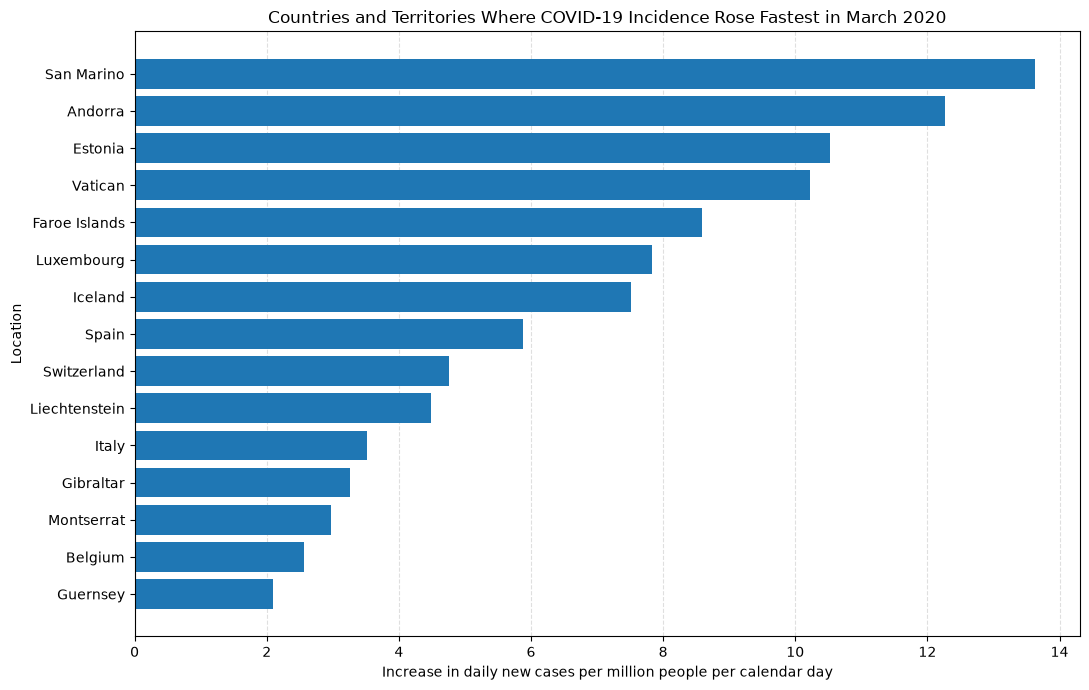


Top locations by the rate of increase in daily COVID-19 cases per million during March 2020:

     location   slope  valid_days
   San Marino 13.6287          31
      Andorra 12.2602          31
      Estonia 10.5333          31
      Vatican 10.2182          31
Faroe Islands  8.5958          31
   Luxembourg  7.8255          31
      Iceland  7.5139          31
        Spain  5.8824          31
  Switzerland  4.7544          31
Liechtenstein  4.4899          31
        Italy  3.5128          31
    Gibraltar  3.2575          31
   Montserrat  2.9729          31
      Belgium  2.5582          31
     Guernsey  2.0936          31


In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Load and prepare the data
# --------------------------------------------------

file_path = "owid-covid-data.csv"

df = pd.read_csv(file_path)

# Convert dates and case-rate values to usable types.
df["date"] = pd.to_datetime(df["date"], errors="coerce")

metric = "new_cases_smoothed_per_million"
df[metric] = pd.to_numeric(df[metric], errors="coerce")

# Define the analysis period.
start_date = pd.Timestamp("2020-03-01")
end_date = pd.Timestamp("2020-03-31")

# Keep March 2020 and exclude aggregate rows that have no
# continent assigned.
march = df.loc[
    df["date"].between(start_date, end_date)
    & df["continent"].notna(),
    ["location", "date", metric]
].copy()

# Missing case-rate values are not treated as zero.
march = march.dropna(subset=["location", "date", metric])

# Express dates as days since the beginning of March.
# This provides the x-values for estimating each trend.
march["day"] = (march["date"] - start_date).dt.days


# --------------------------------------------------
# 2. Estimate how quickly incidence increased
# --------------------------------------------------

MIN_VALID_DAYS = 20
MIN_DATE_SPAN = 25  # At least 26 calendar days from first to last observation

results = []

for location, group in march.groupby("location"):

    group = group.sort_values("day")

    # Require adequate coverage across most of March.
    if group["day"].nunique() < MIN_VALID_DAYS:
        continue

    date_span = group["day"].max() - group["day"].min()

    if date_span < MIN_DATE_SPAN:
        continue

    # Fit a linear trend:
    # daily cases per million = intercept + slope * day
    x = group["day"].to_numpy(dtype=float)
    y = group[metric].to_numpy(dtype=float)

    slope, intercept = np.polyfit(x, y, 1)

    results.append({
        "location": location,
        "slope": slope,
        "valid_days": len(group)
    })

# Put the country-level estimates into a DataFrame.
ranking = pd.DataFrame(results)

if ranking.empty:
    raise ValueError(
        "No locations met the minimum data requirements. "
        "Check the date range, column names, and missing values."
    )

# Retain only locations with an increasing trend.
ranking = ranking.loc[ranking["slope"] > 0]

# Select the 15 largest positive slopes.
top_15 = (
    ranking.nlargest(15, "slope")
    .sort_values("slope")
)

if top_15.empty:
    raise ValueError(
        "No eligible locations had a positive estimated trend."
    )


# --------------------------------------------------
# 3. Plot the results
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 7))

ax.barh(
    top_15["location"],
    top_15["slope"]
)

ax.set_title(
    "Countries and Territories Where COVID-19 Incidence "
    "Rose Fastest in March 2020"
)

ax.set_xlabel(
    "Increase in daily new cases per million people "
    "per calendar day"
)

ax.set_ylabel("Location")

ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 4. Print the numerical ranking
# --------------------------------------------------

top_15 = top_15.sort_values("slope", ascending=False)

print(
    "\nTop locations by the rate of increase in daily "
    "COVID-19 cases per million during March 2020:\n"
)

print(
    top_15[["location", "slope", "valid_days"]]
    .to_string(
        index=False,
        formatters={"slope": "{:.4f}".format}
    )
)

**Assessment: Valid – choice stated.** ChatGPT defined "rise fastest" as the slope of a linear trend fitted to daily new cases per million (smoothed) over 1–31 March 2020, explaining that per-million rates prevent populous countries from dominating and that per-capita and absolute rankings tell different stories. It required at least 20 days of data and warned that reported cases depend on testing. Of 234 eligible locations, the steepest rises were in San Marino, Andorra, Estonia, the Vatican and the Faroe Islands; Spain ranks eighth and Italy eleventh. Not stated: per-million rates are unstable for very small populations (the Vatican has about 800 people, so one case equals over 1,200 per million), and four of the top five have fewer than 100,000 people. In the baseline, the same question produced a Flagged analytical error.

### T23 (state choices). Compare hospital bed capacity with COVID deaths across European countries.

Reference date: 2024-08-14
Countries/locations plotted: 43
Dates of selected death observations: 2024-08-04 to 2024-08-04

Locations excluded because a required measure was missing or the death observation was too old:
Andorra, England, Faroe Islands, Gibraltar, Guernsey, Isle of Man, Jersey, Kosovo, Northern Ireland, Scotland, Vatican, Wales


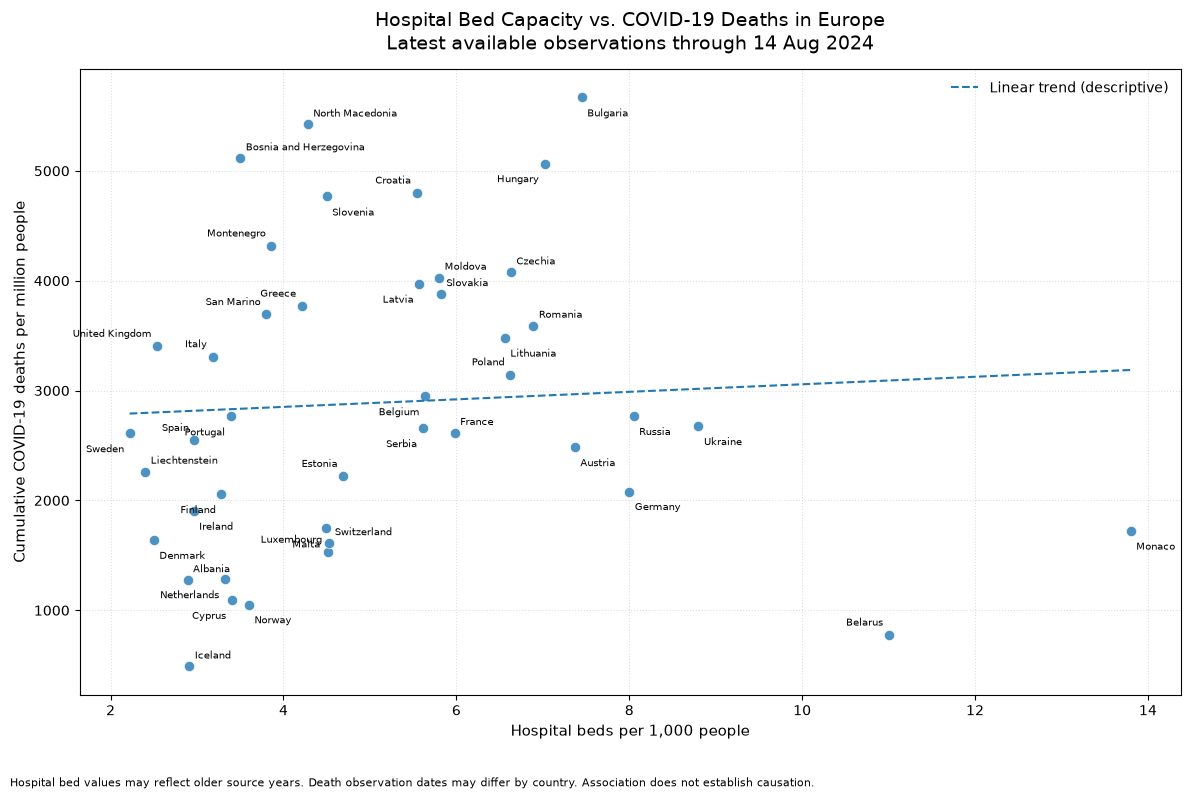


Chart saved to: europe_hospital_beds_vs_covid_deaths.png


In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

CSV_PATH = "owid-covid-data.csv"

# None uses the latest date in the European rows of the CSV.
# For a fixed historical snapshot, enter a date such as
# "2022-12-31", provided that date falls within the data.
REFERENCE_DATE = None

# Exclude a country if its latest non-missing death
# observation is more than this many days before the
# reference date.
MAX_DEATH_DATA_AGE_DAYS = 90

OUTPUT_FILE = "europe_hospital_beds_vs_covid_deaths.png"


# --------------------------------------------------
# 2. Load and validate the data
# --------------------------------------------------

df = pd.read_csv(CSV_PATH)

required_columns = {
    "continent",
    "location",
    "date",
    "hospital_beds_per_thousand",
    "total_deaths_per_million",
}

missing_columns = required_columns.difference(df.columns)

if missing_columns:
    raise ValueError(
        f"The CSV is missing these required columns: "
        f"{sorted(missing_columns)}"
    )

df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Ensure the two analysis variables are numeric.
for column in [
    "hospital_beds_per_thousand",
    "total_deaths_per_million",
]:
    df[column] = pd.to_numeric(df[column], errors="coerce")


# --------------------------------------------------
# 3. Select European locations and the reference date
# --------------------------------------------------

europe = df.loc[
    df["continent"].eq("Europe") & df["date"].notna()
].copy()

if europe.empty:
    raise ValueError(
        "No rows were found with continent == 'Europe'."
    )

earliest_date = europe["date"].min()
latest_date = europe["date"].max()

if REFERENCE_DATE is None:
    reference_date = latest_date
else:
    reference_date = pd.Timestamp(REFERENCE_DATE)

    if not earliest_date <= reference_date <= latest_date:
        raise ValueError(
            f"REFERENCE_DATE must be between "
            f"{earliest_date.date()} and {latest_date.date()}."
        )

# Do not use observations recorded after the reference date.
europe = europe.loc[
    europe["date"] <= reference_date
].copy()


# --------------------------------------------------
# 4. Extract the latest available hospital bed value
#    for each location
# --------------------------------------------------

bed_rows = europe.loc[
    europe["hospital_beds_per_thousand"].notna(),
    [
        "location",
        "date",
        "hospital_beds_per_thousand",
    ],
].copy()

beds = (
    bed_rows
    .sort_values(["location", "date"])
    .drop_duplicates(subset="location", keep="last")
    [["location", "hospital_beds_per_thousand"]]
)


# --------------------------------------------------
# 5. Extract the latest available death rate for each
#    location, then enforce the 90-day freshness limit
# --------------------------------------------------

death_rows = europe.loc[
    europe["total_deaths_per_million"].notna(),
    [
        "location",
        "date",
        "total_deaths_per_million",
    ],
].copy()

deaths = (
    death_rows
    .sort_values(["location", "date"])
    .drop_duplicates(subset="location", keep="last")
    .rename(columns={"date": "deaths_date"})
)

# How long before the reference date was each death rate observed?
deaths["days_before_reference"] = (
    reference_date - deaths["deaths_date"]
).dt.days

# Retain only reasonably recent death observations.
deaths = deaths.loc[
    deaths["days_before_reference"].between(
        0, MAX_DEATH_DATA_AGE_DAYS
    )
].copy()


# --------------------------------------------------
# 6. Combine the measures
# --------------------------------------------------

# An inner join retains locations with both required measures.
plot_data = beds.merge(
    deaths[
        [
            "location",
            "total_deaths_per_million",
            "deaths_date",
            "days_before_reference",
        ]
    ],
    on="location",
    how="inner",
    validate="one_to_one",
)

# Remove non-finite and physically invalid values.
plot_data = plot_data.replace(
    [np.inf, -np.inf], np.nan
)

plot_data = plot_data.dropna(
    subset=[
        "hospital_beds_per_thousand",
        "total_deaths_per_million",
    ]
)

plot_data = plot_data.loc[
    (plot_data["hospital_beds_per_thousand"] >= 0)
    & (plot_data["total_deaths_per_million"] >= 0)
].copy()

plot_data = plot_data.sort_values("location").reset_index(drop=True)


# --------------------------------------------------
# 7. Report the data included and excluded
# --------------------------------------------------

all_locations = set(
    europe["location"].dropna().unique()
)

included_locations = set(plot_data["location"])

excluded_locations = sorted(
    all_locations - included_locations
)

print(f"Reference date: {reference_date.date()}")
print(f"Countries/locations plotted: {len(plot_data)}")

if not plot_data.empty:
    print(
        "Dates of selected death observations: "
        f"{plot_data['deaths_date'].min().date()} to "
        f"{plot_data['deaths_date'].max().date()}"
    )

if excluded_locations:
    print(
        "\nLocations excluded because a required measure "
        "was missing or the death observation was too old:"
    )
    print(", ".join(excluded_locations))

if plot_data.empty:
    raise ValueError(
        "No locations have both required measures within "
        "the selected observation window. Check the reference "
        "date or increase MAX_DEATH_DATA_AGE_DAYS."
    )


# --------------------------------------------------
# 8. Create the scatter plot
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 8))

x = plot_data["hospital_beds_per_thousand"].to_numpy()
y = plot_data["total_deaths_per_million"].to_numpy()

ax.scatter(
    x,
    y,
    s=55,
    alpha=0.8,
    edgecolors="white",
    linewidths=0.6,
)

# Label every point with its location.
# Small alternating offsets help reduce some label collisions.
label_offsets = [
    (4, 4),
    (4, -8),
    (-4, 5),
    (-4, -8),
]

for i, row in plot_data.iterrows():
    dx, dy = label_offsets[i % len(label_offsets)]

    ax.annotate(
        row["location"],
        (
            row["hospital_beds_per_thousand"],
            row["total_deaths_per_million"],
        ),
        xytext=(dx, dy),
        textcoords="offset points",
        fontsize=7,
        ha="left" if dx >= 0 else "right",
        va="bottom" if dy >= 0 else "top",
    )


# --------------------------------------------------
# 9. Add a simple linear trend line
# --------------------------------------------------

# The line is descriptive only; it does not imply causation.
if (
    len(plot_data) >= 2
    and plot_data["hospital_beds_per_thousand"].nunique() > 1
):
    slope, intercept = np.polyfit(x, y, 1)

    x_line = np.linspace(x.min(), x.max(), 100)
    y_line = slope * x_line + intercept

    ax.plot(
        x_line,
        y_line,
        linestyle="--",
        linewidth=1.5,
        label="Linear trend (descriptive)",
    )

    ax.legend(frameon=False)


# --------------------------------------------------
# 10. Format, save, and display the chart
# --------------------------------------------------

ax.set_title(
    "Hospital Bed Capacity vs. COVID-19 Deaths in Europe\n"
    f"Latest available observations through "
    f"{reference_date:%d %b %Y}",
    fontsize=14,
    pad=14,
)

ax.set_xlabel(
    "Hospital beds per 1,000 people",
    fontsize=11,
)

ax.set_ylabel(
    "Cumulative COVID-19 deaths per million people",
    fontsize=11,
)

ax.grid(True, linestyle=":", alpha=0.4)
ax.set_axisbelow(True)

fig.text(
    0.01,
    0.01,
    "Hospital bed values may reflect older source years. "
    "Death observation dates may differ by country. "
    "Association does not establish causation.",
    fontsize=8,
)

fig.tight_layout(rect=[0, 0.05, 1, 1])

fig.savefig(
    OUTPUT_FILE,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(f"\nChart saved to: {OUTPUT_FILE}")

**Assessment: Valid – choice stated.** ChatGPT plotted hospital beds per 1,000 people against cumulative deaths per million for European countries, explaining that rates on both axes prevent large countries from dominating. It required death observations no older than 90 days before the reference date and printed the 12 excluded locations, which include England, Scotland, Wales and Northern Ireland (the United Kingdom appears once). It warned that general hospital beds are not COVID-specific capacity, that bed figures may come from older years, that age structure and vaccination also affect deaths, and that association does not establish causation. The 43 plotted countries show essentially no relationship (Pearson r ≈ 0.06); the fitted trend line slopes slightly upward, which a reader could over-interpret, and ChatGPT did not see the output to comment on it. In the baseline, the same question was also answered validly.

### T24 (state choices). Show how the number of new COVID cases changed in the United States during 2023.

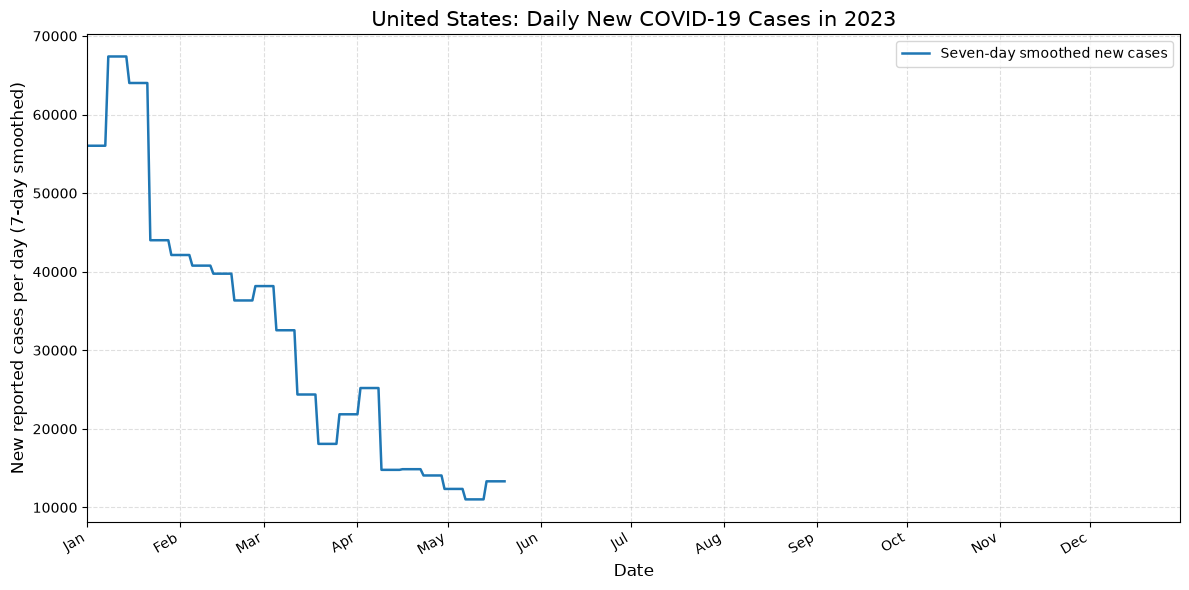

In [53]:

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 1. Load the dataset
df = pd.read_csv("owid-covid-data.csv")

# 2. Convert dates and ensure the case measure is numeric
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["new_cases_smoothed"] = pd.to_numeric(
    df["new_cases_smoothed"], errors="coerce"
)

# 3. Select only United States observations in calendar year 2023
start_date = pd.Timestamp("2023-01-01")
end_date = pd.Timestamp("2023-12-31")

us = df.loc[
    (df["location"] == "United States")
    & (df["iso_code"] == "USA")
    & (df["date"] >= start_date)
    & (df["date"] <= end_date)
].copy()

# Check that the selection contains data
if us.empty:
    raise ValueError(
        "No United States records were found for 2023. "
        "Check the file, date values, and location labels."
    )

# 4. Check that there is only one row per date
if us["date"].duplicated().any():
    duplicate_dates = us.loc[
        us["date"].duplicated(keep=False), "date"
    ].dt.strftime("%Y-%m-%d").unique()

    raise ValueError(
        f"Duplicate United States dates found: {duplicate_dates}. "
        "Inspect these rows before plotting."
    )

# 5. Create a daily time series, sorted chronologically
cases = (
    us.set_index("date")["new_cases_smoothed"]
    .sort_index()
)

# Include every date in 2023 without filling missing values with zero
all_dates = pd.date_range(
    start=start_date,
    end=end_date,
    freq="D"
)
cases = cases.reindex(all_dates)

if cases.notna().sum() == 0:
    raise ValueError(
        "The new_cases_smoothed column has no usable observations "
        "for the United States in 2023."
    )

# 6. Plot the trend
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    cases.index,
    cases.values,
    linewidth=1.8,
    label="Seven-day smoothed new cases"
)

ax.set_title(
    "United States: Daily New COVID-19 Cases in 2023",
    fontsize=15
)
ax.set_xlabel("Date", fontsize=12)
ax.set_ylabel(
    "New reported cases per day (7-day smoothed)",
    fontsize=12
)

# Show monthly ticks
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

ax.set_xlim(start_date, end_date)
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()

plt.show()


**Assessment: Valid – choice stated.** ChatGPT plotted the seven-day smoothed daily case count for the United States across the full calendar year, fixing the x-axis from 1 January to 31 December 2023, and stated that missing values would be left missing rather than replaced with zero so that gaps remain visible. Because US case reporting in this dataset ends on 20 May 2023, the line falls from a January peak of about 67,000 to about 13,000 cases per day and then stops, leaving June to December visibly empty. This avoids both versions of the trap: cases do not appear to fall to zero, and the missing months are not hidden. The response does not state that US reporting ended, so the reader must infer the reason for the gap. In the baseline, the x-axis was trimmed to May without explanation, a Silent analytical error.

### T25 (state choices). Is there a link between the share of older people and COVID death rates?

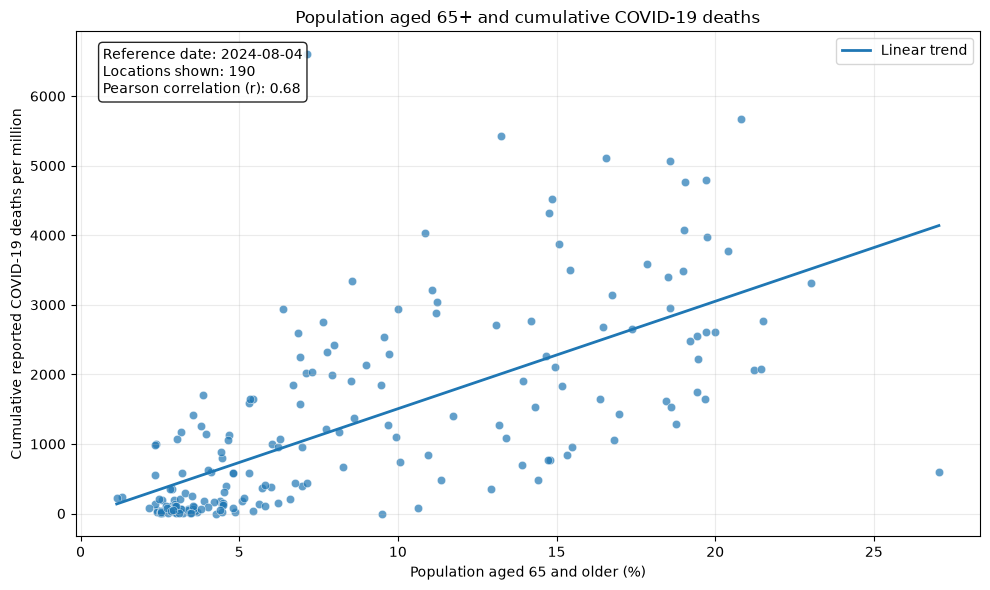

Reference date: 2024-08-04
Eligible locations overall: 190
Locations included in the chart: 190
Pearson correlation: 0.68
Saved chart to: C:\Users\julie\Pilot\covid_deaths_vs_older_share.png


In [54]:
from pathlib import Path
import math

import pandas as pd
import matplotlib.pyplot as plt


# --------------------------------------------------
# 1. Settings
# --------------------------------------------------

FILE_PATH = Path("owid-covid-data.csv")
COVERAGE_THRESHOLD = 0.80  # Require at least 80% coverage

AGE_COL = "aged_65_older"
DEATH_COL = "total_deaths_per_million"

REQUIRED_COLS = {
    "iso_code",
    "continent",
    "location",
    "date",
    AGE_COL,
    DEATH_COL,
}


# --------------------------------------------------
# 2. Load and validate the data
# --------------------------------------------------

if not FILE_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {FILE_PATH.resolve()}. "
        "Place the CSV in the current working directory "
        "or update FILE_PATH."
    )

df = pd.read_csv(FILE_PATH, low_memory=False)

missing_cols = REQUIRED_COLS.difference(df.columns)

if missing_cols:
    raise ValueError(
        f"The CSV is missing required columns: "
        f"{sorted(missing_cols)}"
    )

# Parse dates and ensure the two measures are numeric.
df["date"] = pd.to_datetime(df["date"], errors="coerce")

for col in [AGE_COL, DEATH_COL]:
    df[col] = pd.to_numeric(df[col], errors="coerce")


# --------------------------------------------------
# 3. Keep country and territory rows
# --------------------------------------------------

# Aggregate rows, such as the world and continents,
# generally lack a country-level continent classification
# and use OWID_ codes.

country_rows = df.loc[
    df["continent"].notna()
    & df["iso_code"].notna()
    & ~df["iso_code"].astype(str).str.startswith("OWID_")
    & df["date"].notna()
].copy()


# --------------------------------------------------
# 4. Identify locations with usable data
# --------------------------------------------------

# A location is eligible if both measures exist on
# at least one date in the dataset.

complete = country_rows.dropna(
    subset=[AGE_COL, DEATH_COL]
)

eligible_count = complete["iso_code"].nunique()

if eligible_count < 2:
    raise ValueError(
        "Fewer than two countries or territories have "
        "both required measures. Check the input data."
    )

# Count locations with BOTH measures available on
# each date. Counting ISO codes avoids counting a
# location more than once on the same date.

coverage_by_date = (
    complete.groupby("date")["iso_code"]
    .nunique()
)

required_count = math.ceil(
    COVERAGE_THRESHOLD * eligible_count
)

# Choose the latest date meeting the coverage threshold.
suitable_dates = coverage_by_date[
    coverage_by_date >= required_count
]

if not suitable_dates.empty:
    reference_date = suitable_dates.index.max()

else:
    # If no date reaches 80% coverage, choose the date
    # with the greatest coverage. If several dates tie,
    # choose the latest and print a warning.

    max_coverage = coverage_by_date.max()

    reference_date = coverage_by_date[
        coverage_by_date == max_coverage
    ].index.max()

    print(
        "Warning: No date meets the requested "
        f"{COVERAGE_THRESHOLD:.0%} coverage threshold. "
        f"Using the latest date with maximum coverage "
        f"({max_coverage} of {eligible_count} eligible "
        "locations)."
    )


# --------------------------------------------------
# 5. Select one observation per location on that date
# --------------------------------------------------

plot_df = country_rows.loc[
    country_rows["date"] == reference_date
].dropna(
    subset=[AGE_COL, DEATH_COL]
).copy()

# The dataset is expected to have one row per location
# per date. Retain one row per ISO code as a safeguard
# against accidental duplicate country observations.

plot_df = plot_df.drop_duplicates(
    subset=["iso_code"],
    keep="last"
)

if len(plot_df) < 2:
    raise ValueError(
        "Fewer than two locations have both measures "
        "on the selected reference date."
    )

# Shorter variable names for plotting.
x = plot_df[AGE_COL]
y = plot_df[DEATH_COL]

# Pearson correlation measures the strength and direction
# of the linear association.
pearson_r = x.corr(y, method="pearson")


# --------------------------------------------------
# 6. Create the scatter plot and trend line
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    x,
    y,
    alpha=0.7,
    edgecolors="white",
    linewidths=0.4
)

# Add an ordinary least-squares linear trend line.
# pandas covariance / variance gives the fitted slope.

if x.nunique() > 1:
    slope = x.cov(y) / x.var()
    intercept = y.mean() - slope * x.mean()

    x_line = [x.min(), x.max()]
    y_line = [
        slope * x_line[0] + intercept,
        slope * x_line[1] + intercept,
    ]

    ax.plot(
        x_line,
        y_line,
        linewidth=2,
        label="Linear trend"
    )

    ax.legend()

# Report key details directly on the chart.
r_text = (
    f"{pearson_r:.2f}"
    if pd.notna(pearson_r)
    else "undefined"
)

annotation = (
    f"Reference date: {reference_date:%Y-%m-%d}\n"
    f"Locations shown: {len(plot_df)}\n"
    f"Pearson correlation (r): {r_text}"
)

ax.text(
    0.03,
    0.97,
    annotation,
    transform=ax.transAxes,
    ha="left",
    va="top",
    bbox={
        "boxstyle": "round",
        "facecolor": "white",
        "alpha": 0.85,
    }
)

ax.set_title(
    "Population aged 65+ and cumulative COVID-19 deaths"
)

ax.set_xlabel(
    "Population aged 65 and older (%)"
)

ax.set_ylabel(
    "Cumulative reported COVID-19 deaths per million"
)

ax.grid(True, alpha=0.25)

fig.tight_layout()

# Save a high-resolution copy and display it.
fig.savefig(
    "covid_deaths_vs_older_share.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# --------------------------------------------------
# 7. Print the analysis details
# --------------------------------------------------

print(f"Reference date: {reference_date:%Y-%m-%d}")
print(f"Eligible locations overall: {eligible_count}")
print(f"Locations included in the chart: {len(plot_df)}")
print(f"Pearson correlation: {r_text}")
print(
    "Saved chart to: "
    f"{Path('covid_deaths_vs_older_share.png').resolve()}"
)

**Assessment: Valid – choice stated.** ChatGPT plotted the share of the population aged 65 and older against cumulative deaths per million, rejecting total deaths because they favour larger populations. It compared all locations on a single reference date, selected automatically as the latest date on which at least 80% of eligible locations had both measures (4 August 2024; 190 locations), and explicitly avoided treating each country's daily rows as separate observations. The chart reports the reference date, sample size and correlation directly. The relationship is strongly positive (Pearson r = 0.68). The response cautioned that correlation does not establish causation, that country-level averages do not describe individual risk, and that outliers can influence the trend line. In the baseline, the same question was also answered validly.

### C01 (state choices). Plot the 7-day average of new COVID cases in Germany during 2021, using the new_cases_smoothed column.

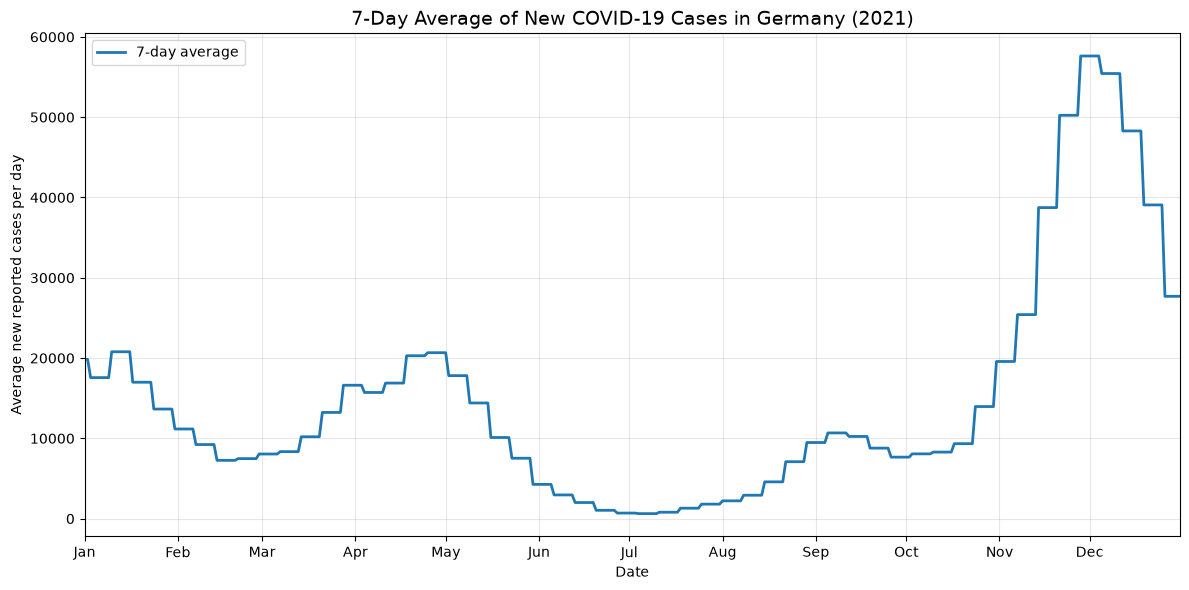

In [55]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 1. Load the dataset
df = pd.read_csv("owid-covid-data.csv", low_memory=False)

# 2. Convert the relevant columns to the correct data types
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["new_cases_smoothed"] = pd.to_numeric(
    df["new_cases_smoothed"], errors="coerce"
)

# 3. Select Germany's observations and the required columns
germany = df.loc[
    df["location"].eq("Germany"),
    ["date", "new_cases_smoothed"]
].dropna(subset=["date"])

# 4. Filter to the calendar year 2021 and sort chronologically
germany_2021 = (
    germany.loc[
        germany["date"].between("2021-01-01", "2021-12-31")
    ]
    .sort_values("date")
    .set_index("date")
)

# Check that the dataset contains usable observations for this period
if germany_2021.empty:
    raise ValueError(
        "No observations for Germany were found during 2021."
    )

if germany_2021["new_cases_smoothed"].notna().sum() == 0:
    raise ValueError(
        "No valid new_cases_smoothed values were found for Germany in 2021."
    )

# 5. Include every calendar day so missing dates appear as gaps
all_dates = pd.date_range(
    start="2021-01-01",
    end="2021-12-31",
    freq="D"
)

germany_2021 = germany_2021.reindex(all_dates)
germany_2021.index.name = "date"

# 6. Create the line chart
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    germany_2021.index,
    germany_2021["new_cases_smoothed"],
    linewidth=2,
    label="7-day average"
)

# 7. Add chart title, axis labels, and formatting
ax.set_title(
    "7-Day Average of New COVID-19 Cases in Germany (2021)",
    fontsize=14
)
ax.set_xlabel("Date")
ax.set_ylabel("Average new reported cases per day")

# Display one tick per month
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

ax.set_xlim(
    pd.Timestamp("2021-01-01"),
    pd.Timestamp("2021-12-31")
)

ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

# 8. Display the chart
plt.show()

**Assessment: Valid.** This is a fully specified control question. ChatGPT used the requested new_cases_smoothed column without re-smoothing it, plotted absolute daily counts for Germany across all of 2021, and preserved any missing values as gaps rather than zeros. The chart shows a summer low in early July (about 600 cases per day) and the fourth-wave peak in late November (about 57,600 cases per day). The stated choices and caveats were appropriate and did not alter the requested analysis. In the baseline, the same question was also answered validly, so the state-choices prompt did not degrade performance on this simple task.

### C02 (state choices). Plot total COVID deaths per million over time for France, Germany, Italy and Spain.

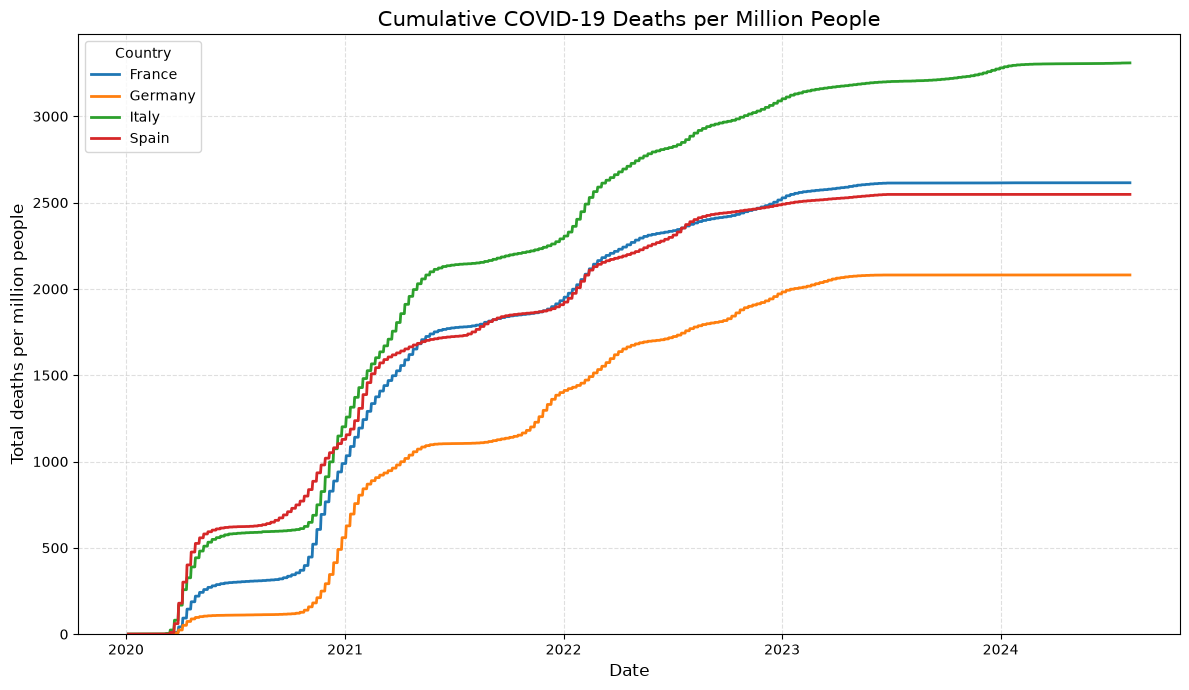

In [56]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# --------------------------------------------------
# 1. Load the dataset
# --------------------------------------------------
file_path = "owid-covid-data.csv"
df = pd.read_csv(file_path)

# Convert dates to datetime values.
# Unparseable dates become missing values.
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Ensure the measure is numeric.
# Missing or invalid values become NaN.
df["total_deaths_per_million"] = pd.to_numeric(
    df["total_deaths_per_million"],
    errors="coerce"
)

# --------------------------------------------------
# 2. Select the four countries
# --------------------------------------------------
countries = ["France", "Germany", "Italy", "Spain"]

plot_df = df.loc[
    df["location"].isin(countries),
    ["location", "date", "total_deaths_per_million"]
].copy()

# Exclude rows with invalid dates.
# Do not remove missing death-rate values: keeping them as NaN
# allows the plot to show gaps rather than inventing data.
plot_df = plot_df.dropna(subset=["date"])

if plot_df.empty:
    raise ValueError(
        "No matching country records found. "
        "Check the CSV file and the location names."
    )

# --------------------------------------------------
# 3. Check for duplicate country-date records
# --------------------------------------------------
duplicates = plot_df.duplicated(
    subset=["location", "date"],
    keep=False
)

if duplicates.any():
    duplicate_rows = plot_df.loc[duplicates].sort_values(
        ["location", "date"]
    )
    raise ValueError(
        "Duplicate country-date records found. "
        "Inspect these rows before plotting:\n"
        f"{duplicate_rows.to_string(index=False)}"
    )

# --------------------------------------------------
# 4. Plot cumulative deaths per million over time
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 7))

for country in countries:
    country_df = (
        plot_df.loc[plot_df["location"] == country]
        .sort_values("date")
    )

    if country_df.empty:
        print(f"Warning: No records found for {country}.")
        continue

    ax.plot(
        country_df["date"],
        country_df["total_deaths_per_million"],
        label=country,
        linewidth=2
    )

# --------------------------------------------------
# 5. Format the chart
# --------------------------------------------------
ax.set_title(
    "Cumulative COVID-19 Deaths per Million People",
    fontsize=15
)
ax.set_xlabel("Date", fontsize=12)
ax.set_ylabel("Total deaths per million people", fontsize=12)

# Use a shared scale starting at zero.
ax.set_ylim(bottom=0)

# Format the date axis for readability.
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
ax.xaxis.set_major_formatter(
    mdates.ConciseDateFormatter(ax.xaxis.get_major_locator())
)

ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(title="Country")
fig.tight_layout()

# Display the chart.
plt.show()

**Assessment: Valid.** This is a fully specified control question. ChatGPT plotted the requested total_deaths_per_million column for the four named countries on a shared axis starting at zero, selected by exact location names, checked for duplicate country-date records (none found) and left missing values as gaps. By the end of the series, Italy has the highest cumulative rate (about 3,309 per million), followed by France (2,615), Spain (2,548) and Germany (2,081). The response added an appropriate caveat that per-million rates are not age-standardised. In the baseline, the same question was also answered validly, so the state-choices prompt did not degrade performance.

### C03 (state choices). Make a scatter plot of median age against total COVID deaths per million, one point per country, excluding the regional and income-group rows.

Number of countries plotted: 196
Latest observation dates range from 2024-08-04 to 2024-08-04


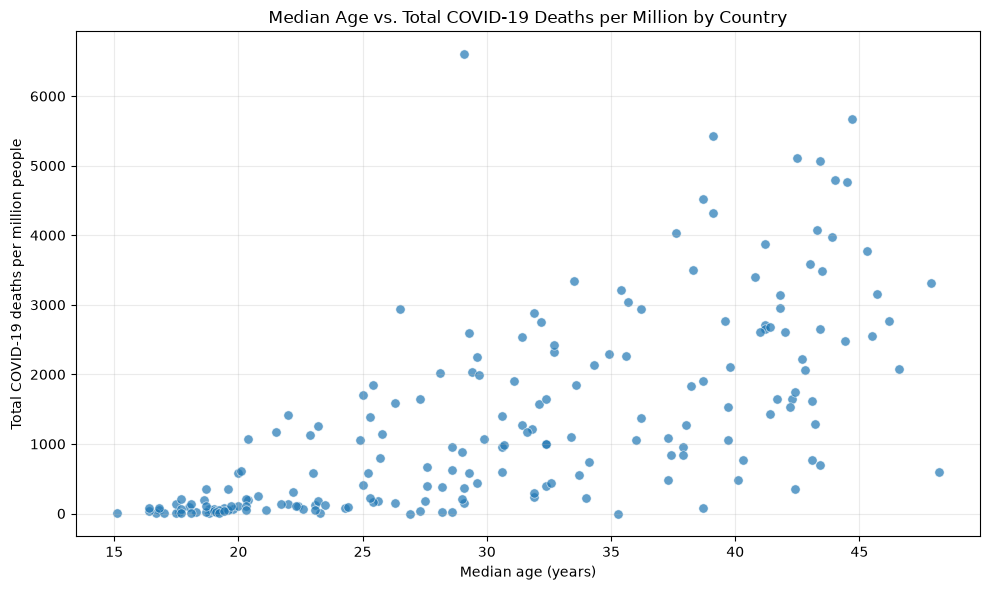

In [57]:
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Load the dataset
# --------------------------------------------------
df = pd.read_csv(
    "owid-covid-data.csv",
    parse_dates=["date"]
)

# Make sure the variables used in the plot are numeric.
for col in ["median_age", "total_deaths_per_million"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# --------------------------------------------------
# 2. Keep country-level rows
# --------------------------------------------------
# Standard three-letter ISO codes identify country rows.
# OWID_KOS is included as an exception for Kosovo.
iso = df["iso_code"].astype("string")

is_country = iso.str.fullmatch(r"[A-Z]{3}", na=False)
is_kosovo = iso.eq("OWID_KOS")

countries = df[is_country | is_kosovo].copy()

# --------------------------------------------------
# 3. Remove rows missing the required measurements
# --------------------------------------------------
usable = countries.dropna(
    subset=[
        "date",
        "median_age",
        "total_deaths_per_million"
    ]
)

# --------------------------------------------------
# 4. Keep the latest usable observation per country
# --------------------------------------------------
latest = (
    usable
    .sort_values("date")
    .groupby("iso_code", group_keys=False)
    .tail(1)
    .copy()
)

# Sort for a consistent output.
latest = latest.sort_values("location")

# Check that there is only one point per country.
assert latest["iso_code"].is_unique

print(f"Number of countries plotted: {len(latest)}")
print(f"Latest observation dates range from "
      f"{latest['date'].min().date()} to "
      f"{latest['date'].max().date()}")

# --------------------------------------------------
# 5. Create the scatter plot
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    latest["median_age"],
    latest["total_deaths_per_million"],
    alpha=0.7,
    s=45,
    edgecolors="white",
    linewidths=0.5
)

ax.set_title(
    "Median Age vs. Total COVID-19 Deaths per Million by Country"
)

ax.set_xlabel("Median age (years)")
ax.set_ylabel("Total COVID-19 deaths per million people")

ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

**Assessment: Valid.** This is a fully specified control question. ChatGPT plotted median age against total deaths per million using the latest usable observation for each country, excluded aggregates by keeping standard three-letter ISO codes (with an explicit exception for Kosovo, which is dropped because it lacks a median-age value), and enforced one point per country with an assertion. All 196 plotted countries share the same observation date (4 August 2024), and the chart shows a strong positive association, consistent with the share-aged-65+ result in T25. The response added appropriate caveats on reporting differences and causation. ChatGPT's separate installation instruction (pip install pandas matplotlib) was not part of the script and was not run in the notebook. In the baseline, the same question was also answered validly, so the state-choices prompt did not degrade performance.